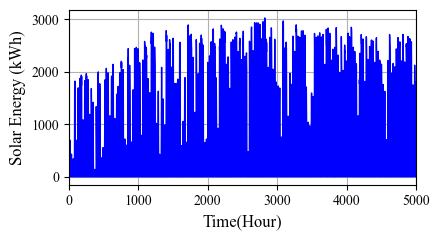

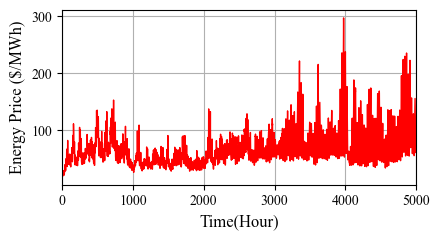

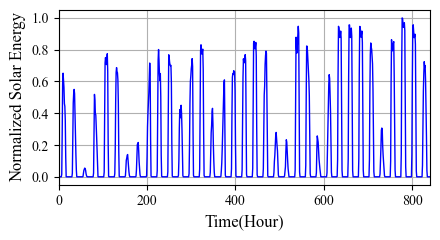

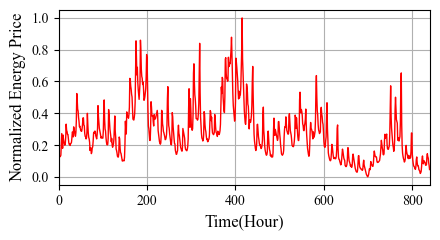

In [1]:
#!pip install pandas
#pip install seaborn
import os
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import math
from scipy import stats as _stats
from sklearn.metrics import mean_squared_error, mean_absolute_error
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams.update({
    "axes.titlesize": 12,   # title font size
    "axes.labelsize": 12,   # x and y label size
    "xtick.labelsize": 10,  # x tick label size
    "ytick.labelsize": 10   # y tick label size
})

mpl.rcParams['savefig.transparent'] = False

base_path = '.'                             # folder containing this notebook
image_dir = 'images'                        # figures are saved here
full_image_path = os.path.join(base_path, image_dir)
os.makedirs(full_image_path, exist_ok=True)


# Helper function to save figures
def save_figure(filename):
    """Saves the current matplotlib figure to the predefined path."""
    save_path = os.path.join(full_image_path, filename)
    plt.savefig(save_path)


#
file_path = 'solar.csv'
# Read the CSV file into a pandas DataFrame
solar_data = pd.read_csv(file_path)
#print(solar_data.head())
solar_generation_kw = np.array(solar_data['solar_generation_kw']) #solar_generation_mw
#print(solar_generation_mw)
solar_generation_kw = np.where(solar_generation_kw < 0, 0, solar_generation_kw)

solar_generation_kw_120 = solar_generation_kw[:120]
#print(solar_generation_mw_120)
#
#
#
file_path = 'price.csv'
# Read the CSV file into a pandas DataFrame
price_data = pd.read_csv(file_path)
#print(price_data.head())
energy_price_usd = np.array(price_data['system_energy_price_da']) #system_energy_price_da
energy_price_usd = np.where(energy_price_usd < 0, 0, energy_price_usd)
#print(energy_price_usd)
#
#
#
start_index = 312
num_values = 840

# Extract the specified range of values
solar_generation_subset = solar_generation_kw[start_index : start_index + num_values] #solar data

energy_price_usd_subset = energy_price_usd[start_index : start_index + num_values]

s_max = np.max(solar_generation_subset)
s_min = np.min(solar_generation_subset)
solar_data_norm = (solar_generation_subset - s_min) / (s_max-s_min)

#print('Original Solar Data')
#print(solar_data)

p_max=np.max(energy_price_usd_subset)
p_min=np.min(energy_price_usd_subset)
price_data_norm = (energy_price_usd_subset - p_min) / (p_max - p_min)

# Plot the full data
plt.figure(figsize=(4.5, 2.5))
plt.plot(solar_generation_kw[:5000], color='b', linewidth=1)
plt.xlim(0, len(solar_generation_kw[:5000]))
plt.xlabel('Time(Hour)')
plt.ylabel('Solar Energy (kWh)')
plt.grid(True)
plt.tight_layout()
save_figure('solar.eps')

plt.figure(figsize=(4.5, 2.5))
plt.plot(energy_price_usd[:5000], color='r', linewidth=1)
plt.xlim(0, len(energy_price_usd[:5000]))
plt.xlabel('Time(Hour)')
plt.ylabel('Energy Price ($/MWh)')
plt.grid(True)
plt.tight_layout()
save_figure('price.eps')

# Plot the full data
plt.figure(figsize=(4.5, 2.5))
plt.plot(solar_data_norm, color='b', linewidth=1)
plt.xlim(0, len(solar_data_norm))
plt.xlabel('Time(Hour)')
plt.ylabel('Normalized Solar Energy')
plt.grid(True)
plt.tight_layout()
save_figure('solar_use.eps')


plt.figure(figsize=(4.5, 2.5))
plt.plot(price_data_norm, color='r', linewidth=1)
plt.xlim(0, len(price_data_norm))
plt.xlabel('Time(Hour)')
plt.ylabel('Normalized Energy Price')
plt.grid(True)
plt.tight_layout()
save_figure('price_use.eps')



Solar Prediction (FFNN) RMSE: 0.0721
Solar Prediction (FFNN) MAE:  0.0374

Solar Baselines (normalized)
Solar Persistence   RMSE: 0.1516, MAE: 0.0722
Solar Seasonal(24h) RMSE: 0.1917, MAE: 0.0903


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.



Price Prediction (FFNN) RMSE: 0.0575
Price Prediction (FFNN) MAE:  0.0467

Price Baselines (normalized)
Price Persistence   RMSE: 0.0497, MAE: 0.0276
Price Seasonal(24h) RMSE: 0.1005, MAE: 0.0754

================ Summary Table (Normalized) ================
Model                     | PV RMSE | PV MAE | Price RMSE | Price MAE
------------------------------------------------------------
Persistence (B1)          |  0.1516 | 0.0722 |    0.0497 |   0.0276
Seasonal persistence (B2) |  0.1917 | 0.0903 |    0.1005 |   0.0754
FFNN (1-step)             |  0.0721 | 0.0374 |    0.0575 |   0.0467


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


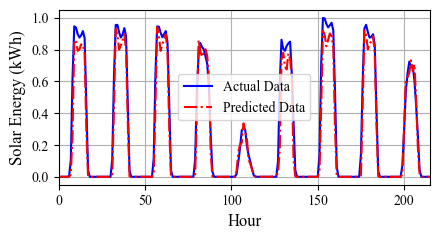

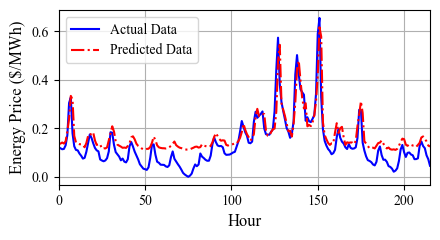

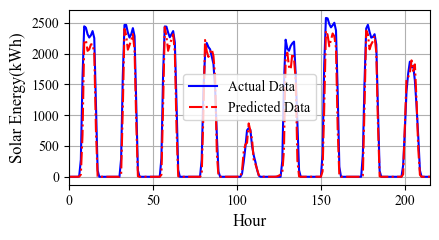

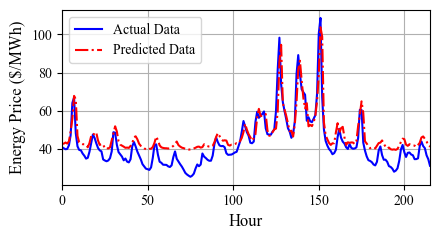

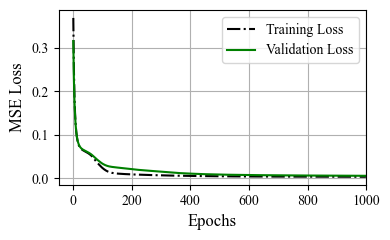

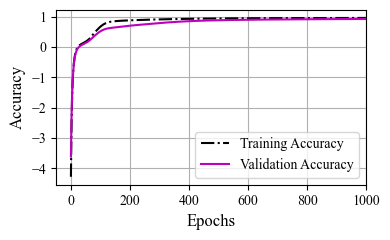

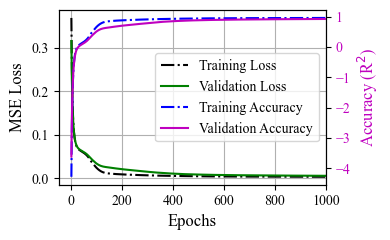

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


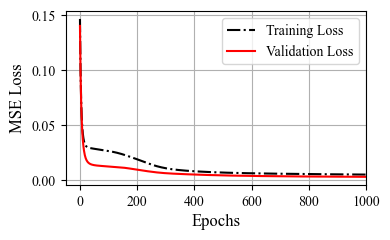

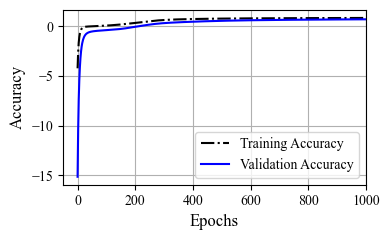

In [2]:
np.random.seed(42)
# Activation function and its derivative (ReLU)

def leaky_relu(x, alpha):
    return np.where(x > 0, x, alpha * x)

def leaky_relu_derivative(x, alpha):
    return np.where(x > 0, 1, alpha)

def huber_loss(y_true, y_pred, delta = 100):
    error = y_true - y_pred
    is_small_error = np.abs(error) <= delta
    squared_loss = 0.5 * error**2
    linear_loss = delta * (np.abs(error) - 0.5 * delta)
    return np.mean(np.where(is_small_error, squared_loss, linear_loss))

def huber_loss_derivative(y_true, y_pred, delta =100):
    error = y_true - y_pred
    derivative = np.where(np.abs(error) <= delta, -error, -delta * np.sign(error))
    return derivative / y_true.size

def softplus(x):
    return np.log1p(np.exp(x))

def softplus_derivative(x):
    return 1 / (1 + np.exp(-x))

def mse_loss(y_true, y_pred, W1=None, W2=None, lambda_reg=0.001):
    mse = np.mean((y_true - y_pred) ** 2)
    if W1 is not None and W2 is not None:
        l2 = lambda_reg * (np.sum(W1**2) + np.sum(W2**2))
        return mse + l2
    return mse

def mse_loss_derivative(y_true, y_pred):
    return 2 * (y_pred - y_true) / y_true.size


Losses = []

# Neural network class definition
class CustomNeuralNetwork:
    def __init__(self, input_size, hidden_size, output_size, learning_rate):
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.learning_rate = learning_rate

        self.W1 = np.random.randn(self.input_size, self.hidden_size) * 0.1
        self.b1 = np.zeros((1, self.hidden_size))
        self.W2 = np.random.randn(self.hidden_size, self.hidden_size) * 0.1
        self.b2 = np.zeros((1, self.hidden_size))
        self.W3 = np.random.randn(self.hidden_size, self.output_size) * 0.1
        self.b3 = np.zeros((1, self.output_size))

    def forward(self, X):
        self.Z1 = np.dot(X, self.W1) + self.b1
        self.A1 = leaky_relu(self.Z1, alpha=0.01)
        self.Z2 = np.dot(self.A1, self.W2) + self.b2
        self.A2 = leaky_relu(self.Z2, alpha=0.01)
        self.Z3 = np.dot(self.A2, self.W3) + self.b3
        self.A3 = softplus(self.Z3)
        return self.A3

    def backward(self, X, Y, output):
        loss_grad = mse_loss_derivative(Y, output)

        dW3 = np.dot(self.A2.T, loss_grad)
        db3 = np.sum(loss_grad, axis=0, keepdims=True)

        hidden_grad2 = np.dot(loss_grad, self.W3.T) * leaky_relu_derivative(self.Z2, alpha=0.001)
        dW2 = np.dot(self.A1.T, hidden_grad2)
        db2 = np.sum(hidden_grad2, axis=0, keepdims=True)

        hidden_grad1 = np.dot(hidden_grad2, self.W2.T) * leaky_relu_derivative(self.Z1, alpha=0.001)
        dW1 = np.dot(X.T, hidden_grad1)
        db1 = np.sum(hidden_grad1, axis=0, keepdims=True)

        self.W1 -= self.learning_rate * dW1
        self.b1 -= self.learning_rate * db1
        self.W2 -= self.learning_rate * dW2
        self.b2 -= self.learning_rate * db2
        self.W3 -= self.learning_rate * dW3
        self.b3 -= self.learning_rate * db3

    def accuracy(self, y_true, y_pred):
        ss_res = np.sum((y_true - y_pred) ** 2)
        ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
        return 1 - ss_res / (ss_tot + 1e-6)   # R² score

    def train(self, X_train, Y_train, X_val, Y_val, epochs):
        train_losses, val_losses = [], []
        train_accs, val_accs = [], []

        for epoch in range(epochs):
            # ---- Training forward + backward ----
            output_train = self.forward(X_train)
            loss_train = mse_loss(Y_train, output_train, W1=None, W2=None, lambda_reg=0.001)
            acc_train = self.accuracy(Y_train, output_train)

            self.backward(X_train, Y_train, output_train)  # update weights using train set only

            # ---- Validation forward only ----
            output_val = self.forward(X_val)
            loss_val = mse_loss(Y_val, output_val, W1=None, W2=None, lambda_reg=0.001)
            acc_val = self.accuracy(Y_val, output_val)

            # Store history
            train_losses.append(loss_train)
            val_losses.append(loss_val)
            train_accs.append(acc_train)
            val_accs.append(acc_val)

        return train_losses, val_losses, train_accs, val_accs


# Number of hours in a day
n_hours = 24
n_days = len(solar_data_norm) // n_hours
train_days = 25
test_days = n_days - train_days

# ------------------------------
# Prepare training data (hour by hour)
# Input: 24 hours
# Output: next 1 hour
# ------------------------------
Xs, Ys, Xp, Yp = [], [], [], []

for i in range(train_days * n_hours - n_hours - 1):
    Xs.append(solar_data_norm[i:i+n_hours])       # past 24h
    Ys.append(solar_data_norm[i+n_hours])         # next 1h
    Xp.append(price_data_norm[i:i+n_hours])       # past 24h
    Yp.append(price_data_norm[i+n_hours])         # next 1h

Xs = np.array(Xs)
Ys = np.array(Ys).reshape(-1, 1)  # (samples, 1)
Xp = np.array(Xp)
Yp = np.array(Yp).reshape(-1, 1)

val_ratio = 0.2
split_idx = int(len(Xs) * (1 - val_ratio))

Xs_train, Ys_train = Xs[:split_idx], Ys[:split_idx]
Xs_val, Ys_val = Xs[split_idx:], Ys[split_idx:]

# ------------------------------
# Initialize custom NNs (Solar)
# ------------------------------
nns = CustomNeuralNetwork(input_size=24, hidden_size=24, output_size=1, learning_rate=0.1)
train_losses_solar, val_losses_solar, train_accs_solar, val_accs_solar = nns.train(
    Xs_train, Ys_train, Xs_val, Ys_val, epochs=5000
)
train_losses_solar = train_losses_solar[0:1000]
val_losses_solar   = val_losses_solar[0:1000]
train_accs_solar   = train_accs_solar[0:1000]
val_accs_solar     = val_accs_solar[0:1000]

# ------------------------------
# Prepare testing data
# ------------------------------
Xst, Yst, Xpt, Ypt = [], [], [], []

for i in range(train_days * n_hours, (train_days + test_days) * n_hours - n_hours):
    Xst.append(solar_data_norm[i:i+n_hours])
    Yst.append(solar_data_norm[i+n_hours])
    Xpt.append(price_data_norm[i:i+n_hours])
    Ypt.append(price_data_norm[i+n_hours])

Xst = np.array(Xst)
Yst = np.array(Yst).reshape(-1, 1)
Xpt = np.array(Xpt)
Ypt = np.array(Ypt).reshape(-1, 1)

# ------------------------------
# Solar: Hour-by-hour prediction (FFNN)
# ------------------------------
solar_predicted = []

for i in range(len(Xst)):
    prediction = nns.forward(Xst[i].reshape(1, -1))
    solar_predicted.append(prediction.flatten()[0])

solar_actual = Yst.flatten()
solar_predicted = np.array(solar_predicted)

rmse_solar = np.sqrt(mean_squared_error(solar_actual, solar_predicted))
mae_solar = mean_absolute_error(solar_actual, solar_predicted)

print(f"Solar Prediction (FFNN) RMSE: {rmse_solar:.4f}")
print(f"Solar Prediction (FFNN) MAE:  {mae_solar:.4f}")

# ------------------------------
# Baselines: Persistence + Seasonal Persistence (Solar)
# ------------------------------
# B1: Plain persistence -> y_hat(t+1) = y(t)  -> last element of the 24h window
solar_persist_pred = Xst[:, -1]

# B2: Daily seasonal persistence -> y_hat(t+1) = y(t+1-24) -> first element of the 24h window
solar_seasonal_pred = Xst[:, 0]

rmse_solar_persist = np.sqrt(mean_squared_error(solar_actual, solar_persist_pred))
mae_solar_persist  = mean_absolute_error(solar_actual, solar_persist_pred)

rmse_solar_seasonal = np.sqrt(mean_squared_error(solar_actual, solar_seasonal_pred))
mae_solar_seasonal  = mean_absolute_error(solar_actual, solar_seasonal_pred)

print("\nSolar Baselines (normalized)")
print(f"Solar Persistence   RMSE: {rmse_solar_persist:.4f}, MAE: {mae_solar_persist:.4f}")
print(f"Solar Seasonal(24h) RMSE: {rmse_solar_seasonal:.4f}, MAE: {mae_solar_seasonal:.4f}")


# ------------------------------
# Initialize custom NNs (Price)
# ------------------------------
val_ratio = 0.2
split_idx = int(len(Xs) * (1 - val_ratio))

Xp_train, Yp_train = Xp[:split_idx], Yp[:split_idx]
Xp_val, Yp_val = Xp[split_idx:], Yp[split_idx:]

nnp = CustomNeuralNetwork(input_size=24, hidden_size=24, output_size=1, learning_rate=0.1)
train_losses_price, val_losses_price, train_accs_price, val_accs_price = nnp.train(
    Xp_train, Yp_train, Xp_val, Yp_val, epochs=5000
)
train_losses_price = train_losses_price[0:1000]
val_losses_price   = val_losses_price[0:1000]
train_accs_price   = train_accs_price[0:1000]
val_accs_price     = val_accs_price[0:1000]

# ------------------------------
# Price: Hour-by-hour prediction (FFNN)
# ------------------------------
price_predicted = []

for i in range(len(Xpt)):
    pred = nnp.forward(Xpt[i].reshape(1, -1))
    price_predicted.append(pred.flatten()[0])

price_actual = Ypt.flatten()
price_predicted = np.array(price_predicted)

rmse_price = np.sqrt(mean_squared_error(price_actual, price_predicted))
mae_price = mean_absolute_error(price_actual, price_predicted)

print(f"\nPrice Prediction (FFNN) RMSE: {rmse_price:.4f}")
print(f"Price Prediction (FFNN) MAE:  {mae_price:.4f}")

# ------------------------------
# Baselines: Persistence + Seasonal Persistence (Price)
# ------------------------------
price_persist_pred  = Xpt[:, -1]  # B1
price_seasonal_pred = Xpt[:, 0]   # B2

rmse_price_persist = np.sqrt(mean_squared_error(price_actual, price_persist_pred))
mae_price_persist  = mean_absolute_error(price_actual, price_persist_pred)

rmse_price_seasonal = np.sqrt(mean_squared_error(price_actual, price_seasonal_pred))
mae_price_seasonal  = mean_absolute_error(price_actual, price_seasonal_pred)

print("\nPrice Baselines (normalized)")
print(f"Price Persistence   RMSE: {rmse_price_persist:.4f}, MAE: {mae_price_persist:.4f}")
print(f"Price Seasonal(24h) RMSE: {rmse_price_seasonal:.4f}, MAE: {mae_price_seasonal:.4f}")


# ------------------------------
# Optional: one clean summary table printout (console)
# ------------------------------
print("\n================ Summary Table (Normalized) ================")
print("Model                     | PV RMSE | PV MAE | Price RMSE | Price MAE")
print("------------------------------------------------------------")
print(f"Persistence (B1)          | {rmse_solar_persist:7.4f} | {mae_solar_persist:6.4f} | {rmse_price_persist:9.4f} | {mae_price_persist:8.4f}")
print(f"Seasonal persistence (B2) | {rmse_solar_seasonal:7.4f} | {mae_solar_seasonal:6.4f} | {rmse_price_seasonal:9.4f} | {mae_price_seasonal:8.4f}")
print(f"FFNN (1-step)             | {rmse_solar:7.4f} | {mae_solar:6.4f} | {rmse_price:9.4f} | {mae_price:8.4f}")
print("============================================================")

# Plot solar
plt.figure(figsize=(4.5, 2.5))
plt.plot(range(len(solar_actual)), solar_actual, label='Actual Data', linestyle = '-', color = 'b')
plt.plot(range(len(solar_predicted)), solar_predicted, label='Predicted Data', linestyle = '-.', color = 'r')
plt.xlim(0, len(solar_predicted)-1)
plt.xlabel('Hour')
plt.ylabel('Solar Energy (kWh)')
plt.legend()
plt.grid(True)
plt.tight_layout()
save_figure('solar_pred.eps')


# Plot price
plt.figure(figsize=(4.5, 2.5))
plt.plot(range(len(price_actual)), price_actual, label='Actual Data', linestyle = '-', color = 'b')
plt.plot(range(len(price_predicted)), price_predicted, label='Predicted Data', linestyle = '-.', color = 'r')
plt.xlim(0, len(price_predicted)-1)
plt.xlabel('Hour')
plt.ylabel('Energy Price ($/MWh)')
plt.legend()
plt.grid(True)
plt.tight_layout()
save_figure('price_pred.eps')


# Denormalized solar Data
solar_actual_data = solar_actual *(s_max - s_min) + s_min    
solar_predicted_data = solar_predicted *(s_max - s_min) + s_min

# Denormalized Price Data
price_actual_data = price_actual *(p_max - p_min) + p_min    
price_predicted_data = price_predicted *(p_max - p_min) + p_min



# Plot solar
plt.figure(figsize=(4.5, 2.5))
plt.plot(range(len(solar_actual_data)), solar_actual_data, label='Actual Data', linestyle = '-', color = 'b')
plt.plot(range(len(solar_predicted_data)), solar_predicted_data, label='Predicted Data', linestyle = '-.', color = 'r')
plt.xlim(0, len(solar_predicted)-1)
plt.xlabel('Hour')
plt.ylabel('Solar Energy(kWh)')
plt.legend()
plt.grid(True)
plt.tight_layout()
save_figure('solar_pred_ac.eps')

# Plot price
plt.figure(figsize=(4.5, 2.5))
plt.plot(range(len(price_actual_data)), price_actual_data, label='Actual Data', linestyle = '-', color = 'b')
plt.plot(range(len(price_predicted_data)), price_predicted_data, label='Predicted Data', linestyle = '-.', color = 'r')
plt.xlim(0, len(price_predicted)-1)
plt.xlabel('Hour')
plt.ylabel('Energy Price ($/MWh)')
plt.legend()
plt.grid(True)
plt.tight_layout()
save_figure('price_pred_ac.eps')


plt.figure(figsize=(4, 2.5))
plt.plot(train_losses_solar, label="Training Loss", linestyle = '-.', color = 'k')
plt.plot(val_losses_solar, label="Validation Loss", color = 'g')
plt.xlim(-50, len(val_losses_solar))
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
save_figure('sloss.eps')

# ------------------------------
# Plot Training vs Validation Accuracy
# ------------------------------
plt.figure(figsize=(4, 2.5))
plt.plot(train_accs_solar, label="Training Accuracy", linestyle = '-.', color = 'k')
plt.plot(val_accs_solar, label="Validation Accuracy", color = 'm')
plt.xlim(-50, len(val_accs_solar))
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
save_figure('saccuracy.eps')


fig, ax1 = plt.subplots(figsize=(4, 2.5))

# --- Plot Losses on left y-axis ---
ax1.plot(train_losses_solar, label="Training Loss", linestyle='-.', color='k')
ax1.plot(val_losses_solar, label="Validation Loss", color='g')
ax1.set_xlabel("Epochs")
ax1.set_ylabel("MSE Loss", color='k')
ax1.tick_params(axis='y', labelcolor='k')
ax1.set_xlim(-50, len(val_losses_solar))

# --- Plot Accuracies on right y-axis ---
ax2 = ax1.twinx()
ax2.plot(train_accs_solar, label="Training Accuracy", linestyle='-.', color='b')
ax2.plot(val_accs_solar, label="Validation Accuracy", color='m')
ax2.set_ylabel("Accuracy (R$^2$)", color='m')
ax2.tick_params(axis='y', labelcolor='m')

# --- Title and grid ---
ax1.grid(True)

# --- Combine legends from both axes ---
lns1, labs1 = ax1.get_legend_handles_labels()
lns2, labs2 = ax2.get_legend_handles_labels()
ax1.legend(lns1 + lns2, labs1 + labs2, loc='center right')

fig.tight_layout()
save_figure("solar_loss_accuracy_combined.eps")
plt.show()



plt.figure(figsize=(4, 2.5))
plt.plot(train_losses_price, label="Training Loss", linestyle = '-.', color = 'k')
plt.plot(val_losses_price, label="Validation Loss", color = 'r')
plt.xlim(-50, len(val_losses_price))
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
save_figure('ploss.eps')

# ------------------------------
# Plot Training vs Validation Accuracy
# ------------------------------
plt.figure(figsize=(4, 2.5))
plt.plot(train_accs_price, label="Training Accuracy", linestyle = '-.', color = 'k')
plt.plot(val_accs_price, label="Validation Accuracy", color = 'b')
plt.xlim(-50, len(val_accs_price))
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
save_figure('paccuracy.eps')

In [3]:
# ── Store / reload the PV and price forecasts used by all experiments ─────────────────
FORECAST_FILE = "forecasts_seed42.npz"

if not os.path.exists(FORECAST_FILE):
    np.savez(FORECAST_FILE,
             solar_predicted_data=solar_predicted_data,
             price_predicted_data=price_predicted_data)
    print(f"Saved forecasts to {FORECAST_FILE}")
else:
    _f = np.load(FORECAST_FILE)
    solar_predicted_data = _f["solar_predicted_data"]
    price_predicted_data = _f["price_predicted_data"]
    print(f"Loaded fixed forecasts from {FORECAST_FILE}")

# Scale the PJM-South regional PV shape (MW) to a household rooftop system.
# Applied AFTER saving/loading, so the .npz always holds the raw forecasts.
PV_KWP = 7.0                     # rooftop PV rating (kWp)
solar_predicted_data = np.clip(solar_predicted_data, 0, None) / s_max * PV_KWP
print(f"PV scaled to a {PV_KWP} kWp rooftop system (peak forecast {np.max(solar_predicted_data):.2f} kW)")

print("PV  forecast checksum:", round(float(np.sum(solar_predicted_data)), 4))
print("Price forecast checksum:", round(float(np.sum(price_predicted_data)), 4))

Loaded fixed forecasts from forecasts_seed42.npz
PV scaled to a 7.0 kWp rooftop system (peak forecast 6.59 kW)
PV  forecast checksum: 360.4886
Price forecast checksum: 10204.0161


In [ ]:
# Parameters
num_agents = 9
num_hours = 24
learning_rate = 0.01
initial_epsilon = 0.5
min_epsilon = 0.05
epsilon_decay = 0.9985
initial_lr = 0.9
min_lr = 0.05
lr_decay = 0.995
discount_factor = 0.9
pv_utilization_factor = 0.7
episodes = 3000
lambda1 = 2.5  #15.0
lambda2 = 1.0   # 1.3
lambda3 = 0.5
delta1 = 0.0
melatonin_factor = 0.75
cortisol_factor = 1.0
USE_KALMAN = True      # False -> fixed learning rate (alpha = learning_rate = 0.01), for Fig. 13(b)


# Actions
agent_actions = [
    np.array([0.5]), # Agent 0: Refrigerator (small continuous power)
    np.round(np.arange(0.4, 1.5, 0.1), 2),  # Agent 1 (AC1)
    np.round(np.arange(0.4, 1.5, 0.1), 2),  # Agent 2 (AC2)
    np.round(np.arange(0.5, 1.6, 0.1), 2),  # Agent 3 (Heater)
    np.round(np.arange(0.2, 0.7, 0.1), 2),  # Agent 4 (Light1)
    np.round(np.arange(0.2, 0.7, 0.1), 2),   # Agent 5 (Light2)
    np.array([0.0, 0.7]),  # Agent 6: Washing Machine (0 or cycles with different power0
    np.array([0.0, 0.3]),  # Agent 7: Dishwasher (0 or cycles)
    np.array([-3.0, -2.0, -1.0, 0.0, 1.0, 2.0, 3.0])  #  Agent 9: Battery
    
]



# Agents
#labels = ['REF','AC1', 'AC2', 'Heater', 'Light1', 'Light2', 'WM', 'DW', 'EV']
# Agent-specific parameters
dissatisfaction_coefficients = [1, 0.05, 0.08, 0.12, 0.02, 0.03, 0.1, 0.06, 0.05 ] 
power_ranges = [0.5,1.4, 1.4, 1.5, 0.6, 0.6, 0.7, 0.3, 3.0]  # kWh
usable_time_ranges = [(0,23),(0,23),(0,23),(0,23),(18,23),(18,23),(19,22),(20,22),(0,23)]

def calculate_pv_power(time):
  exponent_numerator = -((time - 12)**2)
  exponent_denominator = (1 * (3**2))
  pv_power = 25 * math.exp(exponent_numerator / exponent_denominator)
  return max(0, pv_power)
idle_pv=np.zeros(24)
# Example usage for a 24-hour period:
for hour in range(24):
  power_output = calculate_pv_power(hour)
  idle_pv[hour] = power_output
  #print(f"Time: {hour:02d}:00, PV Power: {power_output:.2f}")

hourly_pv_power = solar_predicted_data[24:48].flatten()    # Mwh is converted to kWh by multiplying with 1000
hourly_energy_cost = price_predicted_data[24:48].flatten()/1000   # $/MWh -> $/kWh, same day as PV

# ----------------- Normalizer -----------------
def normalize(x):
    x = np.asarray(x, dtype=float)
    return (x - np.min(x)) / (np.max(x) - np.min(x) + 1e-8)

# Time vector (0-24 hours) at 0.1 h resolution for the hormone arrays
t = np.arange(0, 24, 0.1)

# ----------------- MELATONIN MODELS -----------------
# 1) Cosine circadian
M_cos = 0.6 + 0.4* np.cos(2*np.pi*(t - 3)/24)
M_cos = normalize(M_cos)

# 2) Light-Dark driven ODE
S = np.where((t >= 20) | (t <= 6), 1, 0)  # darkness synthesis
k_m = 0.2
M_ld = np.zeros_like(t)
for i in range(1, len(t)):
    dt_h = t[i] - t[i-1]
    M_ld[i] = M_ld[i-1] + dt_h * (-k_m * M_ld[i-1] + S[i])
M_ld = normalize(M_ld)

# 3) Pharmacokinetic single dose
D, V, ka, ke = 1.0, 1.0, 1.0, 0.3
M_pk = (D/V) * (ka/(ka - ke)) * (np.exp(-ke*t) - np.exp(-ka*t))
M_pk = np.clip(M_pk, 0, None)
M_pk = normalize(M_pk)

# ----------------- CORTISOL MODELS -----------------
# 1) Cosine circadian
C_cos = 0.5 + 0.5 * np.cos(2 * np.pi * (t - 8) / 24)
C_cos = normalize(C_cos)

# 2) Pulsatile secretion
C_pulse = np.zeros_like(t)
ti = [6, 10, 15, 20]     # pulse centers
Ai = [1.0, 0.6, 0.5, 0.3]
k = 1.5
for j in range(len(ti)):
    C_pulse += Ai[j] * np.exp(-k * np.maximum(t - ti[j], 0))
C_pulse = normalize(C_pulse)

# 3) Cortisol Awakening Response (Gaussian pulse on baseline)
C_car = np.exp(-((t - 8)**2) / (2*2**2))
C_car = normalize(C_car)

# ----------------- Hormone accessors -----------------
def get_melatonin(hour, model='cos'):
    idx = int(hour * 10) % len(t)  # hour is integer [0..23], map to 0.1h grid
    if model == 'cos':
        return float(M_cos[idx])
    elif model == 'ld':
        return float(M_ld[idx])
    elif model == 'pk':
        return float(M_pk[idx])
    else:
        # fallback: analytical cosine (normalized near [0,1]), or 1 if disabled elsewhere
        return float(0.5 + 0.5 * math.cos(2 * math.pi * (hour - 3) / 24.0))

def get_cortisol(hour, model='cos'):
    idx = int(hour * 10) % len(t)
    if model == 'cos':
        return float(C_cos[idx])
    elif model == 'pulse':
        return float(C_pulse[idx])
    elif model == 'car':
        return float(C_car[idx])
    else:
        # fallback: CAR-ish Gaussian at 8 AM
        return float(math.exp(-((hour - 8.0)**2) / (2*2.0**2)))

def get_time_weights(hour):
    # piecewise constants
    # adjust these blocks to match your tariff/PV patterns if needed
    if 17 <= hour <= 21:          # evening peak
        w_cost = 1.2
        w_bonus = 1.0
    elif 10 <= hour <= 16:        # PV window / daytime
        w_cost = 1.0
        w_bonus = 1.3
    else:                         # off-peak / normal
        w_cost = 0.9
        w_bonus = 1.0
    return w_cost, w_bonus



# Agents
labels = ['REF','AC1', 'AC2', 'Heater', 'Light1', 'Light2', 'WM', 'DW','Battery']


# ================== Consumer profile + single comfort-setpoint definition ==================
# Default profile reproduces the original setpoints exactly.
#   shift : hours the occupant schedule is shifted (late riser = +2)
#   scale : multiplier on base comfort setpoints (high-demand household = 1.2)
#   away  : (start, end) clock hours with reduced AC/heater base (working household), or None
#   away_factor : multiplier applied to AC/heater base during 'away'
CONSUMER_PROFILE = dict(name="Baseline", shift=0, scale=1.0, away=None, away_factor=1.0)

def _sched_hour(hour):
    return (hour - CONSUMER_PROFILE["shift"]) % 24

def _away_mult(hour):
    a = CONSUMER_PROFILE["away"]
    if a is not None and a[0] <= hour <= a[1]:
        return CONSUMER_PROFILE["away_factor"]
    return 1.0

def comfort_setpoint(agent, hour, pv_power, mel_sp, cor_sp, power_range):
    """Desired power P_i^des for the setpoint-tracked agents (1-5).
    Calling it with mel_sp = cor_sp = 0 gives the hormone-free (common) reference."""
    pv_norm = pv_power / (np.max(hourly_pv_power) + 1e-6)
    night_gate = 1.0 if pv_norm < 0.05 else 0.0
    h = _sched_hour(hour)
    s = CONSUMER_PROFILE["scale"]
    if agent in (1, 2):                                   # AC1, AC2
        if 12 <= h <= 18:
            base_desired = 0.65
        elif 6 <= h <= 11 or 19 <= h <= 22:
            base_desired = 0.50
        else:
            base_desired = 0.35
        base_desired = base_desired * s * _away_mult(hour)
        sp = base_desired + 0.30 * pv_norm + 0.08*cor_sp*pv_norm - 0.40*mel_sp*night_gate
        return float(np.clip(sp, 0.35, power_range))
    if agent == 3:                                        # Heater
        base_target = 0.65 if (h <= 6 or h >= 20) else 0.40
        base_target = base_target * s * _away_mult(hour)
        sp = base_target + 0.20 * pv_norm + 0.08*cor_sp*pv_norm - 0.40*mel_sp*night_gate
        return float(np.clip(sp, 0.35, power_range))
    if agent in (4, 5):                                   # Light1, Light2
        if 18 <= h <= 23:
            sp = 0.4 * s + 0.08*cor_sp - 0.10*mel_sp*night_gate
        else:
            sp = 0.2
        return float(np.clip(sp, 0.2, power_range))
    raise ValueError("comfort_setpoint is defined for agents 1-5 only")

def get_modulation(modulation_mode, hour, mel_model="cos", cor_model="cos",
                   price_norm_h=0.0, pv_norm_h=0.0, sp_mel_scale=1.0, night_reduction=0.0):
    """Returns (mel, cor, mel_sp, cor_sp): the reward signals and the setpoint signals."""
    if modulation_mode == "hormone":
        mel = float(get_melatonin(hour, mel_model)); cor = float(get_cortisol(hour, cor_model))
        return mel, cor, mel, cor
    if modulation_mode == "hormone_fixed_setpoint":          # hormones in reward only
        mel = float(get_melatonin(hour, mel_model)); cor = float(get_cortisol(hour, cor_model))
        return mel, cor, 0.0, 0.0
    if modulation_mode == "setpoint_only":                   # hormones in setpoint only
        mel = float(get_melatonin(hour, mel_model)); cor = float(get_cortisol(hour, cor_model))
        return 0.0, 0.0, sp_mel_scale * mel, cor
    if modulation_mode == "hormone_scaled_sp":               # melatonin setpoint coefficient x k
        mel = float(get_melatonin(hour, mel_model)); cor = float(get_cortisol(hour, cor_model))
        return mel, cor, sp_mel_scale * mel, cor
    if modulation_mode == "none_night_reduction":            # no hormones; constant night setback
        return 0.0, 0.0, float(night_reduction), 0.0
    if modulation_mode == "time_weights":
        w_cost = 1.0 + 0.8 * float(price_norm_h)
        w_bonus = 1.0 + 0.8 * float(pv_norm_h)
        mel = float((w_cost - 1.0) / 0.5); cor = float(w_bonus)
        return mel, cor, mel, cor
    if modulation_mode == "none":
        return 0.0, 0.0, 0.0, 0.0
    if modulation_mode == "hormone_comfort_weight":         # hormone acts only on the comfort WEIGHT
        return 0.0, 0.0, 0.0, 0.0                           # (handled in run_simulation via comfort_weight_a)
    raise ValueError(f"Unknown modulation_mode: {modulation_mode}")

# ----------------- Reward functions (with hormones) -----------------

def reward_fridge(hour, action, hourly_cost, diss_coeff, power_range, pv_power, power_used, prev_power_used, mel, cor,bat_power, mel_sp=None, cor_sp=None): # Non-Shiftable
    # Refrigerator -> stability is priority
    mel_sp = mel if mel_sp is None else mel_sp
    cor_sp = cor if cor_sp is None else cor_sp

    battery_used = min(bat_power, power_used)  # Can't use more than available or needed
    pv_used = min(pv_power, max(0,power_used - battery_used))  # PV after battery
    grid_import = max(0, power_used - pv_used-battery_used)
    base_reward = -hourly_cost * lambda1*(1+melatonin_factor*mel)*grid_import
    pv_ratio = pv_used / (power_used + 1e-6)
    hormone_bonus = lambda2 * pv_ratio * (1 + cortisol_factor*cor)
    target_power = float(np.clip(power_range*(0.5 + 0.45*cor_sp - 0.35*mel_sp), 0.5, power_range))
    comfort_penalty = diss_coeff * 300.0 * ((power_used - target_power) / power_range)**2
    energy_penalty = lambda3 * power_used / (power_range + 1e-6)

    reward = base_reward+ hormone_bonus - energy_penalty - comfort_penalty
    return float(reward)


def reward_function_1(hour, action, hourly_cost, diss_coeff, power_range, pv_power, power_used, prev_power_used, mel, cor,bat_power, mel_sp=None, cor_sp=None):
    # AC1
    mel_sp = mel if mel_sp is None else mel_sp
    cor_sp = cor if cor_sp is None else cor_sp
    battery_used = min(bat_power, power_used)  # Can't use more than available or needed
    pv_used = min(pv_power, max(0,power_used - battery_used))  # PV after battery
    grid_import = max(0, power_used - pv_used-battery_used)
    base_reward = -hourly_cost * lambda1*(1+ melatonin_factor*mel)* grid_import
    
    pv_ratio = pv_used / (power_used + 1e-6)
    hormone_bonus = lambda2 * pv_ratio * (1 + cortisol_factor*cor)
 
    pv_norm = pv_power / (np.max(hourly_pv_power) + 1e-6)
    night_gate = 1.0 if pv_norm < 0.05 else 0.0

    desired_power = comfort_setpoint(1, hour, pv_power, mel_sp, cor_sp, power_range)

    comfort_penalty = diss_coeff * 600.0 * ((power_used - desired_power) / power_range)**2

    energy_penalty = lambda3 * power_used / (power_range + 1e-6)
  
    reward = base_reward + hormone_bonus - comfort_penalty - energy_penalty

    #print(f"{hour}, Import ={grid_import: 0.3f},Base Reward ={base_reward: 0.3f}, Comfort Penalty = {comfort_penalty: 0.3f}, Pv_used = {pv_used:0.3f}, H_bonus = {hormone_bonus:0.3f} Reward = {reward:0.3f} ")
    return float(reward)

def reward_function_2(hour, action, hourly_cost, diss_coeff, power_range, pv_power, power_used, prev_power_used, mel, cor,bat_power, mel_sp=None, cor_sp=None):
    # AC2
    mel_sp = mel if mel_sp is None else mel_sp
    cor_sp = cor if cor_sp is None else cor_sp
    battery_used = min(bat_power, power_used)  # Can't use more than available or needed
    pv_used = min(pv_power, max(0,power_used - battery_used))  # PV after battery

    grid_import = max(0, power_used - pv_used-battery_used)
          
    base_reward = -hourly_cost * lambda1*(1+ melatonin_factor*mel)* grid_import
    
    pv_ratio = pv_used / (power_used + 1e-6)
    hormone_bonus = lambda2 * pv_ratio * (1 + cortisol_factor*cor)

   
    pv_norm = pv_power / (np.max(hourly_pv_power) + 1e-6)
    night_gate = 1.0 if pv_norm < 0.05 else 0.0

    desired_power = comfort_setpoint(2, hour, pv_power, mel_sp, cor_sp, power_range)
    comfort_penalty = diss_coeff * 600.0 * ((power_used - desired_power) / power_range)**2

    energy_penalty = lambda3 * power_used / (power_range + 1e-6)
    
    reward = base_reward + hormone_bonus - comfort_penalty - energy_penalty
    #print(f"{hour}, Reward ={reward: 0.3f}")
    return float(reward)

def reward_function_3(hour, action, hourly_cost, diss_coeff, power_range, pv_power, power_used, prev_power_used, mel, cor,bat_power, mel_sp=None, cor_sp=None):
    # Heater
    mel_sp = mel if mel_sp is None else mel_sp
    cor_sp = cor if cor_sp is None else cor_sp

    battery_used = min(bat_power, power_used)  # Can't use more than available or needed
    pv_used = min(pv_power, max(0,power_used - battery_used))  # PV after battery

    grid_import = max(0, power_used - pv_used-battery_used)

    base_reward = -hourly_cost * lambda1*(1+ melatonin_factor*mel)*grid_import

    pv_ratio = pv_used / (power_used + 1e-6)
    hormone_bonus = lambda2 * pv_ratio * (1 + cortisol_factor*cor)
    
    pv_norm = pv_power / (np.max(hourly_pv_power) + 1e-6)
    night_gate = 1.0 if pv_norm < 0.05 else 0.0

    target_power = comfort_setpoint(3, hour, pv_power, mel_sp, cor_sp, power_range)

    comfort_penalty = diss_coeff * 600.0 * ((power_used - target_power) / power_range)**2

    energy_penalty = lambda3 * power_used / (power_range + 1e-6)
    reward = base_reward + hormone_bonus - comfort_penalty - energy_penalty 
    #print(f"{hour}, Reward ={reward: 0.3f}")
    return float(reward)

def reward_function_4(hour, action, hourly_cost, diss_coeff, power_range, pv_power, power_used, prev_power_used, mel, cor,bat_power, mel_sp=None, cor_sp=None):
    # Light1
    mel_sp = mel if mel_sp is None else mel_sp
    cor_sp = cor if cor_sp is None else cor_sp

    battery_used = min(bat_power, power_used)  # Can't use more than available or needed
    pv_used = min(pv_power, max(0,power_used - battery_used))  # PV after battery

    grid_import = max(0, power_used - pv_used-battery_used)

    base_reward = -hourly_cost * lambda1* (1+ melatonin_factor*mel) * grid_import

    pv_ratio = pv_used / (power_used + 1e-6)
    hormone_bonus = 0.5 *lambda2 * pv_ratio * (1 + cortisol_factor*cor)
   
    energy_penalty = lambda3 * power_used / (power_range + 1e-6)

    target_power = comfort_setpoint(4, hour, pv_power, mel_sp, cor_sp, power_range)
    comfort_penalty = diss_coeff * 300.0 * ((power_used - target_power) / power_range)**2

    reward = base_reward + hormone_bonus - comfort_penalty - energy_penalty
    
    #print(f"{hour}, Reward ={reward: 0.3f}")
    return float(reward)

def reward_function_5(hour, action, hourly_cost, diss_coeff, power_range, pv_power, power_used, prev_power_used, mel, cor,bat_power, mel_sp=None, cor_sp=None):
    # Light2
    mel_sp = mel if mel_sp is None else mel_sp
    cor_sp = cor if cor_sp is None else cor_sp

    battery_used = min(bat_power, power_used)  # Can't use more than available or needed
    pv_used = min(pv_power, max(0,power_used - battery_used))  # PV after battery

    grid_import = max(0, power_used - pv_used-battery_used)

    base_reward = -hourly_cost * lambda1* (1+ melatonin_factor*mel) * grid_import

    pv_ratio = pv_used / (power_used + 1e-6)
    hormone_bonus = 0.5 *lambda2 * pv_ratio * (1 + cortisol_factor*cor)

    energy_penalty = lambda3 * power_used / (power_range + 1e-6)
    
    target_power = comfort_setpoint(5, hour, pv_power, mel_sp, cor_sp, power_range)
    comfort_penalty = diss_coeff * 300.0 * ((power_used - target_power) / power_range)**2

    reward = base_reward + hormone_bonus - comfort_penalty - energy_penalty
   
    #print(f"{hour}, Reward ={reward: 0.3f}")
    return float(reward)

def reward_wm(hour, action, hourly_cost, diss_coeff, power_range, pv_power, power_used, prev_power_used, mel, cor,bat_power, mel_sp=None, cor_sp=None):
    # Washing Machine -> time-shiftable (window 18-23 h)
    mel_sp = mel if mel_sp is None else mel_sp
    cor_sp = cor if cor_sp is None else cor_sp

    battery_used = min(bat_power, power_used)  # Can't use more than available or needed
    pv_used = min(pv_power, max(0,power_used - battery_used))  # PV after battery

    grid_import = max(0, power_used - pv_used-battery_used)

    base_reward = -hourly_cost * lambda1 * (1+ melatonin_factor*mel) * grid_import 
    
    pv_ratio = pv_used / (power_used + 1e-6)
    hormone_bonus = 0.5 *lambda2 * pv_ratio * (1 + cortisol_factor*cor)
    
    energy_penalty = lambda3 * power_used / (power_range + 1e-6)
   
    target_power = float(np.clip(power_range*(0.5 + 0.45*cor_sp - 0.35*mel_sp), 0.7, power_range))
    comfort_penalty = diss_coeff * 300.0 * ((power_used - target_power) / power_range)**2
    
    reward = base_reward + hormone_bonus - comfort_penalty - energy_penalty
    #print(f"{hour}, Power = {consume_power:.3f}, Base Reward ={base_reward: 0.3f}, Reward = {reward:0.3f} ")
    return float(reward)


def reward_dw(hour, action, hourly_cost, diss_coeff, power_range, pv_power, power_used, prev_power_used, mel, cor,bat_power, mel_sp=None, cor_sp=None):
    mel_sp = mel if mel_sp is None else mel_sp
    cor_sp = cor if cor_sp is None else cor_sp

    battery_used = min(bat_power, power_used)  # Can't use more than available or needed
    pv_used = min(pv_power, max(0,power_used - battery_used))  # PV after battery

    grid_import = max(0, power_used - pv_used-battery_used)

    base_reward = -hourly_cost * lambda1 * (1+ melatonin_factor*mel) * grid_import 
    
    pv_ratio = pv_used / (power_used + 1e-6)
    hormone_bonus = 0.5 *lambda2 * pv_ratio * (1 + cortisol_factor*cor)
        
    target_power = float(np.clip(power_range*(0.5 + 0.45*cor_sp - 0.35*mel_sp), 0.3, power_range))
    comfort_penalty = diss_coeff * 300.0 * ((power_used - target_power) / power_range)**2

    energy_penalty = lambda3 * power_used / (power_range + 1e-6)

    reward = base_reward + hormone_bonus - comfort_penalty - energy_penalty
    #print(f"{hour}, Power = {consume_power:.3f}, Base Reward ={base_reward: 0.3f}, Reward = {reward:0.3f} ")
    return float(reward)


def reward_battery(load, pv, price, soc, capacity, p_max, eta_c, eta_d, soc_min, soc_max, dt, commitment=0.0, hour = None):  # NEW parameter
    """
    commitment: amount of discharge already promised to appliances
    """

    """
    Simple battery reward function.
    Convention:
      batt_power > 0 → discharging
      batt_power < 0 → charging
    """
    net = load - pv
    batt_power = 0.0
    
    # FIRST: Honor committed discharge
    if commitment > 0 and soc > soc_min:
        available_energy = (soc - soc_min) * eta_d
        actual_discharge = min(commitment, p_max, available_energy)
        batt_power = actual_discharge
        soc_next = soc - actual_discharge / eta_d * dt
        net_after_discharge = net - actual_discharge
    else:
        soc_next = soc
        net_after_discharge = net
        actual_discharge = 0.0
    
    # SECOND: Additional opportunistic discharge if beneficial
    if net_after_discharge > 0 and soc_next > soc_min and price > 0.03:  # High price
        available_energy_extra = (soc_next - soc_min) * eta_d
        extra_discharge = min(
            net_after_discharge,
            p_max - actual_discharge,
            available_energy_extra
        )
        batt_power += extra_discharge
        soc_next = soc_next - extra_discharge / eta_d * dt
        net_after_discharge -= extra_discharge
    
    # THIRD: Charge from excess PV (only if cheap/abundant)
    if net_after_discharge < 0 and soc_next < soc_max and price < 0.08:  # Low price
        available_capacity = (soc_max - soc_next) / eta_c
        charge = min(
            -net_after_discharge,
            p_max,
            available_capacity
        )
        batt_power = -charge  # Negative = charging
        soc_next = soc_next + charge * eta_c * dt
        net_after_discharge += charge
    
    grid_import = max(0, net_after_discharge)
    grid_export = max(0, -net_after_discharge)
    
    # Reward: savings from avoided grid import + discharge incentive
    discharge_reward = batt_power * price * 1.2 * dt if batt_power > 0 else 0
    reward = -grid_import * price * dt + discharge_reward
    
    return float(reward), float(soc_next), float(batt_power), float(grid_import), float(grid_export)





reward_functions = [reward_fridge,reward_function_1, reward_function_2, reward_function_3, reward_function_4, reward_function_5, reward_wm, reward_dw, reward_battery ]

# ----------------- Helper: previous-power discretization -----------------
def get_prev_power_index(prev_power, agent):
    actions = agent_actions[agent]
    closest_idx = int(np.argmin(np.abs(actions - prev_power)))
    return closest_idx

def run_simulation(
    reward_funcs,
    modulation_mode="hormone",
    mel_model="cos",
    cor_model="cos",
    update_mode="qlearning",
    seed=None,
    policy_mode="kfql",
    learn=None,
    pv_day=None, 
    price_day=None,
    sp_mel_scale=1.0,        # melatonin setpoint coefficient multiplier (sweep)
    night_reduction=0.0,     # constant night setback for the matched baseline
    comfort_weight_a=0.0,    # comfort-weight variant, diss_coeff x (1 - a * melatonin) for agents 1-5
    stochastic=False,        # per-episode PV/price noise
    pv_noise=0.05,
    price_noise=0.03
):
    """
    policy_mode:
      - "kfql": RL (KFQL / KFSARSA depending on update_mode). Learning ON by default.
      - "greedy": non-RL, choose action that maximizes immediate reward. Learning OFF.
      - "rule_pv_price": non-RL heuristic, prioritize PV usage and avoid costly grid import. Learning OFF.
      - "tou": non-RL ToU scheduling for WM/DW and simple price-response for others. Learning OFF.

    Q-table state:
      (hour, prev_action_index, pv_bin, price_bin, action_index)

    Returns:
      rewards_log, power_log, Q_values_over_time, soc_log_bat,
      grid_power_log, grid_import_log, grid_export_log, battery_power_log,
      battery_discharge_log, battery_charge_log, runtime
    """
    if seed is not None:
        np.random.seed(seed)
        

    if learn is None:
        learn = (policy_mode == "kfql")

    import time
    start_time = time.perf_counter()

    hourly_pv_power    = pv_day if pv_day is not None \
                         else solar_predicted_data[24:48].flatten()
    hourly_energy_cost = price_day if price_day is not None \
                         else price_predicted_data[24:48].flatten() / 1000

    # -------------------- State bin settings --------------------
    n_pv_bins = 3
    n_price_bins = 3

    def make_bin_edges(x, n_bins):
        x = np.asarray(x, dtype=float)
        x_min = float(np.min(x))
        x_max = float(np.max(x))
        if abs(x_max - x_min) < 1e-12:
            x_max = x_min + 1e-6
        return np.linspace(x_min, x_max, n_bins + 1)

    def to_bin(val, edges):
        # returns 0 .. len(edges)-2
        return int(np.clip(np.digitize(val, edges[1:-1], right=False), 0, len(edges) - 2))

    pv_edges = make_bin_edges(hourly_pv_power, n_pv_bins)
    price_edges = make_bin_edges(hourly_energy_cost, n_price_bins)

    # -------------------- Allowed-action helper (used for action selection AND bootstrap) --------------------
    def get_allowed_indices(agent, hour, prev_p):
        """Feasible action set at (agent, hour) given previous power (ramp + appliance windows)."""
        actions = agent_actions[agent]
        if agent in [1, 2, 3]:   # AC1, AC2, Heater — continuous, can ramp faster
            max_jump = 0.4
        elif agent in [4, 5]:    # Lights — small range, relax fully
            max_jump = 0.3
        else:
            max_jump = 0.2

        allowed = [idx for idx, p in enumerate(actions) if abs(float(p) - float(prev_p)) <= max_jump]

        if agent == 6:  # WM
            allowed = list(range(len(actions))) if (18 <= hour <= 23) else [0]
        if agent == 7:  # DW
            allowed = list(range(len(actions))) if (19 <= hour <= 22) else [0]
        if not allowed:
            allowed = list(range(len(actions)))
        return allowed

    # -------------------- Q/KF tables --------------------
    Q_tables = [
        np.zeros(
            (num_hours, len(agent_actions[i]) , n_pv_bins, n_price_bins, len(agent_actions[i])), dtype=float)
        for i in range(num_agents)
    ]
    P_tables = [np.ones_like(Q_tables[i]) * 0.5 for i in range(num_agents)]

    # KFQL parameters
    Q_noise = 0.01
    R_noise = 0.1

    # -------------------- Logs --------------------
    Q_values_over_time = [[] for _ in range(num_agents)]
    rewards_log = np.zeros((num_agents, episodes, num_hours), dtype=float)
    power_log = np.zeros((num_agents, episodes, num_hours), dtype=float)
    grid_power_log = np.zeros((episodes, num_hours), dtype=float)
    grid_import_log = np.zeros((episodes, num_hours), dtype=float)
    grid_export_log = np.zeros((episodes, num_hours), dtype=float)
    battery_power_log = np.zeros((episodes, num_hours), dtype=float)
    battery_discharge_log = np.zeros((episodes, num_hours), dtype=float)
    battery_charge_log = np.zeros((episodes, num_hours), dtype=float)

    # -------------------- Battery params --------------------
    battery_agent_index = num_agents - 1
    bat_capacity = 10.0
    bat_soc_init = 0.5 * bat_capacity
    bat_soc_min = 0.1 * bat_capacity
    bat_soc_max = 0.95 * bat_capacity
    bat_eta_c = 0.95
    bat_eta_d = 0.95
    bat_P_max = 5.0
    dt = 1.0
    soc_log_bat = np.zeros((episodes, num_hours + 1), dtype=float)

    # -------------------- Helper policies --------------------
    def choose_action_greedy(agent, hour, actions, allowed_indices, prev_p, pv_surplus, mel, cor, price_now):
        """Maximize immediate reward (non-RL)."""
        best_idx = int(allowed_indices[0])
        best_r = -1e18
        for idx in allowed_indices:
            p = float(actions[idx])
            # minimum-service constraints for the greedy baseline
            if agent in [1,2,3] and p < 0.3: continue
            if agent in [4,5] and (18 <= hour <= 23) and p == 0: continue
            if agent in [6,7] and hour in [21,22] and p == 0: continue
            r = reward_funcs[agent](
                hour=hour,
                action=int(idx),
                hourly_cost=float(price_now),
                diss_coeff=float(dissatisfaction_coefficients[agent]),
                power_range=float(power_ranges[agent]),
                pv_power=float(pv_surplus),
                power_used=float(p),
                prev_power_used=float(prev_p),
                mel=float(mel),
                cor=float(cor),
                bat_power=0.0,
            )
            if r > best_r:
                best_r = r
                best_idx = int(idx)
        return best_idx

    def choose_action_rule_pv_price(agent, hour, actions, allowed_indices, pv_surplus, price_now):
        """
        Simple heuristic (non-RL):
          score = w_pv * pv_used - w_price * price * grid_import
        """
        w_pv = 1.0
        w_price = 1.0

        best_idx = int(allowed_indices[0])
        best_score = -1e18
        for idx in allowed_indices:
            p = float(actions[idx])
            pv_used = min(p, float(pv_surplus))
            grid_import = max(p - float(pv_surplus), 0.0)
            score = w_pv * pv_used - w_price * float(price_now) * grid_import
            if score > best_score:
                best_score = score
                best_idx = int(idx)
        return best_idx

    def precompute_tou_schedule(price_arr):
        price_arr = np.asarray(price_arr, dtype=float)
        wm_window = list(range(18, 24))
        dw_window = list(range(19, 23))
        sched = {
            "wm_hour": int(min(wm_window, key=lambda h: price_arr[h])),
            "dw_hour": int(min(dw_window, key=lambda h: price_arr[h])),
            "p25": float(np.percentile(price_arr, 25)),
            "p75": float(np.percentile(price_arr, 75)),
        }
        return sched

    # -------------------- Simulation --------------------
    for episode in range(episodes):
        epsilon = max(min_epsilon, initial_epsilon * (epsilon_decay ** episode))

        # battery init
        bat_soc = float(bat_soc_init)
        soc_log_bat[episode, 0] = bat_soc

        # prev power per agent
        prev_power_used = [
            float(power_ranges[a]) if a < len(power_ranges) else 0.0
            for a in range(num_agents)
        ]

        # normalization helpers
        price_norm = (hourly_energy_cost - np.min(hourly_energy_cost)) / (
            np.max(hourly_energy_cost) - np.min(hourly_energy_cost) + 1e-8
        )
        pv_norm = (hourly_pv_power - np.min(hourly_pv_power)) / (
            np.max(hourly_pv_power) - np.min(hourly_pv_power) + 1e-8
        )

        # stochastic realization for this episode
        if stochastic:
            pv_real = np.clip(hourly_pv_power + np.random.normal(0, pv_noise * np.max(hourly_pv_power), num_hours), 0, None)
            price_real = np.clip(hourly_energy_cost + np.random.normal(0, price_noise * np.max(hourly_energy_cost), num_hours), 0, None)
        else:
            pv_real = hourly_pv_power
            price_real = hourly_energy_cost

        # episode-specific ToU schedule from realized prices
        tou_sched = precompute_tou_schedule(price_real) if policy_mode == "tou" else None

        for hour in range(num_hours):
            # IMPORTANT: reset per-hour non-battery power before sequential agent updates
            battery_commitment = 0.0
            power_log[:battery_agent_index, episode, hour] = 0.0

            available_discharge = 0.0
            if bat_soc > bat_soc_min:
                available_discharge = min(bat_P_max, (bat_soc - bat_soc_min) * bat_eta_d)

            pv_now_hour = float(pv_real[hour])
            price_now_hour = float(price_real[hour])

            pv_bin = to_bin(pv_now_hour, pv_edges)
            price_bin = to_bin(price_now_hour, price_edges)

            for agent in range(num_agents):
                if agent == battery_agent_index:
                    continue

                actions = agent_actions[agent]
                prev_p = float(prev_power_used[agent])
                prev_idx = int(get_prev_power_index(prev_p, agent))

                # ----- modulation (mel/cor) -----
                mel, cor, mel_sp, cor_sp = get_modulation(
                    modulation_mode, hour, mel_model, cor_model,
                    price_norm_h=price_norm[hour], pv_norm_h=pv_norm[hour],
                    sp_mel_scale=sp_mel_scale, night_reduction=night_reduction)

                # comfort-weight variant: melatonin lowers how much comfort matters (AC1, AC2, Heater, L1, L2);
                # the setpoint and the price term stay hormone-free.
                if modulation_mode == "hormone_comfort_weight" and agent in (1, 2, 3, 4, 5):
                    w_comfort = 1.0 - comfort_weight_a * float(get_melatonin(hour, mel_model))
                else:
                    w_comfort = 1.0

                # ----- allowed actions (ramp constraint + appliance windows) -----
                allowed_indices = get_allowed_indices(agent, hour, prev_p)

                # PV surplus BEFORE choosing this agent's action (sequential commitment)
                total_power_so_far = float(np.sum(power_log[:battery_agent_index, episode, hour]))
                pv_surplus = max(0.0, pv_now_hour - total_power_so_far)

                # ----- choose action -----
                if policy_mode == "kfql":
                    if np.random.rand() < epsilon:
                        action_index = int(np.random.choice(allowed_indices))
                    else:
                        q_vals = [
                            Q_tables[agent][hour, prev_idx, pv_bin, price_bin, idx]
                            for idx in allowed_indices
                        ]
                        action_index = int(allowed_indices[int(np.argmax(q_vals))])

                elif policy_mode == "greedy":
                    action_index = choose_action_greedy(
                        agent, hour, actions, allowed_indices, prev_p, pv_surplus, mel, cor, price_now_hour
                    )

                elif policy_mode == "rule_pv_price":
                    action_index = choose_action_rule_pv_price(
                        agent, hour, actions, allowed_indices, pv_surplus, price_now_hour
                    )

                elif policy_mode == "tou":
                    if tou_sched is None:
                        tou_sched = precompute_tou_schedule(price_real)

                    if agent == 6:
                        action_index = (len(actions) - 1) if (hour == tou_sched["wm_hour"]) else 0
                    elif agent == 7:
                        action_index = (len(actions) - 1) if (hour == tou_sched["dw_hour"]) else 0
                    else:
                        if pv_surplus > 0.25 * float(np.max(pv_real)):
                            action_index = len(actions) - 1
                        elif price_now_hour >= tou_sched["p75"]:
                            action_index = 0
                        elif price_now_hour <= tou_sched["p25"]:
                            action_index = min(len(actions) - 1, 1)
                        else:
                            action_index = 0

                        if action_index not in allowed_indices:
                            action_index = int(
                                allowed_indices[int(np.argmin([abs(i - action_index) for i in allowed_indices]))]
                            )
                else:
                    raise ValueError(f"Unknown policy_mode: {policy_mode}")

                power_used = float(actions[action_index])
                power_log[agent, episode, hour] = power_used

                # PV surplus BEFORE this agent (for battery calculation)
                pv_surplus_before = pv_surplus

                # PV surplus AFTER storing this agent (so reward sees remaining PV)
                total_power_now = float(np.sum(power_log[:battery_agent_index, episode, hour]))
                pv_surplus_now = max(0.0, pv_now_hour - total_power_now)

                # --- battery support bookkeeping ---
                load_after_pv = max(0.0, power_used - pv_surplus_before)
                battery_used_by_appliance = min(available_discharge, load_after_pv)
                battery_used_by_appliance = max(0.0, battery_used_by_appliance)
                battery_commitment += battery_used_by_appliance
                available_discharge = max(0.0, available_discharge - battery_used_by_appliance)

                # reward
                reward = reward_funcs[agent](
                    hour=hour,
                    action=action_index,
                    hourly_cost=float(price_now_hour),
                    diss_coeff=float(dissatisfaction_coefficients[agent]) * w_comfort,
                    power_range=float(power_ranges[agent]),
                    pv_power=float(pv_now_hour),
                    power_used=float(power_used),
                    prev_power_used=float(prev_p),
                    mel=float(mel),
                    cor=float(cor),
                    bat_power=float(battery_used_by_appliance),
                    mel_sp=mel_sp,
                    cor_sp=cor_sp
                )
                rewards_log[agent, episode, hour] = float(reward)
                
                # ----- learning update -----
                if learn and policy_mode == "kfql":
                    reward_max = 30.0
                    norm_reward = float(reward) / reward_max

                    next_hour = (hour + 1) % num_hours
                    next_prev_idx = int(get_prev_power_index(power_used, agent))
                    next_pv_bin = to_bin(float(pv_real[next_hour]), pv_edges)
                    next_price_bin = to_bin(float(price_real[next_hour]), price_edges)

                    q_old = float(Q_tables[agent][hour, prev_idx, pv_bin, price_bin, action_index])

                    next_allowed = get_allowed_indices(agent, next_hour, power_used)

                    if update_mode == "qlearning":
                        next_q_slice = Q_tables[agent][next_hour, next_prev_idx, next_pv_bin, next_price_bin, :]
                        next_best_action_idx = int(next_allowed[int(np.argmax(next_q_slice[next_allowed]))])
                        q_target = norm_reward + discount_factor * float(
                            Q_tables[agent][next_hour, next_prev_idx, next_pv_bin, next_price_bin, next_best_action_idx]
                        )

                    elif update_mode == "sarsa":
                        if np.random.rand() < epsilon:
                            next_action_idx = int(np.random.choice(next_allowed))
                        else:
                            next_q_slice = Q_tables[agent][next_hour, next_prev_idx, next_pv_bin, next_price_bin, :]
                            next_action_idx = int(next_allowed[int(np.argmax(next_q_slice[next_allowed]))])

                        q_target = norm_reward + discount_factor * float(
                            Q_tables[agent][next_hour, next_prev_idx, next_pv_bin, next_price_bin, next_action_idx]
                        )
                    else:
                        raise ValueError(f"Unknown update_mode: {update_mode}")

                    # KFQL update
                    P_old = float(P_tables[agent][hour, prev_idx, pv_bin, price_bin, action_index])
                    innovation = float(q_target) - float(q_old)
                    K = P_old / (P_old + R_noise)
                    
                    if USE_KALMAN:
                        Q_tables[agent][hour, prev_idx, pv_bin, price_bin, action_index] = q_old + K * innovation
                        P_tables[agent][hour, prev_idx, pv_bin, price_bin, action_index] = (1.0 - K) * P_old + Q_noise
                    else:
                        # fixed-learning-rate Q-learning (no Kalman filter)
                        Q_tables[agent][hour, prev_idx, pv_bin, price_bin, action_index] = q_old + learning_rate * innovation
                    
                prev_power_used[agent] = float(power_used)

            # ----- Battery after all non-battery agents -----
            total_load_non_batt = float(np.sum(power_log[:battery_agent_index, episode, hour]))
            reward_b, bat_soc_next, bat_power, grid_import, grid_export = reward_battery(
                load=total_load_non_batt,
                pv=float(pv_now_hour),
                price=float(price_now_hour),
                soc=float(bat_soc),
                capacity=float(bat_capacity),
                p_max=float(bat_P_max),
                eta_c=float(bat_eta_c),
                eta_d=float(bat_eta_d),
                soc_min=float(bat_soc_min),
                soc_max=float(bat_soc_max),
                dt=float(dt),
                commitment=float(battery_commitment),
                hour=int(hour),
            )

            bat_soc = float(bat_soc_next)
            soc_log_bat[episode, hour + 1] = bat_soc

            # Separate battery charging and discharging in logs
            if bat_power > 0:
                power_log[battery_agent_index, episode, hour] = float(bat_power)
                battery_discharge_log[episode, hour] = float(bat_power)
            else:
                power_log[battery_agent_index, episode, hour] = 0.0
                battery_charge_log[episode, hour] = float(-bat_power)

            rewards_log[battery_agent_index, episode, hour] = float(reward_b)

            grid_power_log[episode, hour] = float(grid_import) - float(grid_export)
            battery_power_log[episode, hour] = float(bat_power)
            grid_import_log[episode, hour] = float(grid_import)
            grid_export_log[episode, hour] = float(grid_export)

        # track mean Q per agent for this episode
        for a in range(num_agents):
            Q_values_over_time[a].append(float(np.mean(Q_tables[a])))

    runtime = time.perf_counter() - start_time
    return (
        rewards_log,
        power_log,
        Q_values_over_time,
        soc_log_bat,
        grid_power_log,
        grid_import_log,
        grid_export_log,
        battery_power_log,
        battery_discharge_log,
        battery_charge_log,
        runtime,
    )

In [ ]:
# ----------------- Aggregation utilities -----------------
def compute_power_stats(power_log, grid_power_log=None, battery_power_log=None):
    """
    Compute per-agent, grid, and battery power statistics.

    power_log : (num_agents, episodes, num_hours)
    grid_power_log : (episodes, num_hours), net grid power (+ import, - export)
    battery_power_log : (episodes, num_hours), battery power (+ discharge, - charge)  <-- matches your reward_battery()
    """
    avg_power_hourly = power_log.mean(axis=1)  # (num_agents, num_hours)
    total_power_24h_per_agent_kwh = avg_power_hourly.sum(axis=1)
    total_power_all_agents_kwh = float(np.sum(total_power_24h_per_agent_kwh))

    results = {
        "avg_power_hourly": avg_power_hourly,
        "total_per_agent": total_power_24h_per_agent_kwh,
        "total_all": total_power_all_agents_kwh
    }

    if grid_power_log is not None:
        avg_grid_hourly = grid_power_log.mean(axis=0)
        total_grid_24h_kwh = float(np.sum(avg_grid_hourly))

        grid_import = np.maximum(grid_power_log, 0.0)
        grid_export = np.maximum(-grid_power_log, 0.0)

        avg_grid_import = grid_import.mean(axis=0)
        avg_grid_export = grid_export.mean(axis=0)

        results.update({
            "avg_grid_hourly": avg_grid_hourly,
            "total_grid_24h": total_grid_24h_kwh,
            "avg_grid_import": avg_grid_import,
            "avg_grid_export": avg_grid_export,
            "total_import_kwh": float(np.sum(avg_grid_import)),
            "total_export_kwh": float(np.sum(avg_grid_export)),
        })

    if battery_power_log is not None:
        avg_bat_hourly = battery_power_log.mean(axis=0)
        total_bat_24h_kwh = float(np.sum(np.abs(avg_bat_hourly)))

        # IMPORTANT: your convention in reward_battery(): + discharge, - charge
        bat_discharge = np.maximum(battery_power_log, 0.0)     # +
        bat_charge = np.maximum(-battery_power_log, 0.0)       # -

        avg_charge_hourly = bat_charge.mean(axis=0)
        avg_discharge_hourly = bat_discharge.mean(axis=0)

        results.update({
            "avg_bat_hourly": avg_bat_hourly,
            "avg_bat_signed_hourly": avg_bat_hourly,
            "total_bat_24h": total_bat_24h_kwh,
            "avg_charge_hourly": avg_charge_hourly,
            "avg_discharge_hourly": avg_discharge_hourly,
            "total_charge_kwh": float(np.sum(avg_charge_hourly)),
            "total_discharge_kwh": float(np.sum(avg_discharge_hourly)),
        })

        # estimate grid import without battery (battery discharge replaced by grid)
        if grid_power_log is not None:
            grid_import = np.maximum(grid_power_log, 0.0)
            grid_no_battery = grid_import + bat_discharge
            avg_grid_no_batt = grid_no_battery.mean(axis=0)
            results.update({
                "avg_grid_no_batt_hourly": avg_grid_no_batt,
                "total_grid_no_batt_24h": float(np.sum(avg_grid_no_batt)),
            })

    return results


# ----------------- Run baseline, DR, and hormone combinations -----------------
if __name__ == "__main__":

    # ================== SETTINGS ==================
    seeds = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
    
    mel_models = ['cos', 'ld', 'pk']
    cor_models = ['cos', 'pulse', 'car']
    labels = ['REF', "AC1", "AC2", "Heater", "Light1", "Light2", 'WM', 'DW', 'Battery']
    battery_agent_index = num_agents - 1

    # ================== i) Naive (No DR, No Hormone, Battery=0) ==================
    naive_power_log = np.zeros((num_agents, episodes, num_hours), dtype=float)
    for agent in range(num_agents):
        if agent == battery_agent_index:
            fixed_action = 0.0
        else:
            fixed_action = float(agent_actions[agent][-1])
        naive_power_log[agent, :, :] = fixed_action

    stats_naive = compute_power_stats(naive_power_log)
    total_24h_naive_per_agent = np.array(stats_naive["total_per_agent"], dtype=float)
    total_naive = float(stats_naive["total_all"])

    print("=== 24-Hour Total Power Consumption per Agent (kWh) — Naive (No DR, No Hormone, Battery=0) ===")
    for i, lab in enumerate(labels):
        print(f"{lab:>10}: {total_24h_naive_per_agent[i]:8.2f} kWh")
    print(f"{'TOTAL':>10}: {total_naive:8.2f} kWh\n")

    # ================== Helper: run one variant for one seed ==================
    def run_one(seed, modulation_mode, update_mode="qlearning", mel_model="cos", cor_model="cos",
                policy_mode="kfql", learn=None, n_episodes=None,
                pv_day=None,      # ← ADD
                price_day=None):  # ← ADD
                
        rewards, power, Qvals, soc_b, grid_net, grid_im, grid_ex, bat_p, bat_discharge, bat_charge, runtime = run_simulation(
            reward_functions,
            modulation_mode=modulation_mode,
            mel_model=mel_model,
            cor_model=cor_model,
            update_mode=update_mode,
            seed=seed,
            policy_mode=policy_mode,
            learn=learn,
            pv_day = pv_day,
            price_day = price_day
        )
        _episodes = n_episodes if n_episodes is not None else episodes  # fallback to global
        stats = compute_power_stats(power, grid_net, bat_p)
        # ✅ --- STANDARDIZE Qvals SHAPE ---
        Qvals = np.array(Qvals, dtype=float)
        bat_signed_hourly = stats.get("avg_bat_hourly", None)

        # Case 1: (episodes, agents) → transpose
        if Qvals.shape[0] == episodes:
            Qvals = Qvals.T  # → (agents, episodes)

        # Case 2: ensure final shape
        assert Qvals.shape[0] == num_agents, "Qvals shape mismatch!"

        grid_import_hourly = stats.get("avg_grid_import", None)

        return {
            "seed": int(seed),
            "total_all": float(stats["total_all"]),
            "total_import_kwh": float(stats.get("total_import_kwh", np.nan)),
            "per_agent_total": np.array(stats["total_per_agent"], dtype=float),
            "avg_hourly": np.array(stats["avg_power_hourly"], dtype=float),
            "grid_import_hourly": grid_import_hourly,   # ← new
            "bat_signed_hourly": bat_signed_hourly,
            "q_values": Qvals,   # ✅ THIS IS THE KEY ADDITION
            "runtime": float(runtime),
        }

    # ================== Helper: aggregate list of dict runs ==================
    def summarize_runs(runs):
        totals = np.array([r["total_all"] for r in runs], dtype=float)
        imports = np.array([r["total_import_kwh"] for r in runs], dtype=float)
        runtimes = np.array([r["runtime"] for r in runs], dtype=float)

        per_agent_totals = np.vstack([r["per_agent_total"] for r in runs])
        avg_hourly_stack = np.stack([r["avg_hourly"] for r in runs], axis=0)
        q_stack = np.stack([r["q_values"] for r in runs], axis=0)
        bat_signed_stack = []
        for r in runs:
            if r["bat_signed_hourly"] is not None:
                bat_signed_stack.append(r["bat_signed_hourly"])
        if bat_signed_stack:
            bat_signed_stack = np.stack(bat_signed_stack, axis=0)  # (seeds, 24)
            bat_signed_mean = np.mean(bat_signed_stack, axis=0)
            bat_signed_std = np.std(bat_signed_stack, axis=0, ddof=1) if len(runs) > 1 else np.zeros(24)
        else:
            bat_signed_mean = None
            bat_signed_std = None

        # Stack grid import hourly
        grid_import_stack = []
        for r in runs:
            if r.get("grid_import_hourly") is not None:
                grid_import_stack.append(r["grid_import_hourly"])
        if grid_import_stack:
            grid_import_stack = np.stack(grid_import_stack, axis=0)
            grid_import_mean = np.mean(grid_import_stack, axis=0)
            grid_import_std = np.std(grid_import_stack, axis=0, ddof=1) if len(runs) > 1 else np.zeros(24)
        else:
            grid_import_mean = None
            grid_import_std = None


        return {
            "N": len(runs),
            "q_mean": np.mean(q_stack, axis=0),
            "q_std": np.std(q_stack, axis=0, ddof=1) if len(runs) > 1 else np.zeros_like(q_stack[0]),

            "total_mean": float(np.mean(totals)),
            "total_std": float(np.std(totals, ddof=1)) if len(runs) > 1 else 0.0,

            "import_mean": float(np.mean(imports)),
            "import_std": float(np.std(imports, ddof=1)) if len(runs) > 1 else 0.0,

            "runtime_mean": float(np.mean(runtimes)),
            "runtime_std": float(np.std(runtimes, ddof=1)) if len(runs) > 1 else 0.0,

            "per_agent_mean": np.mean(per_agent_totals, axis=0),
            "per_agent_std": np.std(per_agent_totals, axis=0, ddof=1) if len(runs) > 1 else np.zeros(per_agent_totals.shape[1]),

            "avg_hourly_mean": np.mean(avg_hourly_stack, axis=0),
            "avg_hourly_std": np.std(avg_hourly_stack, axis=0, ddof=1) if len(runs) > 1 else np.zeros_like(avg_hourly_stack[0]),

            "bat_signed_mean": bat_signed_mean,   # new
            "bat_signed_std": bat_signed_std,     # new

            "grid_import_hourly_mean": grid_import_mean,   # ← new
            "grid_import_hourly_std": grid_import_std,     # ← new

            
        }

    # ================== ii) Multi-seed RL baselines ==================
    sarsa_runs = [run_one(seed, modulation_mode="none", update_mode="sarsa", policy_mode="kfql", learn=True) for seed in seeds]
    sarsa_summary = summarize_runs(sarsa_runs)

    noh_runs = [run_one(seed, modulation_mode="none", update_mode="qlearning", policy_mode="kfql", learn=True) for seed in seeds]
    noh_summary = summarize_runs(noh_runs)

    time_runs = [run_one(seed, modulation_mode="time_weights", update_mode="qlearning", policy_mode="kfql", learn=True) for seed in seeds]
    time_summary = summarize_runs(time_runs)

    # ================== iii) Three non-RL baselines ==================
    greedy_runs = [run_one(seed, modulation_mode="none", policy_mode="greedy", learn=False) for seed in seeds]
    rule_runs   = [run_one(seed, modulation_mode="none",   policy_mode="rule_pv_price", learn=False, n_episodes=1) for seed in seeds]
    tou_runs    = [run_one(seed, modulation_mode="none",   policy_mode="tou", learn=False, n_episodes=1) for seed in seeds]

    greedy_summary = summarize_runs(greedy_runs)
    rule_summary   = summarize_runs(rule_runs)
    tou_summary    = summarize_runs(tou_runs)

    # ================== Print RL baselines ==================
    print("=== SARSA (multi-seed mean ± std) ===")
    for i, lab in enumerate(labels):
        print(f"{lab:>7}: {sarsa_summary['per_agent_mean'][i]:6.2f} ± {sarsa_summary['per_agent_std'][i]:5.2f} kWh")
    print(f"{'TOTAL (All Appliances)':>28}: {sarsa_summary['total_mean']:6.2f} ± {sarsa_summary['total_std']:.2f} kWh")
    print(f"{'TOTAL Grid Import':>28}: {sarsa_summary['import_mean']:6.2f} ± {sarsa_summary['import_std']:.2f} kWh\n")

    print("=== KFQL (No Hormone) (multi-seed mean ± std) ===")
    for i, lab in enumerate(labels):
        print(f"{lab:>7}: {noh_summary['per_agent_mean'][i]:6.2f} ± {noh_summary['per_agent_std'][i]:5.2f} kWh")
    print(f"{'TOTAL (All Appliances)':>28}: {noh_summary['total_mean']:6.2f} ± {noh_summary['total_std']:.2f} kWh")
    print(f"{'TOTAL Grid Import':>28}: {noh_summary['import_mean']:6.2f} ± {noh_summary['import_std']:.2f} kWh\n")

    print("=== KFQL (Time Weight) (multi-seed mean ± std) ===")
    for i, lab in enumerate(labels):
        print(f"{lab:>7}: {time_summary['per_agent_mean'][i]:6.2f} ± {time_summary['per_agent_std'][i]:5.2f} kWh")
    print(f"{'TOTAL (All Appliances)':>28}: {time_summary['total_mean']:6.2f} ± {time_summary['total_std']:.2f} kWh")
    print(f"{'TOTAL Grid Import':>28}: {time_summary['import_mean']:6.2f} ± {time_summary['import_std']:.2f} kWh\n")

    # ================== Print non-RL baselines ==================
    print("=== Non-RL Baselines (multi-seed mean ± std) ===")
    #print(f"{'Greedy (reward-max)':<22}: Total {greedy_summary['total_mean']:.2f} ± {greedy_summary['total_std']:.2f} | "
     #     f"Import {greedy_summary['import_mean']:.2f} ± {greedy_summary['import_std']:.2f} | "
      #    f"Runtime {greedy_summary['runtime_mean']:.2f} ± {greedy_summary['runtime_std']:.2f}")

    print(f"{'Rule (PV+Price)':<22}: Total {rule_summary['total_mean']:.2f} ± {rule_summary['total_std']:.2f} | "
          f"Import {rule_summary['import_mean']:.2f} ± {rule_summary['import_std']:.2f} | "
          f"Runtime {rule_summary['runtime_mean']:.2f} ± {rule_summary['runtime_std']:.2f}")

    print(f"{'ToU (WM/DW sched)':<22}: Total {tou_summary['total_mean']:.2f} ± {tou_summary['total_std']:.2f} | "
          f"Import {tou_summary['import_mean']:.2f} ± {tou_summary['import_std']:.2f} | "
          f"Runtime {tou_summary['runtime_mean']:.2f} ± {tou_summary['runtime_std']:.2f}\n")

    # ================== Compact summary table ==================
    print("\n================ Multi-seed Summary (mean ± std) ================")
    print(f"N seeds = {len(seeds)}")
    print("Variant                     | Total (kWh)           | Grid Import (kWh)      | Runtime (s)")
    print("------------------------------------------------------------------------------------------")
    def row(name, summ):
        print(f"{name:<27} | {summ['total_mean']:.2f} ± {summ['total_std']:.2f}     | "
              f"{summ['import_mean']:.2f} ± {summ['import_std']:.2f}     | "
              f"{summ['runtime_mean']:.2f} ± {summ['runtime_std']:.2f}")

    row("KFQL (none)", noh_summary)
    row("KFQL (time weights)", time_summary)
    #row("Non-RL Greedy", greedy_summary)
    row("Non-RL Rule PV+Price", rule_summary)
    row("Non-RL ToU", tou_summary)
    print("==========================================================================================\n")

    # ================== Hormone sweep (RL) ==================
    print("=== Hormone Model Effects (multi-seed mean ± std) on Total Daily Power and Savings vs KFQL (No Hormone) ===")

    noh_total_by_seed = {r["seed"]: r["total_all"] for r in noh_runs}
    sarsa_total_by_seed = {r["seed"]: r["total_all"] for r in sarsa_runs}

    combo_results = []

    for mel_m in mel_models:
        for cor_m in cor_models:

            totals, imports, runtimes = [], [], []
            per_agent_totals, avg_hourly_profiles = [], []
            saving_vs_noh, saving_vs_sarsa = [], []
            bat_signed_list =[]
            grid_import_list = []

            for seed in seeds:
                r = run_one(seed, modulation_mode="hormone", update_mode="qlearning",
                            mel_model=mel_m, cor_model=cor_m, policy_mode="kfql", learn=True)

                totals.append(r["total_all"])
                imports.append(r["total_import_kwh"])
                runtimes.append(r["runtime"])
                per_agent_totals.append(r["per_agent_total"])
                avg_hourly_profiles.append(r["avg_hourly"])

                saving_vs_noh.append(noh_total_by_seed[seed] - r["total_all"])
                saving_vs_sarsa.append(sarsa_total_by_seed[seed] - r["total_all"])
                bat_signed_list.append(r["bat_signed_hourly"])
                grid_import_list.append(r["grid_import_hourly"])

            totals = np.asarray(totals, dtype=float)
            imports = np.asarray(imports, dtype=float)
            runtimes = np.asarray(runtimes, dtype=float)
            saving_vs_noh = np.asarray(saving_vs_noh, dtype=float)
            saving_vs_sarsa = np.asarray(saving_vs_sarsa, dtype=float)
            per_agent_totals = np.asarray(per_agent_totals, dtype=float)
            avg_hourly_profiles = np.asarray(avg_hourly_profiles, dtype=float)

            with_mean = float(np.mean(totals))
            with_std = float(np.std(totals, ddof=1)) if len(seeds) > 1 else 0.0

            saving_mean = float(np.mean(saving_vs_noh))
            saving_std = float(np.std(saving_vs_noh, ddof=1)) if len(seeds) > 1 else 0.0

            saving_pct = np.array(
                [100.0 * saving_vs_noh[i] / noh_total_by_seed[seeds[i]] if noh_total_by_seed[seeds[i]] > 0 else 0.0
                 for i in range(len(seeds))], dtype=float
            )
            saving_pct_mean = float(np.mean(saving_pct))
            saving_pct_std = float(np.std(saving_pct, ddof=1)) if len(seeds) > 1 else 0.0

            saving_pct_sarsa = np.array(
                [100.0 * saving_vs_sarsa[i] / sarsa_total_by_seed[seeds[i]] if sarsa_total_by_seed[seeds[i]] > 0 else 0.0
                 for i in range(len(seeds))], dtype=float
            )
            saving_pct_mean_sarsa = float(np.mean(saving_pct_sarsa))
            saving_pct_std_sarsa = float(np.std(saving_pct_sarsa, ddof=1)) if len(seeds) > 1 else 0.0

            per_agent_mean = np.mean(per_agent_totals, axis=0)
            per_agent_std = np.std(per_agent_totals, axis=0, ddof=1) if len(seeds) > 1 else np.zeros(per_agent_totals.shape[1])

            avg_hourly_mean = np.mean(avg_hourly_profiles, axis=0)
            avg_hourly_std = np.std(avg_hourly_profiles, axis=0, ddof=1) if len(seeds) > 1 else np.zeros_like(avg_hourly_mean)

            # Stack signed battery data across seeds
            bat_signed_stack = np.stack(bat_signed_list, axis=0)   # (seeds, 24)
            bat_signed_mean = np.mean(bat_signed_stack, axis=0)
            bat_signed_std = np.std(bat_signed_stack, axis=0, ddof=1)


            grid_import_hourly_stack = np.stack(grid_import_list, axis=0)
            grid_import_hourly_mean = np.mean(grid_import_hourly_stack, axis=0)
            grid_import_hourly_std = np.std(grid_import_hourly_stack, axis=0, ddof=1)

            # Scalar daily grid-import mean/std (across seeds) — used in the summary dict and print statement
            grid_import_mean = float(np.mean(imports))
            grid_import_std = float(np.std(imports, ddof=1)) if len(seeds) > 1 else 0.0

            combo_results.append({
                "mel": mel_m,
                "cor": cor_m,
                "with_hormone_mean": with_mean,
                "with_hormone_std": with_std,
                "saving_mean": saving_mean,
                "saving_std": saving_std,
                "saving_pct_mean": saving_pct_mean,
                "saving_pct_std": saving_pct_std,
                "saving_pct_mean_sarsa": saving_pct_mean_sarsa,
                "saving_pct_std_sarsa": saving_pct_std_sarsa,
                "saving_vs_sarsa_mean": float(np.mean(saving_vs_sarsa)),
                "saving_vs_sarsa_std": float(np.std(saving_vs_sarsa, ddof=1)) if len(seeds) > 1 else 0.0,
                "grid_import_mean": grid_import_mean,
                "grid_import_std": grid_import_std,
                "runtime_mean": float(np.mean(runtimes)),
                "runtime_std": float(np.std(runtimes, ddof=1)) if len(seeds) > 1 else 0.0,
                "per_agent_mean": per_agent_mean,
                "per_agent_std": per_agent_std,
                "avg_hourly_mean": avg_hourly_mean,
                "avg_hourly_std": avg_hourly_std,
                "grid_import_hourly_mean": grid_import_hourly_mean,
                "grid_import_hourly_std": grid_import_hourly_std,
                "bat_signed_mean": bat_signed_mean,
                "bat_signed_std": bat_signed_std,
            })

            print(
                f"Mel={mel_m:<4} | Cor={cor_m:<5} -> "
                f"DR With Hormone: {with_mean:6.2f} ± {with_std:4.2f} kWh | "
                f"Grid Import: {grid_import_mean:6.2f} ± {grid_import_std:4.2f} |"
                f"Saving vs NoHorm: {saving_mean:6.2f} ± {saving_std:4.2f} kWh "
                f"({saving_pct_mean:5.2f} ± {saving_pct_std:4.2f}%) | "
                f"Saving vs SARSA: {np.mean(saving_vs_sarsa):6.2f} ± {np.std(saving_vs_sarsa, ddof=1):4.2f} kWh | "
                f"({saving_pct_mean_sarsa:5.2f} ± {saving_pct_std_sarsa:4.2f}%) "
            )

    best = max(combo_results, key=lambda x: x["saving_mean"])
    # ==========================================================
    # Representative Seed Selection for Best Hormone Combination
    # ==========================================================

    best_mel = best["mel"]
    best_cor = best["cor"]

    rep_runs = []

    for seed in seeds:
        r = run_one(
            seed,
            modulation_mode="hormone",
            update_mode="qlearning",
            mel_model=best_mel,
            cor_model=best_cor,
            policy_mode="kfql",
            learn=True
        )
        rep_runs.append(r)

    # Total energy of each seed
    totals = np.array([r["total_all"] for r in rep_runs])

    # Median performance
    median_total = np.median(totals)

    # Find seed closest to median
    rep_idx = np.argmin(np.abs(totals - median_total))

    representative_seed = rep_runs[rep_idx]["seed"]

    print("\n========================================")
    print(f"Representative Seed = {representative_seed}")
    print(f"Median Total Energy = {median_total:.2f} kWh")
    print(f"Seed Total Energy   = {totals[rep_idx]:.2f} kWh")
    print("========================================\n")

    # Store representative profile
    rep_profile = rep_runs[rep_idx]["avg_hourly"]
    rep_grid_import = rep_runs[rep_idx]["grid_import_hourly"]
    rep_battery = rep_runs[rep_idx]["bat_signed_hourly"]

    
    print("\n=== Best Hormone Model Combo by Mean Saving (multi-seed) ===")
    print(f"Melatonin={best['mel']}, Cortisol={best['cor']} -> "
          f"With Hormone: {best['with_hormone_mean']:.2f} ± {best['with_hormone_std']:.2f} kWh | "
          f"Saving: {best['saving_mean']:.2f} ± {best['saving_std']:.2f} kWh "
          f"({best['saving_pct_mean']:.2f} ± {best['saving_pct_std']:.2f}%)")

    print("\n=== 24-Hour Total Power Consumption per Agent (kWh): Naive vs KFQL (No Hormone) vs Best Hormone (mean) ===")
    for i, lab in enumerate(labels):
        print(f"{lab}")
        print(f" Naive (No DR)                         : {total_24h_naive_per_agent[i]:.2f} kWh")
        print(f" KFQL without Hormone (mean ± std)     : {noh_summary['per_agent_mean'][i]:.2f} ± {noh_summary['per_agent_std'][i]:.2f} kWh")
        print(f" Best Hormone ({best['mel']}/{best['cor']}) (mean ± std): "
              f"{best['per_agent_mean'][i]:.2f} ± {best['per_agent_std'][i]:.2f} kWh\n")

    print("=== Total Power Consumption (mean ± std) ===")
    print(f"Naive (No DR)                               : {total_naive:.2f} kWh")
    print(f"KFQL without Hormone                        : {noh_summary['total_mean']:.2f} ± {noh_summary['total_std']:.2f} kWh")
    print(f"KFQL with Time Weight                       : {time_summary['total_mean']:.2f} ± {time_summary['total_std']:.2f} kWh")
    #print(f"Non-RL Greedy                               : {greedy_summary['total_mean']:.2f} ± {greedy_summary['total_std']:.2f} kWh")
    print(f"Non-RL Rule PV+Price                        : {rule_summary['total_mean']:.2f} ± {rule_summary['total_std']:.2f} kWh")
    print(f"Non-RL ToU                                  : {tou_summary['total_mean']:.2f} ± {tou_summary['total_std']:.2f} kWh")
    print(f"Best Hormone ({best['mel']}/{best['cor']})  : {best['with_hormone_mean']:.2f} ± {best['with_hormone_std']:.2f} kWh")
    print(f"Saving vs KFQL (No Hormone)                 : {best['saving_mean']:.2f} ± {best['saving_std']:.2f} kWh")

    
    # ─── Wilcoxon signed-rank test for best hormone combo ─────────────────
  
    _noh_vals = np.array([noh_total_by_seed[s] for s in seeds], dtype=float)

    _best_horm_vals = []
    for _s in seeds:
        _r = run_one(_s, modulation_mode="hormone", update_mode="qlearning",
                     mel_model=best["mel"], cor_model=best["cor"],
                     policy_mode="kfql", learn=True)
        _best_horm_vals.append(_r["total_all"])
    _best_horm_vals = np.array(_best_horm_vals, dtype=float)

    _diffs   = _noh_vals - _best_horm_vals
    _n       = len(_diffs)
    _W, _p   = _stats.wilcoxon(_diffs, alternative="greater")   # one-sided screen; two-sided exact tests in the next cell
    _mu_W    = _n * (_n + 1) / 4
    _sigma_W = np.sqrt(_n * (_n + 1) * (2 * _n + 1) / 24)
    _z       = (_W - _mu_W) / _sigma_W
    _r       = abs(_z) / np.sqrt(_n)
    _effect  = "large" if _r >= 0.5 else ("medium" if _r >= 0.3 else "small")
    _p_str   = "p < 0.001" if _p < 0.001 else (f"p < 0.01" if _p < 0.01 else f"p = {_p:.4f}")

    print("\n" + "="*60)
    print(f"WILCOXON TEST: Mel={best['mel']}, Cor={best['cor']}  vs  KFQL (none)")
    print("="*60)
    print(f"Per-seed KFQL-none : {np.round(_noh_vals,3).tolist()}")
    print(f"Per-seed Hormone   : {np.round(_best_horm_vals,3).tolist()}")
    print(f"Per-seed diffs     : {np.round(_diffs,3).tolist()}")
    print(f"All positive?      : {np.all(_diffs > 0)}")
    print(f"W-statistic        : {_W}")
    print(f"z-score            : {_z:.4f}")
    print(f"p-value            : {_p:.6f}  ({_p_str})")
    print(f"Effect size r      : {_r:.4f}  ({_effect} effect)")
    print("="*60)


    # ===================================================================================================
    # MULTI-DAY GENERALISATION EVALUATION (Days 26-34, Day 27 is skipped as this day is used in training)
    # ===================================================================================================
    
    
    print("\n" + "="*60)
    print("MULTI-DAY GENERALISATION EVALUATION")
    print("="*60)

    eval_windows = [
        (0,   24,  "Day 26"),
        (48,  72,  "Day 28"),
        (72,  96,  "Day 29"),
        (96,  120, "Day 30"),
        (120, 144, "Day 31"),
    ]
    global solar_predicted_data, price_predicted_data
    solar_predicted_data_orig = solar_predicted_data.copy()
    price_predicted_data_orig = price_predicted_data.copy()
    multiday_results = []

    for pv_s, pv_e, day_label in eval_windows:

        pv_day    = solar_predicted_data_orig[pv_s:pv_e].flatten()
        price_day = price_predicted_data_orig[pv_s:pv_e].flatten() / 1000
        
        noh_totals  = []
        horm_totals = []

        for seed in seeds:
            r_noh = run_one(
                seed,
                modulation_mode="none",
                update_mode="qlearning",
                policy_mode="kfql",
                learn=True,
                pv_day = pv_day,
                price_day = price_day
            )
            noh_totals.append(r_noh["total_all"])

            r_horm = run_one(
                seed,
                modulation_mode="hormone",
                mel_model="cos",
                cor_model="car",
                update_mode="qlearning",
                policy_mode="kfql",
                learn=True,
                pv_day = pv_day,
                price_day = price_day
            )
            horm_totals.append(r_horm["total_all"])

        noh_arr  = np.array(noh_totals)
        horm_arr = np.array(horm_totals)
        savings  = noh_arr - horm_arr

        multiday_results.append({
            "day":       day_label,
            "noh_mean":  float(np.mean(noh_arr)),
            "noh_std":   float(np.std(noh_arr,  ddof=1)),
            "horm_mean": float(np.mean(horm_arr)),
            "horm_std":  float(np.std(horm_arr, ddof=1)),
            "sav_mean":  float(np.mean(savings)),
            "sav_pct":   float(np.mean(savings / noh_arr) * 100),
            "all_pos":   bool(np.all(savings > 0)),
        })

        print(f"{day_label}: "
            f"None={np.mean(noh_arr):.2f}±{np.std(noh_arr,ddof=1):.2f} | "
            f"Hormone={np.mean(horm_arr):.2f}±{np.std(horm_arr,ddof=1):.2f} | "
            f"Saving={np.mean(savings):.2f} kWh "
            f"({np.mean(savings/noh_arr)*100:.2f}%) | "
            f"All positive? {np.all(savings > 0)}")

    all_sav = [d["sav_mean"] for d in multiday_results]
    all_pct = [d["sav_pct"]  for d in multiday_results]
    print(f"\nMean saving across 5 days: "
        f"{np.mean(all_sav):.2f} kWh ({np.mean(all_pct):.2f}%)")
    print(f"Hormone better on all days? "
        f"{all([d['all_pos'] for d in multiday_results])}")
    print("="*60)

    solar_predicted_data = solar_predicted_data_orig
    price_predicted_data = price_predicted_data_orig


    # ============================================================
    # FIXED-SETPOINT ABLATION (reward pathway only)
    # hormone_fixed_setpoint: mel/cor in reward only, setpoint fixed
    # Isolates contribution of setpoint modulation vs reward modulation
    # ============================================================
    print("\n" + "="*60)
    print("FIXED-SETPOINT ABLATION")
    print("="*60)

    fixed_sp_runs = [
        run_one(seed,
                modulation_mode="hormone_fixed_setpoint",
                mel_model="cos",
                cor_model="car",
                update_mode="qlearning",
                policy_mode="kfql",
                learn=True)
        for seed in seeds
    ]

    fixed_sp_vals = np.array([r["total_all"] for r in fixed_sp_runs])
    noh_vals      = np.array([noh_total_by_seed[s] for s in seeds])
    horm_vals     = _best_horm_vals   # already computed in Wilcoxon block

    fixed_sp_mean = float(np.mean(fixed_sp_vals))
    fixed_sp_std  = float(np.std(fixed_sp_vals, ddof=1))

    saving_reward_only   = noh_vals   - fixed_sp_vals   # hormone in reward only
    saving_setpoint_only = fixed_sp_vals - horm_vals     # additional from setpoint

    print(f"KFQL-None:                    {np.mean(noh_vals):.2f} ± "
        f"{np.std(noh_vals, ddof=1):.2f} kWh")
    print(f"Hormone (reward only, fixed SP): {fixed_sp_mean:.2f} ± "
        f"{fixed_sp_std:.2f} kWh")
    print(f"Hormone (full proposed):      {np.mean(horm_vals):.2f} ± "
        f"{np.std(horm_vals, ddof=1):.2f} kWh")
    print()
    print(f"Saving from reward modulation only:    "
        f"{np.mean(saving_reward_only):.2f} kWh "
        f"({np.mean(saving_reward_only/noh_vals)*100:.2f}%)")
    print(f"Additional saving from setpoint:       "
        f"{np.mean(saving_setpoint_only):.2f} kWh "
        f"({np.mean(saving_setpoint_only/fixed_sp_vals)*100:.2f}%)")
    print(f"Total saving (full hormone):           "
        f"{np.mean(noh_vals-horm_vals):.2f} kWh "
        f"({np.mean((noh_vals-horm_vals)/noh_vals)*100:.2f}%)")
    print(f"All seeds: fixed SP > full hormone? "
        f"{np.all(fixed_sp_vals > horm_vals)}")
    print("="*60)

=== 24-Hour Total Power Consumption per Agent (kWh) — Naive (No DR, No Hormone, Battery=0) ===
       REF:    12.00 kWh
       AC1:    33.60 kWh
       AC2:    33.60 kWh
    Heater:    36.00 kWh
        L1:    14.40 kWh
        L2:    14.40 kWh
        WM:    16.80 kWh
        DW:     7.20 kWh
   Battery:     0.00 kWh
     TOTAL:   168.00 kWh

=== SARSA (multi-seed mean ± std) ===
    REF:  12.00 ±  0.00 kWh
    AC1:  15.48 ±  0.04 kWh
    AC2:  15.57 ±  0.08 kWh
 Heater:  15.41 ±  0.07 kWh
     L1:   6.52 ±  0.03 kWh
     L2:   6.58 ±  0.04 kWh
     WM:   3.15 ±  0.02 kWh
     DW:   1.12 ±  0.00 kWh
Battery:  10.52 ±  0.11 kWh
      TOTAL (All Appliances):  86.35 ± 0.21 kWh
           TOTAL Grid Import:  36.17 ± 0.10 kWh

=== KFQL (No Hormone) (multi-seed mean ± std) ===
    REF:  12.00 ±  0.00 kWh
    AC1:  15.65 ±  0.06 kWh
    AC2:  15.73 ±  0.05 kWh
 Heater:  15.39 ±  0.07 kWh
     L1:   6.48 ±  0.01 kWh
     L2:   6.48 ±  0.01 kWh
     WM:   3.32 ±  0.01 kWh
     DW:   1.12 ±  0.

In [17]:
import numpy as np
from scipy import stats as _stats

def wilcoxon_report(baseline, proposed, label, conf=0.95):
    """Paired comparison over seeds (baseline - proposed; >0 means proposed uses less).
    Reports mean saving with t-based CI, two-sided exact Wilcoxon (W+ = sum of positive ranks), z, r."""
    b = np.asarray(baseline, float)
    p = np.asarray(proposed, float)
    d_all = b - p
    n_all = len(d_all)

    # Paired mean difference and CI (uses all seeds, zeros included)
    m = d_all.mean()
    sd = d_all.std(ddof=1)
    se = sd / np.sqrt(n_all)
    h = _stats.t.ppf((1 + conf) / 2, n_all - 1) * se
    lo, hi = m - h, m + h
    pct = 100 * m / b.mean()

    # Wilcoxon (zero differences dropped, standard Wilcoxon convention)
    d = d_all[d_all != 0]
    n = len(d)
    if n == 0:
        print(f"{label}: all differences zero, test not applicable")
        return dict(label=label, mean=m, ci_lo=lo, ci_hi=hi, pct=pct, n=0,
                    W_plus=np.nan, p=np.nan, z=np.nan, r=np.nan, pos=0)

    res = _stats.wilcoxon(d, alternative='two-sided')
    ranks = _stats.rankdata(np.abs(d))
    w_plus = ranks[d > 0].sum()
    mu = n * (n + 1) / 4
    sigma = np.sqrt(n * (n + 1) * (2 * n + 1) / 24)
    z = (w_plus - mu) / sigma
    r = abs(z) / np.sqrt(n)
    pos = int(np.sum(d > 0))
    sig = 'significant' if res.pvalue < 0.05 else 'NOT significant'

    print(f"{label}: saving={m:6.2f} kWh ({pct:5.2f}%), {int(conf*100)}% CI [{lo:.2f}, {hi:.2f}] | "
          f"n={n}, W+={w_plus:.0f}, p={res.pvalue:.4f} (two-sided, exact), "
          f"z={z:.3f}, r={r:.3f}, positive seeds={pos}/{n} -> {sig}")

    return dict(label=label, mean=m, ci_lo=lo, ci_hi=hi, pct=pct, n=n,
                W_plus=w_plus, p=res.pvalue, z=z, r=r, pos=pos)


# ── All pairwise comparisons ──────────────────────────────────
print("\n" + "=" * 65)
print("PAIRED COMPARISONS: All baselines vs Proposed")
print("=" * 65)

naive_vals = np.full(len(seeds), 168.00)
rule_vals  = np.array([r["total_all"] for r in rule_runs])
tou_vals   = np.array([r["total_all"] for r in tou_runs])
sarsa_vals = np.array([r["total_all"] for r in sarsa_runs])
time_vals  = np.array([r["total_all"] for r in time_runs])

results = [
    wilcoxon_report(naive_vals, _best_horm_vals, "Naive         vs Proposed"),
    wilcoxon_report(rule_vals,  _best_horm_vals, "Rule PV+Price vs Proposed"),
    wilcoxon_report(tou_vals,   _best_horm_vals, "ToU           vs Proposed"),
    wilcoxon_report(sarsa_vals, _best_horm_vals, "KFSARSA       vs Proposed"),
    wilcoxon_report(noh_vals,   _best_horm_vals, "KFQL-None     vs Proposed"),
    wilcoxon_report(time_vals,  _best_horm_vals, "Time weights  vs Proposed"),
]

print()
print("── Ablation pairs ──────────────────────────────────────")
abl_reward = wilcoxon_report(noh_vals, fixed_sp_vals,   "Reward-only (fixed SP) vs None")
abl_full   = wilcoxon_report(noh_vals, _best_horm_vals, "Full hormone           vs None")
print("=" * 65)


# ── Summary table ─────────────
print("\nSUMMARY: saving of proposed vs each baseline (mean, 95% paired CI)")
print(f"{'Baseline':26s} {'Saving (kWh)':>13s} {'Saving (%)':>11s} {'95% CI (kWh)':>18s} {'Seeds +':>8s}")
for res in results + [abl_reward, abl_full]:
    print(f"{res['label']:26s} {res['mean']:13.2f} {res['pct']:11.2f} "
          f"{'[%.2f, %.2f]' % (res['ci_lo'], res['ci_hi']):>18s} {str(res['pos'])+'/'+str(res['n']):>8s}")



PAIRED COMPARISONS: All baselines vs Proposed
Naive         vs Proposed: saving= 82.89 kWh (49.34%), 95% CI [82.87, 82.92] | n=10, W+=55, p=0.0020 (two-sided, exact), z=2.803, r=0.886, positive seeds=10/10 -> significant
Rule PV+Price vs Proposed: saving=  5.46 kWh ( 6.03%), 95% CI [5.44, 5.49] | n=10, W+=55, p=0.0020 (two-sided, exact), z=2.803, r=0.886, positive seeds=10/10 -> significant
ToU           vs Proposed: saving=  6.86 kWh ( 7.46%), 95% CI [6.84, 6.89] | n=10, W+=55, p=0.0020 (two-sided, exact), z=2.803, r=0.886, positive seeds=10/10 -> significant
KFSARSA       vs Proposed: saving=  1.24 kWh ( 1.44%), 95% CI [1.08, 1.40] | n=10, W+=55, p=0.0020 (two-sided, exact), z=2.803, r=0.886, positive seeds=10/10 -> significant
KFQL-None     vs Proposed: saving=  2.17 kWh ( 2.49%), 95% CI [2.08, 2.26] | n=10, W+=55, p=0.0020 (two-sided, exact), z=2.803, r=0.886, positive seeds=10/10 -> significant
Time weights  vs Proposed: saving=  1.68 kWh ( 1.93%), 95% CI [1.52, 1.83] | n=10, W+=

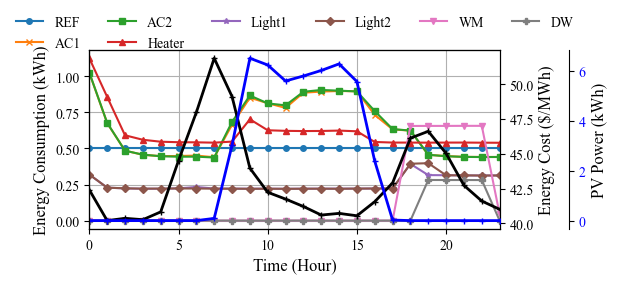

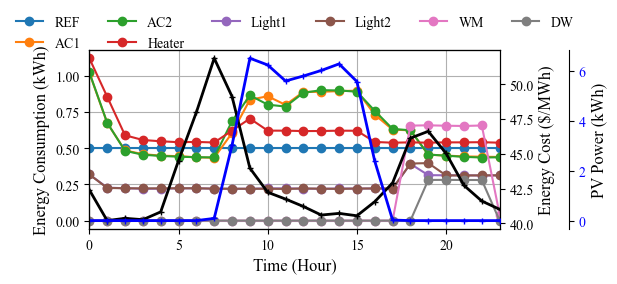

In [18]:
labels = ['REF',"AC1", "AC2", "Heater", "Light1", "Light2", 'WM', 'DW','Battery']
battery_idx = labels.index("Battery")

best = max(combo_results, key=lambda x: x["saving_mean"])
best_hourly = np.asarray(best["avg_hourly_mean"], dtype=float)  # (num_agents,24)

# choose which agents to plot (exclude battery)
plot_indices = [i for i in range(len(labels)) if i != battery_idx]

hours = np.arange(num_hours)

markers = ['o','x','s','^','*','D','v','P']

fig, ax1 = plt.subplots(figsize=(6, 3))

m = 0
for i in plot_indices:
    ax1.plot(hours, best_hourly[i], label=labels[i],
             marker=markers[m % len(markers)], markersize=4)
    m += 1

ax1.set_xlim(0, num_hours - 1)
ax1.set_xlabel('Time (Hour)')
ax1.set_ylabel('Energy Consumption (kWh)')
ax1.grid(True)

ax2 = ax1.twinx()
ax2.plot(hours, hourly_energy_cost*1000,  marker='+', color='k', markersize=4, linewidth=2)
ax2.set_ylabel('Energy Cost ($/MWh)')

ax3 = ax1.twinx()
ax3.plot(hours, hourly_pv_power, marker='+',color='b', markersize=4, linewidth=2)
ax3.set_ylabel('PV Power (kWh)')
ax3.tick_params('y', labelcolor='blue')
ax3.spines['right'].set_position(('outward', 50))
ax3.spines['right'].set_visible(True)

handles1, labels1_ = ax1.get_legend_handles_labels()
handles2, labels2_ = ax2.get_legend_handles_labels()
handles3, labels3_ = ax3.get_legend_handles_labels()

plt.legend(handles1 + handles2 + handles3,
           labels1_ + labels2_ + labels3_,
           loc='center', bbox_to_anchor=(0.5, 1.1),
           ncol=min(len(labels1_) + 2, 6), frameon=False)

plt.tight_layout()

plt.savefig("avg_agent_power_no_battery_24h.pdf")

hours = np.arange(24)

fig, ax1 = plt.subplots(figsize=(6, 3))

for i in range(num_agents-1):  # exclude battery
    plt.plot(hours,
             rep_profile[i,:],
             marker='o',
             linewidth=1.5,
             label=labels[i])

ax1.set_xlim(0, num_hours - 1)
ax1.set_xlabel('Time (Hour)')
ax1.set_ylabel('Energy Consumption (kWh)')
ax1.grid(True)

ax2 = ax1.twinx()
ax2.plot(hours, hourly_energy_cost*1000,  marker='+', color='k', markersize=4, linewidth=2)
ax2.set_ylabel('Energy Cost ($/MWh)')

ax3 = ax1.twinx()
ax3.plot(hours, hourly_pv_power, marker='+',color='b', markersize=4, linewidth=2)
ax3.set_ylabel('PV Power (kWh)')
ax3.tick_params('y', labelcolor='blue')
ax3.spines['right'].set_position(('outward', 50))
ax3.spines['right'].set_visible(True)

handles1, labels1_ = ax1.get_legend_handles_labels()
handles2, labels2_ = ax2.get_legend_handles_labels()
handles3, labels3_ = ax3.get_legend_handles_labels()

plt.legend(handles1 + handles2 + handles3,
           labels1_ + labels2_ + labels3_,
           loc='center', bbox_to_anchor=(0.5, 1.1),
           ncol=min(len(labels1_) + 2, 6), frameon=False)

plt.tight_layout()

save_figure('representative_seed_profile.eps')
plt.show()



The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


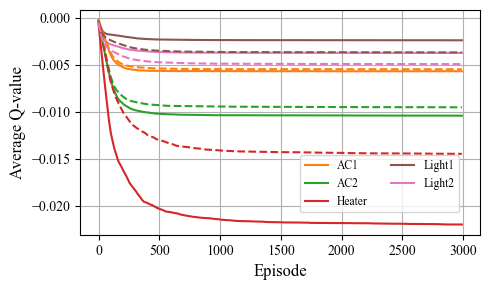

In [19]:
# ================== Plot Q‑values for best hormone vs. no hormone (ALL AGENTS, SAME AXIS) ==================
print("\nCollecting Q_values for the best hormone combination...")

# Re‑run the best hormone combo across all seeds to get Q‑values
best_mel = best['mel']
best_cor = best['cor']

hormone_runs = []
for seed in seeds:
    r = run_one(seed, modulation_mode="hormone", update_mode="qlearning",
                mel_model=best_mel, cor_model=best_cor, policy_mode="kfql", learn=True)
    hormone_runs.append(r)

# Aggregate Q‑values for best hormone
hormone_q_all = np.stack([r["q_values"] for r in hormone_runs], axis=0)  # (seeds, agents, episodes)
hormone_q_mean = np.mean(hormone_q_all, axis=0)          # (agents, episodes)
hormone_q_std  = np.std(hormone_q_all, axis=0, ddof=1)   # (agents, episodes)

# No‑hormone Q‑values are already in noh_summary
noh_q_mean = noh_summary['q_mean']      # (agents, episodes)
noh_q_std  = noh_summary['q_std']       # (agents, episodes)

# Smoothing function
def smooth_curve(values, window_size=50):
    if len(values) < window_size:
        return values
    return np.convolve(values, np.ones(window_size)/window_size, mode='valid')

window = 10
episodes_arr = np.arange(episodes)

# Prepare colours for each agent
colors = plt.cm.tab10(np.linspace(0, 1, num_agents))   # 10 distinct colors (enough for 9 agents)

# Single figure
plt.figure(figsize=(5, 3))

# Plot with hormone (solid lines)
for agent_idx in range(5):
    q_smooth = smooth_curve(hormone_q_mean[agent_idx+1], window)
    smooth_episodes = episodes_arr[:len(q_smooth)]
    plt.plot(smooth_episodes, q_smooth, 
             label=f'{labels[agent_idx+1]}', 
             color=colors[agent_idx+1], linewidth=1.5, linestyle='-')

# Plot without hormone (dashed lines)
for agent_idx in range(5):
    q_smooth = smooth_curve(noh_q_mean[agent_idx+1], window)
    smooth_episodes = episodes_arr[:len(q_smooth)]
    plt.plot(smooth_episodes, q_smooth, 
             color=colors[agent_idx+1], linewidth=1.5, linestyle='--')

plt.xlabel('Episode')
plt.ylabel('Average Q‑value')
#plt.title('Smoothed Average Q‑values for All Agents (with vs. without hormone)')
plt.grid(True)
plt.legend(ncol=2, fontsize='small', loc=(0.55,0.1))
plt.tight_layout()
save_figure('q_smooth_all_agents_same_axis.eps')
plt.show()

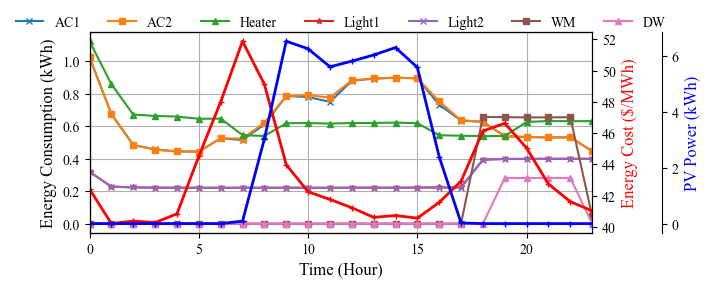

Energy w/o hormone: woh.eps


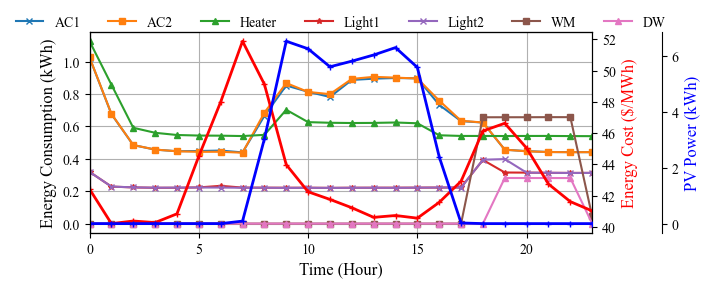

Energy with hormone:energy_wh1.eps


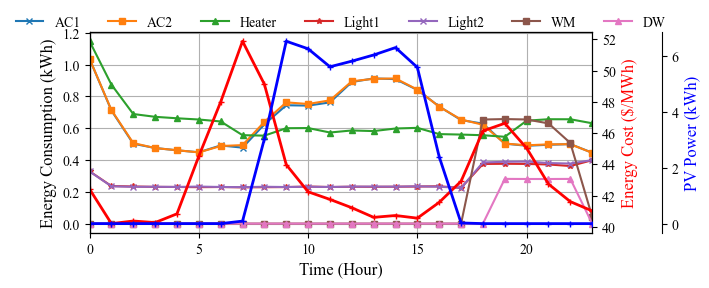

Energy w/o hormone_sarsa:energy_woh_s.eps


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


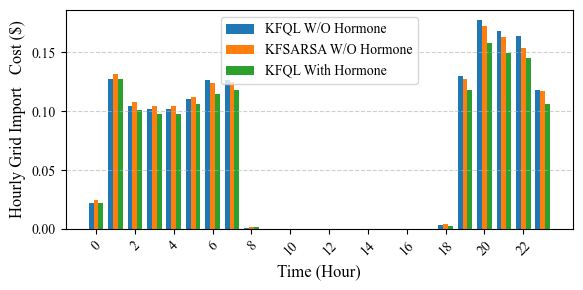

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


Hourly grid import cost:hourly_cost.eps


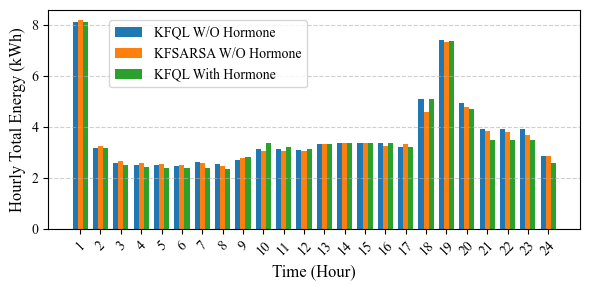

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


Hourly Total Energy Cost:hourly_cost


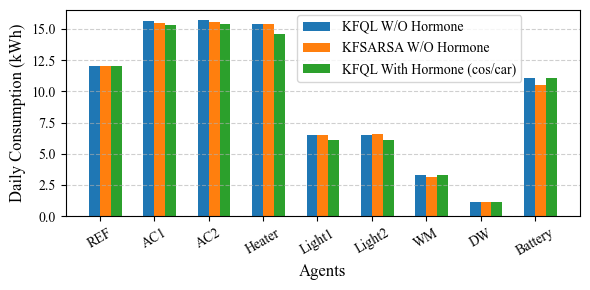

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


Daily Total Energy Consumption Per Agent:daily_energy


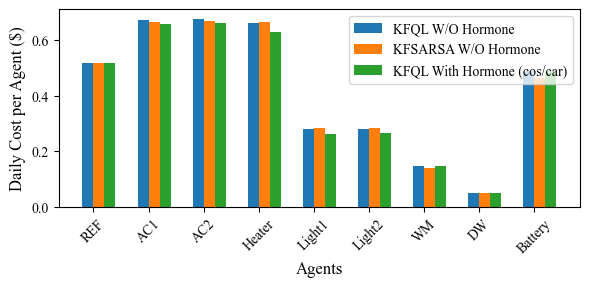

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


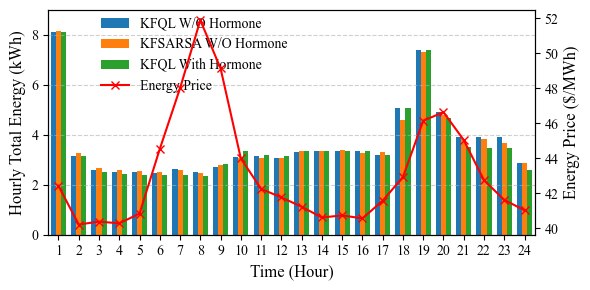

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


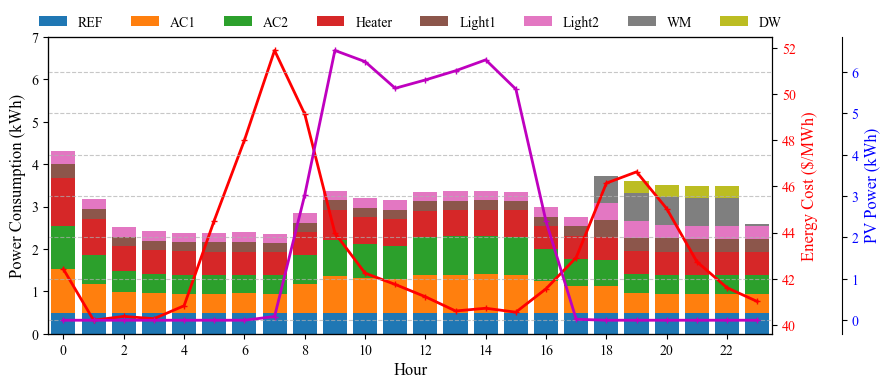

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


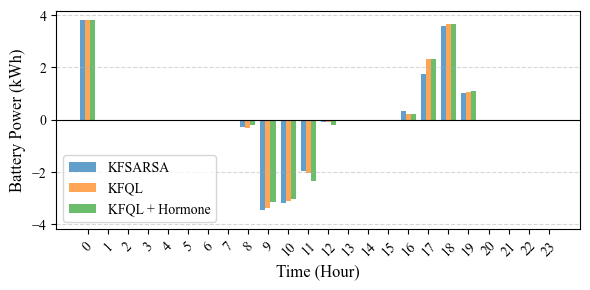

In [30]:
# ---------------------------
# 1. Extract necessary data
# ---------------------------
avg_power_hourly_no_hormone = noh_summary['avg_hourly_mean']      # (num_agents, 24)
avg_power_hourly_sarsa      = sarsa_summary['avg_hourly_mean']    # (num_agents, 24)
avg_power_hourly_hormone    = np.array(best['avg_hourly_mean'])   # (num_agents, 24)

total_24h_no_hormone_per_agent = noh_summary['per_agent_mean']    # (num_agents,)
total_24h_sarsa_per_agent      = sarsa_summary['per_agent_mean']  # (num_agents,)
total_24h_hormone_per_agent    = best['per_agent_mean']           # (num_agents,)

# For SARSA, we also need the hourly profiles (already have avg_power_hourly_sarsa)
# For naive, we already have total_24h_naive_per_agent

# ---------------------------
# 2. Helper functions
# ---------------------------
def smooth_curve(values, window=50):
    if len(values) < window:
        return values
    return np.convolve(values, np.ones(window)/window, mode='valid')

# ---------------------------
# 3. Plotting
# ---------------------------
num_agents_plot = 8  # skip REF [0] and Battery [8]
agent_indices = list(range(1, num_agents_plot))   # AC1, AC2, Heater, L1, L2, WM, DW
markers = ['o', 'x', 's', '^', '*', 'x', 's', '^', '*']
colors = ['b', 'c', 'g', 'c', 'm' , 'y', 'g', 'r', 'm']

## =============================================================================#
##      (a) Average Hourly Energy Consumption - WITHOUT Hormone -               #
##==============================================================================#

fig, ax1 = plt.subplots(figsize=(7, 3))
for i, agent_idx in enumerate(agent_indices):
    ax1.plot(avg_power_hourly_no_hormone[agent_idx], 
             label=labels[agent_idx], 
             marker=markers[i+1], markersize=4)
ax1.set_xlim(0, num_hours-1)
ax1.set_xlabel('Time (Hour)')
ax1.set_ylabel('Energy Consumption (kWh)')
ax1.grid(True)

ax2 = ax1.twinx()
ax2.plot(hourly_energy_cost * 1000, 'r', marker='+', markersize=4, linewidth=2)
ax2.set_ylabel('Energy Cost ($/MWh)', color='r')

ax3 = ax1.twinx()
ax3.plot(hourly_pv_power, 'b', marker='+', markersize=4, linewidth=2)
ax3.set_ylabel('PV Power (kWh)', color='b')
ax3.spines['right'].set_position(('outward', 50))
ax3.spines['right'].set_visible(True)

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
handles3, labels3 = ax3.get_legend_handles_labels()
plt.legend(handles1 + handles2 + handles3, 
           labels1 + labels2 + labels3, 
           loc='center', bbox_to_anchor=(0.5, 1.05), 
           ncol=len(labels1)+2, frameon=False)
plt.tight_layout()
save_figure("woh.eps")
plt.show()

print("Energy w/o hormone: woh.eps")
## =============================================================================#
##      (b) Average Hourly Energy Consumption - WITH Hormone (best combo) ----  #
##==============================================================================#

fig, ax1 = plt.subplots(figsize=(7, 3))
for i, agent_idx in enumerate(agent_indices):
    ax1.plot(avg_power_hourly_hormone[agent_idx], 
             label=labels[agent_idx], 
             marker=markers[i+1], markersize=4)
ax1.set_xlim(0, num_hours-1)
ax1.set_xlabel('Time (Hour)')
ax1.set_ylabel('Energy Consumption (kWh)')
ax1.grid(True)

ax2 = ax1.twinx()
ax2.plot(hourly_energy_cost * 1000, 'r', marker='+', markersize=4, linewidth=2)
ax2.set_ylabel('Energy Cost ($/MWh)', color='r')

ax3 = ax1.twinx()
ax3.plot(hourly_pv_power, 'b', marker='+', markersize=4, linewidth=2)
ax3.set_ylabel('PV Power (kWh)', color='b')
ax3.spines['right'].set_position(('outward', 50))
ax3.spines['right'].set_visible(True)

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
handles3, labels3 = ax3.get_legend_handles_labels()
plt.legend(handles1 + handles2 + handles3, 
           labels1 + labels2 + labels3, 
           loc='center', bbox_to_anchor=(0.5, 1.05), 
           ncol=len(labels1)+2, frameon=False)
plt.tight_layout()
save_figure("energy_wh1.eps")
plt.show()

print("Energy with hormone:energy_wh1.eps")
## =============================================================================#
##      (c) Average Hourly Energy Consumption - SARSA ----                      #
##==============================================================================#

fig, ax1 = plt.subplots(figsize=(7, 3))
for i, agent_idx in enumerate(agent_indices):
    ax1.plot(avg_power_hourly_sarsa[agent_idx], 
             label=labels[agent_idx], 
             marker=markers[i+1], markersize=4)
ax1.set_xlim(0, num_hours-1)
ax1.set_xlabel('Time (Hour)')
ax1.set_ylabel('Energy Consumption (kWh)')
ax1.grid(True)

ax2 = ax1.twinx()
ax2.plot(hourly_energy_cost * 1000, 'r', marker='+', markersize=4, linewidth=2)
ax2.set_ylabel('Energy Cost ($/MWh)', color='r')

ax3 = ax1.twinx()
ax3.plot(hourly_pv_power, 'b', marker='+', markersize=4, linewidth=2)
ax3.set_ylabel('PV Power (kWh)', color='b')
ax3.spines['right'].set_position(('outward', 50))
ax3.spines['right'].set_visible(True)

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
handles3, labels3 = ax3.get_legend_handles_labels()
plt.legend(handles1 + handles2 + handles3, 
           labels1 + labels2 + labels3, 
           loc='center', bbox_to_anchor=(0.5, 1.05), 
           ncol=len(labels1)+2, frameon=False)
plt.tight_layout()
save_figure("energy_woh_s.eps")
plt.show()
print("Energy w/o hormone_sarsa:energy_woh_s.eps")

## =============================================================================#
##               Hourly GRID-IMPORT Cost ($)(kWh) #                             #
##==============================================================================#
# 
hourly_price = hourly_energy_cost  # shape (24,)

cost_noh   = noh_summary["grid_import_hourly_mean"] * hourly_price
cost_sarsa = sarsa_summary["grid_import_hourly_mean"] * hourly_price
cost_hormone = best["grid_import_hourly_mean"] * hourly_price

x = np.arange(24)
width = 0.25

plt.figure(figsize=(6, 3))
plt.bar(x - width, cost_noh, width, label="KFQL W/O Hormone")
plt.bar(x, cost_sarsa, width, label="KFSARSA W/O Hormone")
plt.bar(x + width, cost_hormone, width, label="KFQL With Hormone")
plt.xlabel("Time (Hour)")
plt.ylabel("Hourly Grid Import   Cost ($)")
plt.xticks(x[::2], [f"{h}" for h in x[::2]], rotation=45)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
save_figure("hourly_cost.eps")
plt.show()

print("Hourly grid import cost:hourly_cost.eps")

## ==============================================================================
##                   Hourly Operation Cost (using total power per hour)
##===============================================================================

# Compute total hourly power (sum over agents)
hourly_power_no_hormone = avg_power_hourly_no_hormone.sum(axis=0)   # shape (24,)
hourly_power_sarsa      = avg_power_hourly_sarsa.sum(axis=0)
hourly_power_hormone    = avg_power_hourly_hormone.sum(axis=0)

# Convert to cost (assuming price in $/kWh)
cost_no_hormone = hourly_power_no_hormone   # actually cost = power * price, but here we plot power as proxy
cost_sarsa      = hourly_power_sarsa
cost_hormone    = hourly_power_hormone

x = np.arange(num_hours)
width = 0.25
plt.figure(figsize=(6, 3))
plt.bar(x - width, cost_no_hormone, width, label="KFQL W/O Hormone")
plt.bar(x, cost_sarsa, width, label="KFSARSA W/O Hormone")
plt.bar(x + width, cost_hormone, width, label="KFQL With Hormone")
plt.xticks(x, [f"{h+1}" for h in range(num_hours)], rotation=45)
plt.xlabel("Time (Hour)")
plt.ylabel("Hourly Total Energy (kWh)")
plt.legend(loc='center', bbox_to_anchor=(0.3, 0.8))
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
save_figure("hourly_cost.eps")
plt.show()

print("Hourly Total Energy Cost:hourly_cost")
## ==============================================================================
##                Daily Energy per Agent (bar chart)
##===============================================================================

# ---- (e) Daily Energy per Agent (bar chart) ----
bar_width = 0.2
x = np.arange(len(labels))
plt.figure(figsize=(6, 3))
plt.bar(x - 0.5*bar_width, total_24h_no_hormone_per_agent, width=bar_width, label="KFQL W/O Hormone")
plt.bar(x + 0.5*bar_width, total_24h_sarsa_per_agent, width=bar_width, label="KFSARSA W/O Hormone")
plt.bar(x + 1.5*bar_width, total_24h_hormone_per_agent, width=bar_width, 
        label=f"KFQL With Hormone ({best['mel']}/{best['cor']})")
plt.xticks(x, labels, rotation=30)
plt.ylabel("Daily Consumption (kWh)")
plt.xlabel("Agents")
plt.legend(loc=(0.45,0.65))
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
save_figure("daily_energy.eps")
plt.show()

print("Daily Total Energy Consumption Per Agent:daily_energy")

## ==============================================================================
##                           #
##===============================================================================
# ---- (f) Daily Cost per Agent (using price) ----
price_per_hour = hourly_energy_cost   # shape (24,)
def compute_costs(avg_hourly_power, price):
    # avg_hourly_power: (num_agents, num_hours)
    cost_per_agent = (avg_hourly_power * price).sum(axis=1)
    return cost_per_agent, cost_per_agent.sum()

# Use existing summaries
cost_no_hormone_per_agent, _ = compute_costs(avg_power_hourly_no_hormone, price_per_hour)
cost_sarsa_per_agent, _      = compute_costs(avg_power_hourly_sarsa, price_per_hour)
cost_hormone_per_agent, _    = compute_costs(avg_power_hourly_hormone, price_per_hour)

x = np.arange(len(labels))
width = 0.2
fig, ax = plt.subplots(figsize=(6,3))
# ax.bar(x - 1.5*width, cost_naive_per_agent, width, label="Baseline (No DR)")   # optional
ax.bar(x - 0.5*width, cost_no_hormone_per_agent, width, label="KFQL W/O Hormone")
ax.bar(x + 0.5*width, cost_sarsa_per_agent, width, label="KFSARSA W/O Hormone")
ax.bar(x + 1.5*width, cost_hormone_per_agent, width, label=f"KFQL With Hormone ({best['mel']}/{best['cor']})")
ax.set_ylabel("Daily Cost per Agent ($)")
ax.set_xlabel("Agents")
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45)
ax.legend(loc='upper right')
plt.tight_layout()
save_figure("daily_cost.eps")
plt.show()

## ==============================================================================
##                           #
##===============================================================================

# ---- (g) Hourly Total Energy with Price overlay (dual axis) ----
fig, ax1 = plt.subplots(figsize=(6, 3))
x = np.arange(num_hours)
width = 0.25
ax1.bar(x - width, hourly_power_no_hormone, width, label="KFQL W/O Hormone")
ax1.bar(x, hourly_power_sarsa, width, label="KFSARSA W/O Hormone")
ax1.bar(x + width, hourly_power_hormone, width, label="KFQL With Hormone")
ax1.set_ylim(0, 9)
ax1.set_xlim(-0.5, 23.5)
ax1.set_xticks(x)
ax1.set_xticklabels([f"{h+1}" for h in range(num_hours)])
ax1.set_xlabel("Time (Hour)")
ax1.set_ylabel("Hourly Total Energy (kWh)")
ax1.grid(axis='y', linestyle='--', alpha=0.6)

ax2 = ax1.twinx()
ax2.plot(x, hourly_energy_cost * 1000, 'r', marker='x', linestyle='-', label='Energy Price')
ax2.set_ylabel("Energy Price ($/MWh)", color='black')
ax2.tick_params(axis='y', labelcolor='black')

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2, loc='center', bbox_to_anchor=(0.3, 0.8), frameon=False)
plt.tight_layout()
save_figure("hourly_cost2.eps")
plt.show()

## ==============================================================================
##                           #
##===============================================================================

# ---- (h) Stacked bar chart of best hormone hourly consumption ----
bottom = np.zeros(num_hours)
hours = np.arange(num_hours)
colors_stack = plt.cm.tab10(np.linspace(0, 1, len(labels)))  # distinct colors
fig, ax1 = plt.subplots(figsize=(9, 4))
for i in range(8):
    ax1.bar(hours, avg_power_hourly_hormone[i], bottom=bottom, label=labels[i], color=colors_stack[i])
    bottom += avg_power_hourly_hormone[i]

ax1.set_xlim(-0.5, num_hours-0.5)
ax1.set_xlabel('Hour')
ax1.set_ylabel('Power Consumption (kWh)')
ax1.set_ylim(0, 7)
ax1.set_xticks(np.arange(0, num_hours, 2))

ax2 = ax1.twinx()
ax2.plot(hours, hourly_energy_cost * 1000, 'r', marker='+', markersize=4, linewidth=2)
ax2.set_ylabel('Energy Cost ($/MWh)', color='r')
ax2.tick_params('y', labelcolor='red')

ax3 = ax1.twinx()
ax3.plot(hours, hourly_pv_power, color='m', marker='+', markersize=4, linewidth=2)
ax3.set_ylabel('PV Power (kWh)', color='b')
ax3.tick_params('y', labelcolor='blue')
ax3.spines['right'].set_position(('outward', 50))
ax3.spines['right'].set_visible(True)

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
handles3, labels3 = ax3.get_legend_handles_labels()
ax1.legend(handles1 + handles2 + handles3, labels1 + labels2 + labels3, 
           loc='center', bbox_to_anchor=(0.5, 1.05), ncol=len(labels1)+2, frameon=False)
plt.tight_layout()
plt.grid(True, axis='y', linestyle='--', alpha=0.7)
save_figure("energy_stack.eps")
plt.show()


## ==============================================================================
##                           #
##===============================================================================

# Example: extract signed battery from summaries
sarsa_bat_signed   = sarsa_summary["bat_signed_mean"]    # shape (24,)
noh_bat_signed     = noh_summary["bat_signed_mean"]
hormone_bat_signed = best["bat_signed_mean"]             # from best dictionary

hours = np.arange(24)
bar_width = 0.25

hours = np.arange(24)
bar_width = 0.25

plt.figure(figsize=(6, 3))

# SARSA
plt.bar(hours - bar_width, sarsa_bat_signed, width=bar_width,
        color='#1f77b4', alpha=0.7, label='KFSARSA')

# KFQL (no hormone)
plt.bar(hours, noh_bat_signed, width=bar_width,
        color='#ff7f0e', alpha=0.7, label='KFQL')

# KFQL + Hormone
plt.bar(hours + bar_width, hormone_bat_signed, width=bar_width,
        color='#2ca02c', alpha=0.7, label='KFQL + Hormone')

# Reference line at zero
plt.axhline(0, color='black', linewidth=0.8)

plt.xlabel('Time (Hour)')
plt.ylabel('Battery Power (kWh)')
plt.xticks(hours, [f'{h}' for h in hours], rotation=45)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Optional: set symmetric y‑limits to emphasize positive/negative
max_abs = max(abs(sarsa_bat_signed.min()), abs(sarsa_bat_signed.max()),
              abs(noh_bat_signed.min()), abs(noh_bat_signed.max()),
              abs(hormone_bat_signed.min()), abs(hormone_bat_signed.max()))
plt.ylim(-max_abs * 1.1, max_abs * 1.1)

plt.tight_layout()
save_figure('battery_signed.eps')
plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


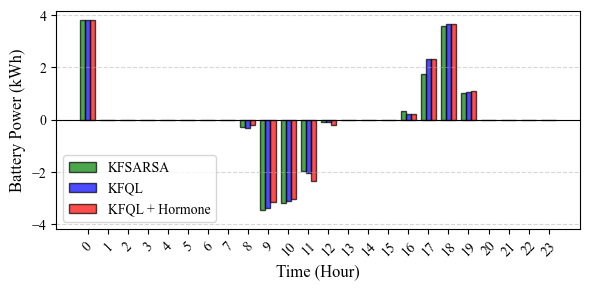

In [32]:
# Example: extract signed battery from summaries
sarsa_bat_signed   = sarsa_summary["bat_signed_mean"]    # shape (24,)
noh_bat_signed     = noh_summary["bat_signed_mean"]
hormone_bat_signed = best["bat_signed_mean"]             # from best dictionary

hours = np.arange(24)
bar_width = 0.25

hours = np.arange(24)
bar_width = 0.25

plt.figure(figsize=(6, 3))

# SARSA
plt.bar(hours - bar_width, sarsa_bat_signed, width=bar_width,
        color='green', edgecolor='black', alpha=0.7, label='KFSARSA')

# KFQL (no hormone)
plt.bar(hours, noh_bat_signed, width=bar_width,
        color='blue', edgecolor='black', alpha=0.7, label='KFQL')

# KFQL + Hormone
plt.bar(hours + bar_width, hormone_bat_signed, width=bar_width,
        color='red', edgecolor='black', alpha=0.7, label='KFQL + Hormone')

# Reference line at zero
plt.axhline(0, color='black', linewidth=0.8)

plt.xlabel('Time (Hour)')
plt.ylabel('Battery Power (kWh)')
plt.xticks(hours, [f'{h}' for h in hours], rotation=45)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Optional: set symmetric y‑limits to emphasize positive/negative
max_abs = max(abs(sarsa_bat_signed.min()), abs(sarsa_bat_signed.max()),
              abs(noh_bat_signed.min()), abs(noh_bat_signed.max()),
              abs(hormone_bat_signed.min()), abs(hormone_bat_signed.max()))
plt.ylim(-max_abs * 1.1, max_abs * 1.1)

plt.tight_layout()
save_figure('battery_signed.eps')
plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


Total Daily Consumption (Excl. Battery):
  KFQL W/O Hormone: 76.19 kWh
  KSARSA W/O Hormone: 75.83 kWh
  KFQL With Hormone: 74.02 kWh


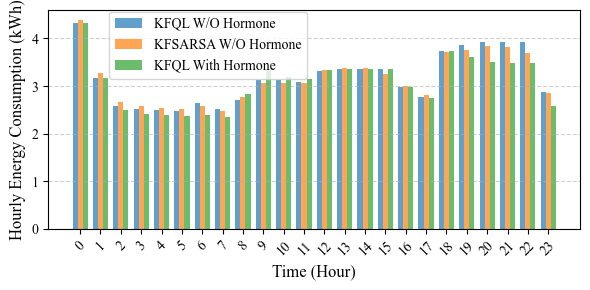

In [33]:
# ================== Average Hourly Consumption (Excluding Battery) ==================
# Exclude battery agent (index 8) from the summation
# Battery charging/discharging should not be counted as household consumption

# avg_hourly_mean from summaries (exclude battery)
# avg_hourly_mean shape: (num_agents, 24)
hourly_power_no_hormone = noh_summary['avg_hourly_mean'][:8].sum(axis=0)   # exclude battery (index 8)
hourly_power_sarsa = sarsa_summary['avg_hourly_mean'][:8].sum(axis=0)     # exclude battery
hourly_power_hormone = best['avg_hourly_mean'][:8].sum(axis=0)            # exclude battery

# === Optional: Convert to cost if needed ===
hourly_price = hourly_energy_cost  # $/kWh

# Cost based on consumption (excluding battery)
cost_no_hormone = hourly_power_no_hormone * hourly_price
cost_sarsa = hourly_power_sarsa * hourly_price
cost_hormone = hourly_power_hormone * hourly_price

print(f"Total Daily Consumption (Excl. Battery):")
print(f"  KFQL W/O Hormone: {np.sum(hourly_power_no_hormone):.2f} kWh")
print(f"  KSARSA W/O Hormone: {np.sum(hourly_power_sarsa):.2f} kWh")
print(f"  KFQL With Hormone: {np.sum(hourly_power_hormone):.2f} kWh")

# === Plot grouped bar chart ===
x = np.arange(num_hours)
bar_width = 0.25

plt.figure(figsize=(6, 3))
plt.bar(x - bar_width, hourly_power_no_hormone, width=bar_width, 
        label="KFQL W/O Hormone", color='#1f77b4', alpha=0.7)
plt.bar(x, hourly_power_sarsa, width=bar_width, 
        label="KFSARSA W/O Hormone", color='#ff7f0e', alpha=0.7)
plt.bar(x + bar_width, hourly_power_hormone, width=bar_width, 
        label="KFQL With Hormone", color='#2ca02c', alpha=0.7)

plt.xticks(x[::1], [f"{h}" for h in x[::1]], rotation=45)
plt.xlabel("Time (Hour)")
plt.ylabel("Hourly Energy Consumption (kWh)")
plt.legend(loc='center', bbox_to_anchor=(0.3, 0.84))
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
save_figure("hourly_consumption_excl_battery.eps")
plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


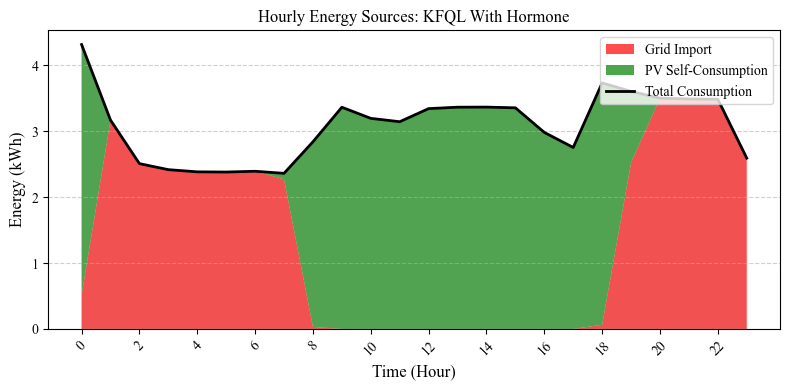

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


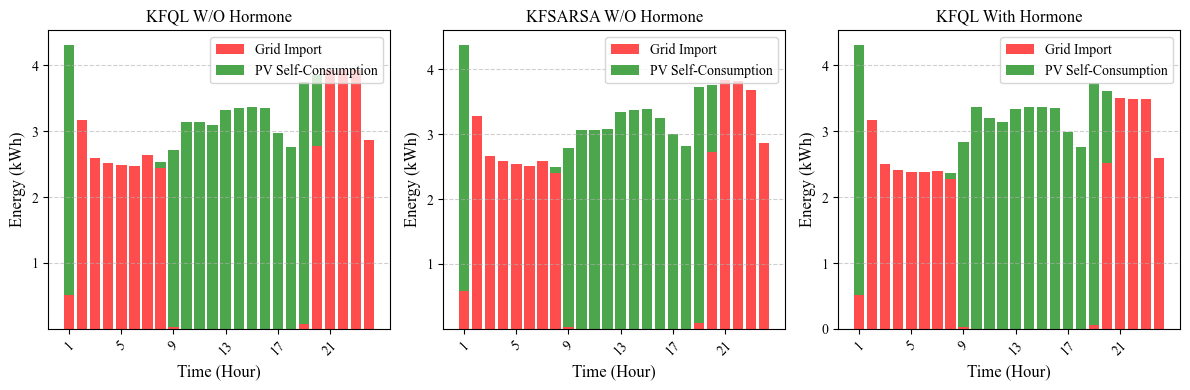

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


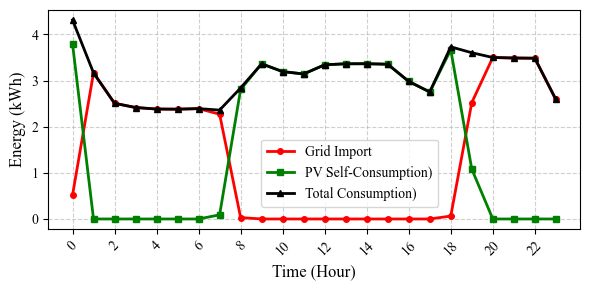

Hourly energy breakdow KFQL with hormone

=== Daily Energy Summary (Excluding Battery) ===
Method                    Total Consumption    Grid Import          PV Self-Consumption 
-------------------------------------------------------------------------------------
KFQL W/O Hormone          76.19                36.37                39.82               
KSARSA W/O Hormone        75.83                36.17                39.66               
KFQL With Hormone         74.02                33.71                40.31               


In [34]:
# ================== Hourly Energy Consumption: Grid + PV (Excluding Battery) ==================
# This plot shows the source of energy for household consumption:
# - Grid import (what you pay for)
# - PV self-consumption (free energy from solar)

hourly_price = hourly_energy_cost  # shape (24,)

# Get hourly grid import (what comes from grid)
grid_import_noh = noh_summary["grid_import_hourly_mean"]      # shape (24,)
grid_import_sarsa = sarsa_summary["grid_import_hourly_mean"]  # shape (24,)
grid_import_hormone = best["grid_import_hourly_mean"]         # shape (24,)

# Get total household consumption (excluding battery)
# This includes all appliances: REF, AC1, AC2, Heater, Light1, Light2, WM, DW
hourly_consumption_noh = noh_summary['avg_hourly_mean'][:8].sum(axis=0)
hourly_consumption_sarsa = sarsa_summary['avg_hourly_mean'][:8].sum(axis=0)
hourly_consumption_hormone = best['avg_hourly_mean'][:8].sum(axis=0)

# Calculate PV self-consumption = Total consumption - Grid import
# (assuming no battery charging/discharging)
pv_self_consumption_noh = hourly_consumption_noh - grid_import_noh
pv_self_consumption_sarsa = hourly_consumption_sarsa - grid_import_sarsa
pv_self_consumption_hormone = hourly_consumption_hormone - grid_import_hormone

# Clip to zero (should be non-negative, but numerical issues may occur)
pv_self_consumption_noh = np.maximum(pv_self_consumption_noh, 0)
pv_self_consumption_sarsa = np.maximum(pv_self_consumption_sarsa, 0)
pv_self_consumption_hormone = np.maximum(pv_self_consumption_hormone, 0)

# ========== Plot 1: Stacked Area Chart for Best Method (KFQL + Hormone) ==========
x = np.arange(num_hours)

plt.figure(figsize=(8, 4))
plt.stackplot(x, grid_import_hormone, pv_self_consumption_hormone,
              labels=['Grid Import', 'PV Self-Consumption'],
              colors=['red', 'green'], alpha=0.7)
plt.plot(x, hourly_consumption_hormone, 'k-', linewidth=2, label='Total Consumption')
plt.fill_between(x, 0, hourly_consumption_hormone, alpha=0.1, color='gray')
plt.xlabel('Time (Hour)')
plt.ylabel('Energy (kWh)')
plt.title('Hourly Energy Sources: KFQL With Hormone')
plt.xticks(x[::2], [f'{h}' for h in x[::2]], rotation=45)
plt.legend(loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
save_figure("energy_sources_hormone.eps")
plt.show()

# ========== Plot 2: Side-by-Side Stacked Bars for All Three Methods ==========
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

methods = [
    (grid_import_noh, pv_self_consumption_noh, "KFQL W/O Hormone"),
    (grid_import_sarsa, pv_self_consumption_sarsa, "KFSARSA W/O Hormone"),
    (grid_import_hormone, pv_self_consumption_hormone, "KFQL With Hormone")
]

for idx, (grid, pv, title) in enumerate(methods):
    ax = axes[idx]
    ax.bar(x, grid, width=0.8, label='Grid Import', color='red', alpha=0.7)
    ax.bar(x, pv, width=0.8, bottom=grid, label='PV Self-Consumption', color='green', alpha=0.7)
    ax.set_xlabel('Time (Hour)')
    ax.set_ylabel('Energy (kWh)')
    ax.set_title(title)
    ax.set_xticks(x[::4])
    ax.set_xticklabels([f'{h+1}' for h in x[::4]], rotation=45)
    ax.legend(loc='upper right')
    ax.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
save_figure("energy_sources_comparison.eps")
plt.show()

# ========== Plot 3: Line Plot Comparison ==========
plt.figure(figsize=(6, 3))
plt.plot(x, grid_import_hormone, 'r-o', label='Grid Import', linewidth=2, markersize=4)
plt.plot(x, pv_self_consumption_hormone, 'g-s', label='PV Self-Consumption)', linewidth=2, markersize=4)
plt.plot(x, hourly_consumption_hormone, 'k-^', label='Total Consumption)', linewidth=2, markersize=4)
plt.xlabel('Time (Hour)')
plt.ylabel('Energy (kWh)')
#plt.title('Hourly Energy Breakdown: KFQL With Hormone')
plt.xticks(x[::2], [f'{h}' for h in x[::2]], rotation=45)
plt.legend(loc=(0.4,0.1))
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
save_figure("energy_breakdown_line.eps")
plt.show()

print("Hourly energy breakdow KFQL with hormone")
# ========== Print Summary Statistics ==========
print("\n=== Daily Energy Summary (Excluding Battery) ===")
print(f"{'Method':<25} {'Total Consumption':<20} {'Grid Import':<20} {'PV Self-Consumption':<20}")
print("-" * 85)
print(f"{'KFQL W/O Hormone':<25} {np.sum(hourly_consumption_noh):<20.2f} {np.sum(grid_import_noh):<20.2f} {np.sum(pv_self_consumption_noh):<20.2f}")
print(f"{'KSARSA W/O Hormone':<25} {np.sum(hourly_consumption_sarsa):<20.2f} {np.sum(grid_import_sarsa):<20.2f} {np.sum(pv_self_consumption_sarsa):<20.2f}")
print(f"{'KFQL With Hormone':<25} {np.sum(hourly_consumption_hormone):<20.2f} {np.sum(grid_import_hormone):<20.2f} {np.sum(pv_self_consumption_hormone):<20.2f}")

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


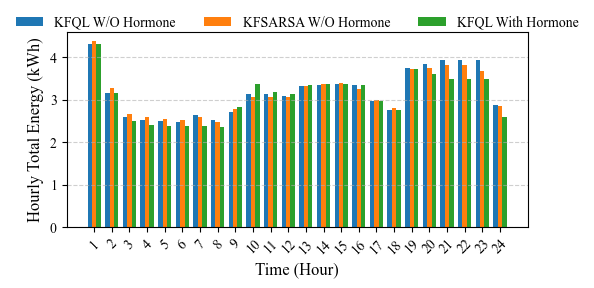

In [36]:
# ---- (d) Hourly Total Energy (excluding battery) ----
# Compute total hourly power (sum over agents, EXCLUDING battery)
hourly_power_no_hormone = avg_power_hourly_no_hormone[:8].sum(axis=0)   # shape (24,)
hourly_power_sarsa      = avg_power_hourly_sarsa[:8].sum(axis=0)
hourly_power_hormone    = avg_power_hourly_hormone[:8].sum(axis=0)

# Plot total energy (kWh) - this is actual household consumption
x = np.arange(num_hours)
width = 0.25
plt.figure(figsize=(6, 3))
plt.bar(x - width, hourly_power_no_hormone, width, label="KFQL W/O Hormone")
plt.bar(x, hourly_power_sarsa, width, label="KFSARSA W/O Hormone")
plt.bar(x + width, hourly_power_hormone, width, label="KFQL With Hormone")
plt.xticks(x, [f"{h+1}" for h in range(num_hours)], rotation=45)
plt.xlabel("Time (Hour)")
plt.ylabel("Hourly Total Energy (kWh)")
#plt.title("Household Consumption (Excluding Battery)")
plt.legend(loc='center', bbox_to_anchor=(0.5, 1.05), ncol=3, frameon=False)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
save_figure("hourly_consumption_excl_battery.eps")
plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


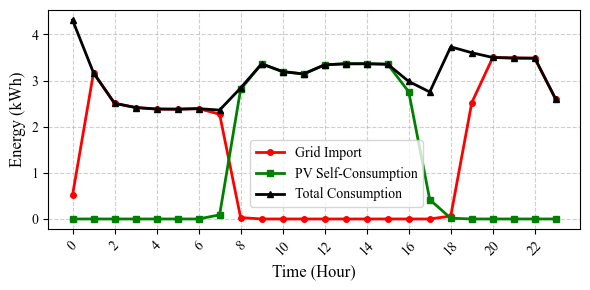

Hourly energy breakdow KFQL with hormone


[Text(0, 0, '0'),
 Text(4, 0, '4'),
 Text(8, 0, '8'),
 Text(12, 0, '12'),
 Text(16, 0, '16'),
 Text(20, 0, '20')]

In [25]:
# ── Step 1: get battery discharge hourly log ──────────────────────────────
# Battery index is 8 (last agent). Negative action = charging, positive = discharging
# avg_hourly_mean[8] is the mean battery power per hour (signed)
battery_noh     = noh_summary['avg_hourly_mean'][8]       # signed: neg=charge, pos=discharge
battery_sarsa   = sarsa_summary['avg_hourly_mean'][8]
battery_hormone = best['avg_hourly_mean'][8]

# Discharge contribution (positive only = energy flowing OUT of battery to loads)
bat_discharge_noh     = np.maximum(battery_noh, 0)
bat_discharge_sarsa   = np.maximum(battery_sarsa, 0)
bat_discharge_hormone = np.maximum(battery_hormone, 0)

# ── Step 2: correct PV self-consumption ───────────────────────────────────
# PV_self = Total_consumption - Grid_import - Battery_discharge
pv_self_consumption_noh     = hourly_consumption_noh     - grid_import_noh     - bat_discharge_noh
pv_self_consumption_sarsa   = hourly_consumption_sarsa   - grid_import_sarsa   - bat_discharge_sarsa
pv_self_consumption_hormone = hourly_consumption_hormone - grid_import_hormone - bat_discharge_hormone

# Clip negatives from numerical noise
pv_self_consumption_noh     = np.maximum(pv_self_consumption_noh, 0)
pv_self_consumption_sarsa   = np.maximum(pv_self_consumption_sarsa, 0)
pv_self_consumption_hormone = np.maximum(pv_self_consumption_hormone, 0)

# ========== Plot 3: Line Plot Comparison ==========
plt.figure(figsize=(6, 3))
plt.plot(x, grid_import_hormone, 'r-o', label='Grid Import', linewidth=2, markersize=4)
plt.plot(x, pv_self_consumption_hormone, 'g-s', label='PV Self-Consumption', linewidth=2, markersize=4)
plt.plot(x, hourly_consumption_hormone, 'k-^', label='Total Consumption', linewidth=2, markersize=4)
plt.xlabel('Time (Hour)')
plt.ylabel('Energy (kWh)')
#plt.title('Hourly Energy Breakdown: KFQL With Hormone')
plt.xticks(x[::2], [f'{h}' for h in x[::2]], rotation=45)
plt.legend(loc=(0.38,0.1))
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
save_figure("energy_breakdown_line.eps")
plt.show()

print("Hourly energy breakdow KFQL with hormone")

ax.set_xticklabels([f'{h}' for h in x[::4]], rotation=45)

# Service-referenced experiments

Do the circadian (hormone) signals save energy at **matched delivered service**? Every policy is scored against one common, hormone-independent comfort reference.

Run order: cells **0, 1, 2, 3** (data, forecasts, forecast file, simulation), then **S-A → S-B → S-C**. The main results cell is not needed.

* `comfort_setpoint` defines the comfort setpoint once and `get_modulation` the modulation once.
* Modes: `none`, `hormone`, `hormone_fixed_setpoint` (reward only), `setpoint_only`, `hormone_scaled_sp` (`sp_mel_scale=k`), `none_night_reduction` (`night_reduction=c`), `hormone_comfort_weight` (`comfort_weight_a`); options `stochastic=True` and `CONSUMER_PROFILE`.
* Experiments: E1 common-reference evaluation and 2×2 ablation; E2 melatonin-coefficient sweep; E3 constant night setback (matched baseline); E4 household profiles; E5 stochastic PV/price; E6 comfort-weight variant; E7 extra held-out days.
* S-B caches every run in `service_results.pkl`. Set `QUICK = True` in S-A for a 2-minute code check.


In [26]:
# =====================================================================================
# S-A  |  Setup for the service-referenced experiments (run after cells 0, 1, 2 and 3)
#         Does NOT need the big results cell (cell 4) to have been run.
#
#  What this cell defines
#    * common_reference(...)  : hormone-free setpoint P_ref (mel_sp = cor_sp = 0), the same
#                               for every policy -> service is measured against ONE target
#    * own_reference(...)     : the setpoint each policy was trained to track
#    * run_exp(...)            : runs run_simulation() once and stores energy, grid import and
#                               service metrics for two evaluation windows:
#                                 'all'  = mean over all training episodes (= E_tot, as in
#                                          compute_power_stats)
#                                 'conv' = last CONV_LAST episodes (epsilon at its floor,
#                                          i.e. the converged policy)
#    * results are cached in service_results.pkl after every run, so the experiment cell can be
#      interrupted and resumed without repeating finished runs.
# =====================================================================================
import os, time, pickle
import numpy as np

QUICK      = False                 # True -> 2 seeds x 300 episodes, only to check the code runs
SEEDS      = [0, 1] if QUICK else list(range(10))
EXP_EPISODES = 300 if QUICK else 3000
CONV_LAST  = 50 if QUICK else 500  # epsilon reaches its floor (0.05) after ~1535 episodes
CACHE_FILE = "service_results_quick.pkl" if QUICK else "service_results.pkl"

episodes = EXP_EPISODES             # run_simulation reads the global 'episodes'

COMFORT_AGENTS = [1, 2, 3, 4, 5]                    # AC1, AC2, Heater, L1, L2
COMFORT_K      = {1: 600.0, 2: 600.0, 3: 600.0, 4: 300.0, 5: 300.0}   # same weights as the rewards
AGENT_NAMES    = ['REF', 'AC1', 'AC2', 'Heater', 'L1', 'L2', 'WM', 'DW', 'Battery']
BATTERY        = num_agents - 1

BASELINE_PROFILE = dict(name="Baseline", shift=0, scale=1.0, away=None, away_factor=1.0)


def _default_days():
    pv = solar_predicted_data[24:48].flatten()
    pr = price_predicted_data[24:48].flatten() / 1000
    return pv, pr


def _set_profile(profile):
    CONSUMER_PROFILE.clear()
    CONSUMER_PROFILE.update(profile)


def _night_mask(pv_day):
    pv_norm = np.asarray(pv_day, float) / (np.max(hourly_pv_power) + 1e-6)
    return pv_norm < 0.05                     # identical to night_gate in the rewards


def setpoint_matrix(pv_day, price_day, modulation_mode="none", mel_model="cos", cor_model="car",
                    sp_mel_scale=1.0, night_reduction=0.0):
    """(num_agents, 24) setpoints for the comfort agents (NaN elsewhere) under a given modulation."""
    pv_day = np.asarray(pv_day, float); price_day = np.asarray(price_day, float)
    price_norm = (price_day - price_day.min()) / (price_day.max() - price_day.min() + 1e-8)
    pv_norm = (pv_day - pv_day.min()) / (pv_day.max() - pv_day.min() + 1e-8)
    SP = np.full((num_agents, num_hours), np.nan)
    for h in range(num_hours):
        _, _, mel_sp, cor_sp = get_modulation(modulation_mode, h, mel_model, cor_model,
                                              price_norm_h=price_norm[h], pv_norm_h=pv_norm[h],
                                              sp_mel_scale=sp_mel_scale, night_reduction=night_reduction)
        for a in COMFORT_AGENTS:
            SP[a, h] = comfort_setpoint(a, h, float(pv_day[h]), mel_sp, cor_sp, float(power_ranges[a]))
    return SP


def common_reference(pv_day, price_day):
    return setpoint_matrix(pv_day, price_day, modulation_mode="none")


def _window_metrics(P, G, REF, OWN, night):
    """P: (num_agents, E, 24) power; G: (E, 24) grid import; REF/OWN: (num_agents, 24)."""
    out = {}
    appliance = P[:BATTERY].sum(axis=(0, 2))              # per episode
    batt = P[BATTERY].sum(axis=1)
    out["appliance"]  = float(appliance.mean())           # household consumption, battery excluded
    out["battery"]    = float(batt.mean())                # battery discharge
    out["paper_total"] = float((appliance + batt).mean()) # = 'total_all' (E_tot: appliances + battery discharge)
    out["grid_import"] = float(G.sum(axis=1).mean())

    U = np.zeros(P.shape[1]); Un = np.zeros(P.shape[1]); Ov = np.zeros(P.shape[1])
    Jc = np.zeros(P.shape[1]); Jo = np.zeros(P.shape[1])
    U_agent = {}; U_hour = np.zeros(num_hours)
    for a in COMFORT_AGENTS:
        dev = P[a] - REF[a][None, :]                       # (E, 24)
        short = np.maximum(-dev, 0.0)
        U += short.sum(axis=1)
        Un += short[:, night].sum(axis=1)
        Ov += np.maximum(dev, 0.0).sum(axis=1)
        w = dissatisfaction_coefficients[a] * COMFORT_K[a] / power_ranges[a] ** 2
        Jc += w * (dev ** 2).sum(axis=1)
        Jo += w * ((P[a] - OWN[a][None, :]) ** 2).sum(axis=1)
        U_agent[AGENT_NAMES[a]] = float(short.sum(axis=1).mean())
        U_hour += short.mean(axis=0)
    out["U"]        = float(U.mean())    # unserved comfort energy vs common reference [kWh/day]
    out["U_night"]  = float(Un.mean())   # ... in night-gated hours only
    out["over"]     = float(Ov.mean())   # delivery above the common reference [kWh/day]
    out["Jc_common"] = float(Jc.mean())  # quadratic comfort penalty vs COMMON reference
    out["Jc_own"]   = float(Jo.mean())   # quadratic comfort penalty vs the policy's OWN setpoint
    out["U_agent"]  = U_agent
    out["U_hour"]   = U_hour
    out["hourly"]   = P.mean(axis=1)     # (num_agents, 24)
    return out


# ---------------- cache ----------------
if os.path.exists(CACHE_FILE):
    with open(CACHE_FILE, "rb") as f:
        RES = pickle.load(f)
    print(f"Loaded {len(RES)} cached runs from {CACHE_FILE}")
else:
    RES = {}


def _key(seed, profile, sim_kwargs):
    kw = {k: v for k, v in sim_kwargs.items() if k not in ("pv_day", "price_day")}
    day = sim_kwargs.get("day_label", "Day27")
    return (profile["name"], day, int(seed), EXP_EPISODES, tuple(sorted(kw.items())))


def run_exp(seed, profile=BASELINE_PROFILE, pv_day=None, price_day=None, day_label="Day27", **sim_kwargs):
    """One simulation + metrics. sim_kwargs go straight to run_simulation()."""
    key = _key(seed, profile, dict(sim_kwargs, day_label=day_label))
    if key in RES:
        return RES[key]
    pv_def, pr_def = _default_days()
    pv_d = pv_def if pv_day is None else np.asarray(pv_day, float)
    pr_d = pr_def if price_day is None else np.asarray(price_day, float)

    _set_profile(profile)
    try:
        out = run_simulation(reward_functions, seed=seed, pv_day=pv_day, price_day=price_day, **sim_kwargs)
        power_log, grid_import_log, runtime = out[1], out[5], out[-1]
        mode = sim_kwargs.get("modulation_mode", "none")
        REF = common_reference(pv_d, pr_d)
        OWN = setpoint_matrix(pv_d, pr_d, mode,
                              sim_kwargs.get("mel_model", "cos"), sim_kwargs.get("cor_model", "car"),
                              sim_kwargs.get("sp_mel_scale", 1.0), sim_kwargs.get("night_reduction", 0.0))
    finally:
        _set_profile(BASELINE_PROFILE)

    night = _night_mask(pv_d)
    E = power_log.shape[1]
    res = {"seed": int(seed), "runtime": float(runtime),
           "all":  _window_metrics(power_log, grid_import_log, REF, OWN, night),
           "conv": _window_metrics(power_log[:, E - CONV_LAST:, :], grid_import_log[E - CONV_LAST:, :], REF, OWN, night),
           "REF": REF, "OWN": OWN, "night": night}
    RES[key] = res
    with open(CACHE_FILE, "wb") as f:
        pickle.dump(RES, f)
    return res


def run_variant(label, seeds=None, **kw):
    seeds = SEEDS if seeds is None else seeds
    t0 = time.perf_counter()
    runs = [run_exp(s, **kw) for s in seeds]
    print(f"  {label:<38s} {len(runs)} runs  ({time.perf_counter() - t0:6.1f} s)")
    return runs


print(f"Setup ready: seeds={SEEDS}, episodes={EXP_EPISODES}, converged window = last {CONV_LAST}")


Loaded 312 cached runs from service_results.pkl
Setup ready: seeds=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9], episodes=3000, converged window = last 500


In [27]:
# =====================================================================================
# S-B  |  Run all service-referenced experiments
#         Safe to interrupt: finished runs are cached and skipped on the next execution.
# =====================================================================================
RUN_E1 = True   # common-reference service evaluation (+ setpoint-only arm of the 2x2)
RUN_E2 = True   # melatonin setpoint-coefficient sweep
RUN_E3 = True   # matched baseline: constant night setback, no hormones
RUN_E4 = True   # consumer profiles
RUN_E5 = True   # stochastic PV/price realisation
RUN_E6 = True   # comfort-weight variant: melatonin scales the comfort weight (not setpoint, not price)
RUN_E7 = True   # extra held-out days 15-17 Feb: KFQL-None vs Proposed
CW_A = [0.4, 0.8]                                            # declared before running; report both
EXTRA_DAYS = {"15 Feb": 144, "16 Feb": 168, "17 Feb": 192}   # index into solar/price_predicted_data

HORM = dict(mel_model="cos", cor_model="car")

# ---- variant definitions (k = 1 is exactly the proposed method, c = 0 is exactly KFQL-None) ----
VARIANTS = {
    "KFQL-None":              dict(modulation_mode="none", update_mode="qlearning"),
    "KFSARSA":                dict(modulation_mode="none", update_mode="sarsa"),
    "Time weights":           dict(modulation_mode="time_weights", update_mode="qlearning"),
    "Proposed (cos/car)":     dict(modulation_mode="hormone", update_mode="qlearning", **HORM),
    "Reward-only (fixed SP)": dict(modulation_mode="hormone_fixed_setpoint", update_mode="qlearning", **HORM),
    "Setpoint-only":          dict(modulation_mode="setpoint_only", update_mode="qlearning", **HORM),
}
DETERMINISTIC = {   # no learning, identical for every seed -> run once
    "Rule PV+Price": dict(modulation_mode="none", policy_mode="rule_pv_price", learn=False),
    "ToU":           dict(modulation_mode="none", policy_mode="tou", learn=False),
}
SWEEP_K = [0.0, 0.25, 0.5, 0.75, 1.0, 1.25]
NIGHT_C = [0.0, 0.25, 0.5, 0.75, 1.0]

def sweep_kwargs(k):
    return VARIANTS["Proposed (cos/car)"] if k == 1.0 else \
        dict(modulation_mode="hormone_scaled_sp", sp_mel_scale=k, update_mode="qlearning", **HORM)

def night_kwargs(c):
    return VARIANTS["KFQL-None"] if c == 0.0 else \
        dict(modulation_mode="none_night_reduction", night_reduction=c, update_mode="qlearning")

PROFILES = [
    dict(name="Working (away 08-16)", shift=0, scale=1.0, away=(8, 16), away_factor=0.6),
    dict(name="High demand (+20%)",   shift=0, scale=1.2, away=None,    away_factor=1.0),
    dict(name="Late schedule (+2 h)", shift=2, scale=1.0, away=None,    away_factor=1.0),
]

n_runs = (RUN_E1 * (len(VARIANTS) * len(SEEDS) + 2) + RUN_E2 * (len(SWEEP_K) - 1) * len(SEEDS)
          + RUN_E3 * (len(NIGHT_C) - 1) * len(SEEDS) + RUN_E4 * len(PROFILES) * 2 * len(SEEDS)
          + RUN_E5 * 2 * len(SEEDS))
print(f"Up to {n_runs} runs (cached ones are skipped). At ~20 s/run: ~{n_runs * 20 / 60:.0f} min\n")

E1, E2, E3, E4, E5 = {}, {}, {}, {}, {}

if RUN_E1:
    print("E1  common-reference service evaluation")
    for lab, kw in VARIANTS.items():
        E1[lab] = run_variant(lab, **kw)
    for lab, kw in DETERMINISTIC.items():
        E1[lab] = run_variant(lab, seeds=[0], **kw) * len(SEEDS)   # replicate the deterministic run

if RUN_E2:
    print("E2  melatonin setpoint-coefficient sweep (k multiplies 0.40 / 0.10)")
    for k in SWEEP_K:
        E2[k] = run_variant(f"k = {k}", **sweep_kwargs(k))

if RUN_E3:
    print("E3  matched baseline: constant night setback c (no hormones)")
    for c in NIGHT_C:
        E3[c] = run_variant(f"c = {c}", **night_kwargs(c))

if RUN_E4:
    print("E4  consumer profiles")
    for prof in PROFILES:
        E4[prof["name"]] = {
            "KFQL-None": run_variant(f"{prof['name']} | None", profile=prof, **VARIANTS["KFQL-None"]),
            "Proposed":  run_variant(f"{prof['name']} | Proposed", profile=prof, **VARIANTS["Proposed (cos/car)"]),
        }

if RUN_E5:
    print("E5  stochastic PV/price (5% / 3% of daily max, per episode)")
    E5["KFQL-None"] = run_variant("Stochastic | None", stochastic=True, **VARIANTS["KFQL-None"])
    E5["Proposed"]  = run_variant("Stochastic | Proposed", stochastic=True, **VARIANTS["Proposed (cos/car)"])

E6, E7 = {}, {}
if RUN_E6:
    print("E6  comfort-weight variant (diss x (1 - a_m * melatonin); setpoint and price hormone-free)")
    for a in CW_A:
        E6[a] = run_variant(f"Comfort-weight a_m = {a}", modulation_mode="hormone_comfort_weight",
                            comfort_weight_a=a, update_mode="qlearning", **HORM)

if RUN_E7:
    print("E7  extra held-out days (agents retrained per day; parameters tuned on 10 Feb)")
    for dname, k in EXTRA_DAYS.items():
        pv_d = solar_predicted_data[k:k + 24].flatten()
        pr_d = price_predicted_data[k:k + 24].flatten() / 1000
        E7[dname] = {
            "KFQL-None": run_variant(f"{dname} | None", pv_day=pv_d, price_day=pr_d, day_label=dname,
                                     **VARIANTS["KFQL-None"]),
            "Proposed":  run_variant(f"{dname} | Proposed", pv_day=pv_d, price_day=pr_d, day_label=dname,
                                     **VARIANTS["Proposed (cos/car)"]),
        }

episodes = EXP_EPISODES
print("\nAll requested experiments finished.")


Up to 232 runs (cached ones are skipped). At ~20 s/run: ~77 min

E1  common-reference service evaluation
  KFQL-None                              10 runs  (   0.0 s)
  KFSARSA                                10 runs  (   0.0 s)
  Time weights                           10 runs  (   0.0 s)
  Proposed (cos/car)                     10 runs  (   0.0 s)
  Reward-only (fixed SP)                 10 runs  (   0.0 s)
  Setpoint-only                          10 runs  (   0.0 s)
  Rule PV+Price                          1 runs  (   0.0 s)
  ToU                                    1 runs  (   0.0 s)
E2  melatonin setpoint-coefficient sweep (k multiplies 0.40 / 0.10)
  k = 0.0                                10 runs  (   0.0 s)
  k = 0.25                               10 runs  (   0.0 s)
  k = 0.5                                10 runs  (   0.0 s)
  k = 0.75                               10 runs  (   0.0 s)
  k = 1.0                                10 runs  (   0.0 s)
  k = 1.25                          

Sanity check (window='all', E_tot):
  KFQL-None             87.28 kWh (reported 87.28)  OK
  Proposed (cos/car)    85.11 kWh (reported 85.11)  OK

=== E1: energy and service vs the COMMON reference  [window = 'all'] ===
Method                             E_tot       Appliance     Grid import       U (kWh)       U_night          Over      Jc common         Jc own
------------------------------------------------------------------------------------------------------------------------------------------------
KFQL-None                   87.28 ± 0.11    76.19 ± 0.12    36.37 ± 0.08   1.47 ± 0.06   0.73 ± 0.04   7.02 ± 0.06   67.74 ± 0.48   67.74 ± 0.48
KFSARSA                     86.35 ± 0.21    75.83 ± 0.13    36.17 ± 0.10   2.96 ± 0.09   1.58 ± 0.07   8.33 ± 0.06   80.28 ± 0.44   80.28 ± 0.44
Time weights                86.78 ± 0.21    77.21 ± 0.20    35.00 ± 0.06   2.87 ± 0.02   2.56 ± 0.02   9.44 ± 0.19   81.79 ± 1.16   82.46 ± 0.47
Proposed (cos/car)          85.11 ± 0.04    74.02 ± 0.0

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


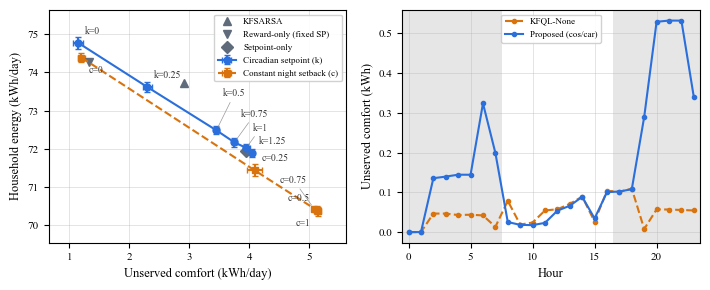


=== Robustness: profiles and stochastic environment  [window='conv', energy=appliance] ===
Condition                          None       Proposed          Saving [95% CI]      %  Seeds+       p   ΔU (kWh)
Baseline (Day 27)          74.39 ± 0.12   72.02 ± 0.11   2.37 [ 2.23, 2.51]         3.18  10/10    0.002      +2.75
Working (away 08-16)       69.68 ± 0.14   67.39 ± 0.14   2.29 [ 2.17, 2.41]         3.28  10/10    0.002      +2.63
High demand (+20%)         81.93 ± 0.17   76.52 ± 0.14   5.42 [ 5.28, 5.55]         6.61  10/10    0.002      +5.22
Late schedule (+2 h)       74.04 ± 0.11   71.75 ± 0.15   2.29 [ 2.17, 2.41]         3.09  10/10    0.002      +2.68
Stochastic PV/price        74.63 ± 0.16   72.16 ± 0.17   2.47 [ 2.24, 2.69]         3.30  10/10    0.002      +2.53
ΔU > 0 means the proposed policy leaves more comfort demand unserved than KFQL-None.

SUMMARY
  Proposed vs KFQL-None: energy +2.37 kWh/day saved, unserved comfort +2.75 kWh/day (1.20 -> 3.95).
  Setpoint-only vs K

In [28]:
# =====================================================================================
# S-C  |  Analysis: tables, matched-service comparison, figure, summary
#         Re-runnable at any time from the cache (no simulation here).
# =====================================================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats as _stats

WINDOW         = "conv"        # 'conv' = converged policy (last CONV_LAST episodes), 'all' = all episodes
ENERGY_METRIC  = "appliance"   # 'appliance' (E_app, battery excluded) or 'paper_total' (E_tot)
SERVICE_METRIC = "U"           # 'U' (unserved comfort energy, all hours) or 'U_night'
N_BOOT         = 2000
rng_boot       = np.random.default_rng(2026)

def vals(runs, metric, window=WINDOW):
    return np.array([r[window][metric] for r in runs], float)

def ms(x):
    return f"{np.mean(x):6.2f} ± {np.std(x, ddof=1) if len(x) > 1 else 0:4.2f}"

def paired(b, p, conf=0.95):
    """baseline - proposed over seeds: mean, paired t-CI, two-sided exact Wilcoxon W+, p, #positive."""
    d = np.asarray(b, float) - np.asarray(p, float)
    n = len(d); m = d.mean(); se = d.std(ddof=1) / np.sqrt(n)
    h = _stats.t.ppf((1 + conf) / 2, n - 1) * se
    dz = d[d != 0]
    if len(dz) == 0:
        return dict(mean=m, lo=m - h, hi=m + h, W=np.nan, p=np.nan, pos=0, n=0)
    w = _stats.wilcoxon(dz, alternative="two-sided")
    ranks = _stats.rankdata(np.abs(dz))
    return dict(mean=m, lo=m - h, hi=m + h, W=ranks[dz > 0].sum(), p=w.pvalue, pos=int((dz > 0).sum()), n=len(dz))

def place_labels(ax, xs, ys, texts, placed, side="upper right", fs=7, gap=5, step=6, color="#333333"):
    """Label points without overlapping each other, labels of other families, or the axes edge.
    side: preferred position ('upper right', 'lower right', 'upper left', 'lower left'); if there is no
    room, the other vertical side is tried, then the other horizontal side.
    placed: shared list of occupied label boxes in display pixels (pass the same list for every family)."""
    fig = ax.figure
    fig.canvas.draw()                                   # axis limits must be final before measuring
    pt2px = fig.dpi / 72.0
    ab = ax.get_window_extent()
    up0, right0 = side.startswith("upper"), side.endswith("right")
    h = fs * 1.3 * pt2px
    sides = [(up0, right0), (not up0, right0), (up0, not right0), (not up0, not right0)]
    order = sorted(zip(xs, ys, texts), key=lambda p: ((-1 if right0 else 1) * p[0], (-1 if up0 else 1) * p[1]))
    for x, y, t in order:
        px, py = ax.transData.transform((x, y))
        w = 0.6 * fs * len(t) * pt2px
        choice = None
        for up, right in sides:
            for i in range(30):
                dx = gap if right else -gap
                dy = (gap + i * step) * (1 if up else -1)
                x0 = px + dx * pt2px - (0 if right else w)
                y0 = py + dy * pt2px - (0 if up else h)
                box = (x0, y0, x0 + w, y0 + h)
                inside = box[0] >= ab.x0 and box[2] <= ab.x1 and box[1] >= ab.y0 and box[3] <= ab.y1
                free = not any(box[0] < b[2] and box[2] > b[0] and box[1] < b[3] and box[3] > b[1] for b in placed)
                if inside and free:
                    choice = (up, right, dx, dy, box); break
            if choice: break
        if choice is None:                              # no room anywhere: default position
            up, right = up0, right0; dx, dy = (gap if right else -gap), (gap if up else -gap)
            x0 = px + dx * pt2px - (0 if right else w); y0 = py + dy * pt2px - (0 if up else h)
            choice = (up, right, dx, dy, (x0, y0, x0 + w, y0 + h))
        up, right, dx, dy, box = choice
        placed.append(box)
        moved = abs(dy) > gap + 1
        ax.annotate(t, (x, y), textcoords="offset points", xytext=(dx, dy), fontsize=fs, color=color,
                    ha="left" if right else "right", va="bottom" if up else "top",
                    arrowprops=dict(arrowstyle="-", lw=0.5, color="#999999", shrinkA=1, shrinkB=3) if moved else None)

# -------------------------------------------------------------------------------------
# 0) Sanity check: the 'all' window must reproduce the reported E_tot values
# -------------------------------------------------------------------------------------
if E1:
    print("Sanity check (window='all', E_tot):")
    for lab, expected in [("KFQL-None", 87.28), ("Proposed (cos/car)", 85.11)]:
        got = np.mean(vals(E1[lab], "paper_total", "all"))
        flag = "OK" if abs(got - expected) < 0.06 or QUICK else "<-- DIFFERS from the reported value"
        print(f"  {lab:<20s} {got:6.2f} kWh (reported {expected})  {flag}")

# -------------------------------------------------------------------------------------
# 1) E1 table: energy and service against ONE common (hormone-free) reference
# -------------------------------------------------------------------------------------
def e1_table(window):
    print(f"\n=== E1: energy and service vs the COMMON reference  [window = '{window}'] ===")
    hdr = (f"{'Method':<24s} {'E_tot':>15s} {'Appliance':>15s} {'Grid import':>15s} "
           f"{'U (kWh)':>13s} {'U_night':>13s} {'Over':>13s} {'Jc common':>14s} {'Jc own':>14s}")
    print(hdr); print("-" * len(hdr))
    for lab, runs in E1.items():
        print(f"{lab:<24s} {ms(vals(runs,'paper_total',window)):>15s} {ms(vals(runs,'appliance',window)):>15s} "
              f"{ms(vals(runs,'grid_import',window)):>15s} {ms(vals(runs,'U',window)):>13s} "
              f"{ms(vals(runs,'U_night',window)):>13s} {ms(vals(runs,'over',window)):>13s} "
              f"{ms(vals(runs,'Jc_common',window)):>14s} {ms(vals(runs,'Jc_own',window)):>14s}")
    print("U = unserved comfort energy, sum over AC1/AC2/Heater/L1/L2 of max(0, P_ref - P), kWh/day.")
    print("Jc common = quadratic comfort penalty vs the hormone-free reference (same weights as the rewards);")
    print("Jc own    = the same penalty vs the setpoint each policy was trained on.")

if E1:
    e1_table("all"); e1_table("conv")

    print(f"\nPer-agent unserved comfort energy, KFQL-None vs Proposed  [window = '{WINDOW}']")
    for ag in ["AC1", "AC2", "Heater", "L1", "L2"]:
        a = np.array([r[WINDOW]["U_agent"][ag] for r in E1["KFQL-None"]])
        b = np.array([r[WINDOW]["U_agent"][ag] for r in E1["Proposed (cos/car)"]])
        print(f"  {ag:<7s} None {a.mean():5.2f}   Proposed {b.mean():5.2f}   Δ {b.mean() - a.mean():+5.2f} kWh/day")

    print(f"\nPaired comparisons vs KFQL-None  [window = '{WINDOW}', energy = {ENERGY_METRIC}]")
    base_E = vals(E1["KFQL-None"], ENERGY_METRIC); base_U = vals(E1["KFQL-None"], SERVICE_METRIC)
    for lab in ["Proposed (cos/car)", "Reward-only (fixed SP)", "Setpoint-only", "KFSARSA", "Time weights"]:
        e = paired(base_E, vals(E1[lab], ENERGY_METRIC))
        u = paired(vals(E1[lab], SERVICE_METRIC), base_U)       # >0 means MORE unserved than None
        print(f"  {lab:<24s} energy saving {e['mean']:+5.2f} [{e['lo']:+5.2f},{e['hi']:+5.2f}] "
              f"(W+={e['W']:.0f}, p={e['p']:.3f}, {e['pos']}/{e['n']}) | "
              f"extra unserved {u['mean']:+5.2f} [{u['lo']:+5.2f},{u['hi']:+5.2f}] kWh/day")

# -------------------------------------------------------------------------------------
# 2) Matched-service comparison: hormone sweep (E2) vs constant night setback (E3)
# -------------------------------------------------------------------------------------
def curve(dct, idx, metric):
    return np.array([[dct[k][i][WINDOW][metric] for i in idx] for k in dct])   # (n_points, n_seeds_sel)

def matched_saving(target_runs, idx):
    """E_baseline-curve(U_target) - E_target, linear interpolation along the night-setback curve."""
    xs = curve(E3, idx, SERVICE_METRIC).mean(axis=1)
    ys = curve(E3, idx, ENERGY_METRIC).mean(axis=1)
    order = np.argsort(xs); xs, ys = xs[order], ys[order]
    u_t = np.mean([target_runs[i][WINDOW][SERVICE_METRIC] for i in idx])
    e_t = np.mean([target_runs[i][WINDOW][ENERGY_METRIC] for i in idx])
    inside = xs[0] <= u_t <= xs[-1]
    return float(np.interp(u_t, xs, ys)) - e_t, inside

matched = {}
if E2 and E3:
    n_s = len(SEEDS); all_idx = np.arange(n_s)
    print(f"\n=== Matched-service comparison  [window='{WINDOW}', energy={ENERGY_METRIC}, service={SERVICE_METRIC}] ===")
    print("Positive = the circadian (hormone) setpoint uses LESS energy than a constant night setback")
    print("delivering the SAME service. 95% CI from a seed bootstrap.\n")
    for k, runs in E2.items():
        est, inside = matched_saving(runs, all_idx)
        boots = [matched_saving(runs, rng_boot.integers(0, n_s, n_s))[0] for _ in range(N_BOOT)]
        lo, hi = np.percentile(boots, [2.5, 97.5])
        matched[k] = dict(est=est, lo=lo, hi=hi, inside=inside)
        print(f"  k = {k:<5}  matched saving {est:+6.3f} kWh/day  95% CI [{lo:+6.3f}, {hi:+6.3f}]"
              + ("" if inside else "   (outside the baseline curve's service range: extrapolated, do not report)"))

    # ---------------- figure ----------------
    C_H, C_B, C_N = "#2a6fdb", "#d9730d", "#5f6b7a"     # validated pair + neutral reference markers
    fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.0))
    ax = axes[0]
    families = []
    for dct, col, mk, ls, name, tag, side in [(E2, C_H, "o", "-",  "Circadian setpoint (k)",    "k", "upper right"),
                                              (E3, C_B, "s", "--", "Constant night setback (c)", "c", "lower right")]:
        keys = list(dct)
        X = curve(dct, all_idx, SERVICE_METRIC); Y = curve(dct, all_idx, ENERGY_METRIC)
        ax.errorbar(X.mean(1), Y.mean(1), xerr=X.std(1, ddof=1), yerr=Y.std(1, ddof=1),
                    color=col, marker=mk, ms=5, lw=1.5, ls=ls, capsize=2, label=name)
        families.append((X.mean(1), Y.mean(1), [f"{tag}={kk:g}" for kk in keys], side))
    if E1:
        for lab, mk in [("KFSARSA", "^"), ("Reward-only (fixed SP)", "v"), ("Setpoint-only", "D")]:
            ax.plot(np.mean(vals(E1[lab], SERVICE_METRIC)), np.mean(vals(E1[lab], ENERGY_METRIC)),
                    marker=mk, ls="none", color=C_N, ms=6, label=lab)
    ax.set_xlabel("Unserved comfort (kWh/day)" if SERVICE_METRIC == "U"
                  else "Night unserved comfort (kWh/day)", fontsize=9)
    ax.set_ylabel("Household energy (kWh/day)" if ENERGY_METRIC == "appliance" else "Total energy (kWh/day)",
                  fontsize=9)
    ax.tick_params(labelsize=8)
    ax.grid(True, lw=0.4, alpha=0.6)
    ax.margins(x=0.10, y=0.15)                          # room for labels inside the axes
    ax.legend(fontsize=6.5, frameon=True, framealpha=0.9, loc="upper right")
    placed = []                                         # shared, so k and c labels avoid each other
    for xs, ys, texts, side in families:
        place_labels(ax, xs, ys, texts, placed, side=side)

    ax = axes[1]
    if E1:
        hrs = np.arange(24)
        for lab, col, ls in [("KFQL-None", C_B, "--"), ("Proposed (cos/car)", C_H, "-")]:
            Uh = np.mean([r[WINDOW]["U_hour"] for r in E1[lab]], axis=0)
            ax.plot(hrs, Uh, color=col, ls=ls, lw=1.5, marker="o", ms=3, label=lab)
        night = E1["KFQL-None"][0]["night"]
        for h in hrs[night]:
            ax.axvspan(h - 0.5, h + 0.5, color="#e6e6e6", lw=0, zorder=0)
        ax.set_xlim(-0.5, 23.5); ax.set_xlabel("Hour", fontsize=9); ax.set_ylabel("Unserved comfort (kWh)", fontsize=9)
        ax.tick_params(labelsize=8)
        ax.grid(True, lw=0.4, alpha=0.6); ax.legend(fontsize=6.5, frameon=True, framealpha=0.9, loc="best")
    fig.tight_layout()
    for ext in ("png", "eps"):
        try:
            save_figure(f"alamg21.{ext}")
        except Exception:
            plt.savefig(f"alamg21.{ext}", dpi=300)
    plt.show()

# -------------------------------------------------------------------------------------
# 3) Robustness: consumer profiles (E4) and stochastic environment (E5)
# -------------------------------------------------------------------------------------
robust_rows = []
if E1:
    robust_rows.append(("Baseline (Day 27)", E1["KFQL-None"], E1["Proposed (cos/car)"]))
for name, d in E4.items():
    robust_rows.append((name, d["KFQL-None"], d["Proposed"]))
if E5:
    robust_rows.append(("Stochastic PV/price", E5["KFQL-None"], E5["Proposed"]))

if robust_rows:
    print(f"\n=== Robustness: profiles and stochastic environment  [window='{WINDOW}', energy={ENERGY_METRIC}] ===")
    print(f"{'Condition':<24s} {'None':>14s} {'Proposed':>14s} {'Saving [95% CI]':>24s} {'%':>6s} {'Seeds+':>7s} {'p':>7s} {'ΔU (kWh)':>10s}")
    for name, rn, rp in robust_rows:
        en, ep = vals(rn, ENERGY_METRIC), vals(rp, ENERGY_METRIC)
        s = paired(en, ep)
        dU = np.mean(vals(rp, SERVICE_METRIC) - vals(rn, SERVICE_METRIC))
        print(f"{name:<24s} {ms(en):>14s} {ms(ep):>14s} {s['mean']:6.2f} [{s['lo']:5.2f},{s['hi']:5.2f}]{'':>6s} "
              f"{100 * s['mean'] / en.mean():6.2f} {s['pos']:>3d}/{s['n']:<3d} {s['p']:7.3f} {dU:+10.2f}")
    print("ΔU > 0 means the proposed policy leaves more comfort demand unserved than KFQL-None.")

# -------------------------------------------------------------------------------------
# 4) Summary of the service-referenced comparison
# -------------------------------------------------------------------------------------
if E1 and matched:
    nE = vals(E1["KFQL-None"], ENERGY_METRIC); pE = vals(E1["Proposed (cos/car)"], ENERGY_METRIC)
    nU = vals(E1["KFQL-None"], SERVICE_METRIC); pU = vals(E1["Proposed (cos/car)"], SERVICE_METRIC)
    so = paired(nE, vals(E1["Setpoint-only"], ENERGY_METRIC))
    m1 = matched[1.0]
    print("\nSUMMARY")
    print(f"  Proposed vs KFQL-None: energy {np.mean(nE - pE):+.2f} kWh/day saved, "
          f"unserved comfort {np.mean(pU - nU):+.2f} kWh/day ({np.mean(nU):.2f} -> {np.mean(pU):.2f}).")
    print(f"  Setpoint-only vs KFQL-None: {so['mean']:+.2f} kWh/day saved (95% CI [{so['lo']:.2f}, {so['hi']:.2f}]).")
    if not m1["inside"]:
        print("  Matched service: proposed point lies outside the constant-setback range; extend NIGHT_C and re-run E3.")
    else:
        verdict = ("less energy than" if m1["lo"] > 0 else
                   "more energy than" if m1["hi"] < 0 else "not distinguishable from")
        print(f"  Matched service: circadian setpoint uses {verdict} a constant night setback "
              f"({m1['est']:+.2f} kWh/day, 95% CI [{m1['lo']:.2f}, {m1['hi']:.2f}]; positive = saving).")

# -------------------------------------------------------------------------------------
# 5) E6: comfort-weight variant (hormone changes how much comfort matters, not the target)
# -------------------------------------------------------------------------------------
if E6 and E1:
    print(f"\n=== E6: comfort-weight variant  [window='{WINDOW}', energy={ENERGY_METRIC}, service={SERVICE_METRIC}] ===")
    base_E = vals(E1["KFQL-None"], ENERGY_METRIC); base_U = vals(E1["KFQL-None"], SERVICE_METRIC)
    rows = [("KFQL-None", E1["KFQL-None"]), ("Proposed (setpoint)", E1["Proposed (cos/car)"])] + \
           [(f"Comfort-weight a_m={a}", r) for a, r in E6.items()]
    print(f"{'Method':<24s} {'Energy':>15s} {'Grid import':>15s} {'U':>13s} {'U_night':>13s} {'Jc common':>14s}")
    for lab, rr in rows:
        print(f"{lab:<24s} {ms(vals(rr, ENERGY_METRIC)):>15s} {ms(vals(rr, 'grid_import')):>15s} "
              f"{ms(vals(rr, 'U')):>13s} {ms(vals(rr, 'U_night')):>13s} {ms(vals(rr, 'Jc_common')):>14s}")
    for a, rr in E6.items():
        e = paired(base_E, vals(rr, ENERGY_METRIC)); u = paired(vals(rr, SERVICE_METRIC), base_U)
        print(f"  a_m={a}: energy saving vs None {e['mean']:+.2f} [{e['lo']:+.2f},{e['hi']:+.2f}] "
              f"(W+={e['W']:.0f}, p={e['p']:.3f}, {e['pos']}/{e['n']}) | extra unserved {u['mean']:+.2f} "
              f"[{u['lo']:+.2f},{u['hi']:+.2f}] kWh/day")
        if E3:
            n_s = len(SEEDS); idx_all = np.arange(n_s)
            est, inside = matched_saving(rr, idx_all)
            boots = [matched_saving(rr, rng_boot.integers(0, n_s, n_s))[0] for _ in range(N_BOOT)]
            lo, hi = np.percentile(boots, [2.5, 97.5])
            print(f"          matched saving vs constant night setback: {est:+.3f} kWh/day  95% CI [{lo:+.3f}, {hi:+.3f}]"
                  + ("" if inside else "  (outside the setback curve's range: do not report)"))
    print("Matched saving > 0 means LESS energy than a constant night setback at the same unserved comfort.")

# -------------------------------------------------------------------------------------
# 6) E7: extra held-out days (same print format as the multi-day block of the main results cell)
# -------------------------------------------------------------------------------------
if E7:
    print("\n=== E7: extra held-out days (E_tot, all episodes) ===")
    for dname, d in E7.items():
        n_ = vals(d["KFQL-None"], "paper_total", "all"); h_ = vals(d["Proposed"], "paper_total", "all")
        s_ = n_ - h_
        print(f"{dname}: None={n_.mean():.2f}±{n_.std(ddof=1):.2f} | Hormone={h_.mean():.2f}±{h_.std(ddof=1):.2f} | "
              f"Saving={s_.mean():.2f} kWh ({100 * np.mean(s_ / n_):.2f}%) | All positive? {bool(np.all(s_ > 0))}")
    print(f"\n=== E7, converged-policy metrics [window='{WINDOW}', energy={ENERGY_METRIC}] ===")
    for dname, d in E7.items():
        en, ep = vals(d["KFQL-None"], ENERGY_METRIC), vals(d["Proposed"], ENERGY_METRIC)
        s = paired(en, ep)
        dU = np.mean(vals(d["Proposed"], SERVICE_METRIC) - vals(d["KFQL-None"], SERVICE_METRIC))
        print(f"  {dname}: saving {s['mean']:.2f} [{s['lo']:.2f},{s['hi']:.2f}] kWh, {s['pos']}/{s['n']} seeds, "
              f"p={s['p']:.3f} | extra unserved comfort {dU:+.2f} kWh/day")

# Thermal experiment: does circadian comfort weighting beat a tuned schedule?

Run order: data cell, forecasting cell, forecast-file cell (fixed 7 kWp PV), simulation cell, then **T-A → T-B → T-C**. The service-referenced cells and the main results cell are not needed for this.

* Needs `weather.json` (Richmond VA, 2022-01-14 to 2022-02-17, hourly) in the notebook folder.
* Three heated rooms with RC thermal models: living room (heat pump, was AC1), bedroom (heat pump, was AC2), study (resistive heater).
* Controllers: rule thermostat; KFQL with a fixed comfort band; KFQL with a tuned **step** night setback (same 21:00–08:00 window where melatonin ≥ 0.5); KFQL with **hormone-shaped** comfort weight and band.
* Comfort is judged by ISO 7730 PMV/PPD, which no controller sees. The test compares cost at matched discomfort along the schedule family's frontier, with the hormone setting chosen on 10 Feb and tested on 9, 11, 12, 13, 14 Feb.
* Days: tuned on 10 Feb, tested on 9 and 11-17 Feb (8 held-out days).
* **T-D** (after T-C): sensitivity on the tuning day: sleep insulation 2.5 clo, room R and C at +/-30%.
* T-B caches every run in `thermal_results.pkl` (about 45 min for all 1,320 runs). Set `T_QUICK = True` in T-A for a 1-minute code check.


In [9]:
# =====================================================================================
# T-A  |  Thermal experiment: setup  (run after cells 1-3: data, forecasts, simulation cell)
#
#  Question: does circadian (hormone-shaped) comfort weighting give a better energy-cost /
#  comfort trade-off than a tuned sleep-window schedule, when comfort is judged by an
#  INDEPENDENT model (ISO 7730 PMV/PPD) that never sees the hormone curves?
#
#  Household (winter, PJM South / Richmond VA, Feb 2022):
#    Z1 living room  - heat pump HP1 (was AC1)     occupied awake 07-22
#    Z2 bedroom      - heat pump HP2 (was AC2)     occupied asleep 23-06
#    Z3 study        - resistive heater            occupied awake 08-11 and 18-21
#  Non-thermal loads (fridge, lights, washer, dishwasher) = fixed profile, identical for all
#  controllers, so differences come only from heating control. Battery = the same rule-based
#  dispatch as the main model. PV = 7 kWp rooftop (scaled PJM shape). Export earns nothing.
# =====================================================================================
import os, json, time, pickle
import numpy as np

T_QUICK    = False                        # True -> 2 seeds x 300 episodes, code check only
T_SEEDS    = [0, 1] if T_QUICK else list(range(10))
T_EPISODES = 300 if T_QUICK else 3000
T_CONV     = 50 if T_QUICK else 500       # evaluation window: last T_CONV episodes
T_CACHE    = "thermal_results_quick.pkl" if T_QUICK else "thermal_results.pkl"
WEATHER_FILE = "weather.json"

# ---------------- days (same windows as the multi-day evaluation) ----------------
# solar/price_predicted_data index k  <->  csv row 936+k  <->  weather index 624+k
T_DAYS = {"10 Feb (tuning)": 24, "09 Feb": 0, "11 Feb": 48, "12 Feb": 72, "13 Feb": 96, "14 Feb": 120,
          "15 Feb": 144, "16 Feb": 168, "17 Feb": 192}
T_SCENARIO = "base"       # changed only by the sensitivity cell T-D
TUNE_DAY = "10 Feb (tuning)"

with open(WEATHER_FILE) as f:
    _w = json.load(f)["hourly"]
T_OUT_ALL = np.asarray(_w["temperature_2m"], float)
assert len(T_OUT_ALL) == 840, "weather.json should cover 2022-01-14 .. 2022-02-17 (840 hours)"

def day_inputs(k):
    pv = np.clip(solar_predicted_data[k:k + 24].flatten(), 0, None)
    price = price_predicted_data[k:k + 24].flatten() / 1000.0
    tout = T_OUT_ALL[624 + k: 624 + k + 24]
    return pv, price, tout

# ---------------- building / device model ----------------
H = np.arange(24)
def _occ(hours):
    o = np.zeros(24); o[list(hours)] = 1.0; return o

ZONES = [
    dict(name="Z1 living (HP1)",  device="HP", actions=np.round(np.arange(0, 1.41, 0.2), 2),
         R=10.0, C=2.5, T0=20.0, occ=_occ(range(7, 23)),                     act="awake",
         qint=0.25 * _occ(range(7, 23)), solar=0.6),
    dict(name="Z2 bedroom (HP2)", device="HP", actions=np.round(np.arange(0, 1.41, 0.2), 2),
         R=12.0, C=2.0, T0=19.0, occ=_occ(list(range(0, 7)) + [23]),          act="sleep",
         qint=0.10 * _occ(list(range(0, 7)) + [23]), solar=0.2),
    dict(name="Z3 study (heater)", device="ER", actions=np.round(np.arange(0, 1.51, 0.25), 2),
         R=18.0, C=1.5, T0=19.0, occ=_occ(list(range(8, 12)) + list(range(18, 22))), act="awake",
         qint=0.10 * _occ(list(range(8, 12)) + list(range(18, 22))), solar=0.2),
]
#   R [degC/kW], C [kWh/degC]: time constants 25-27 h; Z3 is a small room with a 1.5 kW heater.
#   HP1/HP2 = 1.4 kW electrical air-source heat pumps; heater = 1.5 kW resistive (COP 1).

def cop_hp(tout):
    """Air-source heat pump COP vs outdoor temperature (typical catalogue trend)."""
    return float(np.clip(2.6 + 0.06 * tout, 1.8, 4.0))

def step_temperature(T, tout, q_kw, R, C, dt=1.0):
    """Exact discretisation of C dT/dt = (Tout - T)/R + q."""
    a = np.exp(-dt / (R * C))
    return tout + (T - tout) * a + R * q_kw * (1.0 - a)

# fixed non-thermal load profile (kW): fridge + lights + washer + dishwasher
BASE_LOAD = np.full(24, 0.5)
BASE_LOAD[18:24] += 0.8            # two lighting circuits
BASE_LOAD[20] += 0.7               # washing machine
BASE_LOAD[21] += 0.3               # dishwasher

# ---------------- independent comfort model: ISO 7730 PMV / PPD ----------------
def pmv_ppd(ta, tr, vel, rh, met, clo, wme=0.0):
    pa = rh * 10.0 * np.exp(16.6536 - 4030.183 / (ta + 235.0))
    icl = 0.155 * clo; m = met * 58.15; w = wme * 58.15; mw = m - w
    fcl = 1.0 + 1.29 * icl if icl <= 0.078 else 1.05 + 0.645 * icl
    hcf = 12.1 * np.sqrt(vel); taa = ta + 273.0; tra = tr + 273.0
    tcla = taa + (35.5 - ta) / (3.5 * icl + 0.1)
    p1 = icl * fcl; p2 = p1 * 3.96; p3 = p1 * 100.0; p4 = p1 * taa
    p5 = 308.7 - 0.028 * mw + p2 * (tra / 100.0) ** 4
    xn = tcla / 100.0; xf = tcla / 50.0; n = 0; hc = hcf
    while abs(xn - xf) > 0.00015 and n < 150:
        xf = (xf + xn) / 2.0
        hcn = 2.38 * abs(100.0 * xf - taa) ** 0.25
        hc = max(hcf, hcn)
        xn = (p5 + p4 * hc - p2 * xf ** 4) / (100.0 + p3 * hc); n += 1
    tcl = 100.0 * xn - 273.0
    hl1 = 3.05e-3 * (5733.0 - 6.99 * mw - pa)
    hl2 = 0.42 * (mw - 58.15) if mw > 58.15 else 0.0
    hl3 = 1.7e-5 * m * (5867.0 - pa); hl4 = 0.0014 * m * (34.0 - ta)
    hl5 = 3.96 * fcl * (xn ** 4 - (tra / 100.0) ** 4); hl6 = fcl * hc * (tcl - ta)
    ts = 0.303 * np.exp(-0.036 * m) + 0.028
    pmv = ts * (mw - hl1 - hl2 - hl3 - hl4 - hl5 - hl6)
    ppd = 100.0 - 95.0 * np.exp(-0.03353 * pmv ** 4 - 0.2179 * pmv ** 2)
    return pmv, ppd

# activity classes. Awake: 1.1 met, 1.0 clo (winter indoor clothing).
# Asleep: 0.8 met; SLEEP_CLO = total insulation of sleepwear + bed + winter quilt. Winter bed systems
# are typically reported at about 2.5-3.5 clo; 3.0 gives a neutral sleeping temperature of ~19 C.
# (Above ISO 7730's 2 clo validity range: SLEEP_CLO = 2.5 is tested in T-D as a sensitivity case.)
SLEEP_CLO = 3.0
COMFORT_CLASS = {"awake": dict(met=1.1, clo=1.0), "sleep": dict(met=0.8, clo=SLEEP_CLO)}
_TGRID = np.arange(5.0, 35.0001, 0.05)
PMV_TAB, PPD_TAB = {}, {}
for _k, _c in COMFORT_CLASS.items():
    _r = np.array([pmv_ppd(t, t, 0.1, 40.0, _c["met"], _c["clo"]) for t in _TGRID])
    PMV_TAB[_k], PPD_TAB[_k] = _r[:, 0], _r[:, 1]

def ppd_of(T, cls):  return np.interp(T, _TGRID, PPD_TAB[cls])
def pmv_of(T, cls):  return np.interp(T, _TGRID, PMV_TAB[cls])
def neutral_T(cls):  return float(_TGRID[np.argmin(np.abs(PMV_TAB[cls]))])

print(f"PMV check (ISO 7730 example 22C, 60%RH, 1.2 met, 0.5 clo): "
      f"PMV={pmv_ppd(22, 22, 0.1, 60, 1.2, 0.5)[0]:.2f} (reference about -0.75)")
print(f"Neutral temperature: awake {neutral_T('awake'):.1f} C, asleep {neutral_T('sleep'):.1f} C")

# ---------------- controller comfort specifications ----------------
BAND_LOW, BAND_HIGH = 20.0, 23.0      # what every controller is asked to keep while occupied
W0       = 0.10                       # comfort weight [$ per degC^2 per hour]
W_FROST  = 0.05                       # unoccupied rooms: soft floor at 15 C
T_FROST  = 15.0

# Night window used by the step schedule: the hours where the cosine melatonin curve is >= 0.5.
# The schedule therefore gets the SAME timing information as the hormone model, as a step instead of a curve.
NIGHT_WINDOW = set(range(21, 24)) | set(range(0, 9))

def comfort_spec(cfg, zone, h):
    """(weight, band_low, band_high) the controller is trained with at hour h."""
    if zone["occ"][h] == 0:
        return 0.0, BAND_LOW, BAND_HIGH
    if cfg["mode"] == "schedule":                       # tuned step setback in the night window, all rooms
        if h in NIGHT_WINDOW:
            return W0 * cfg["s"], BAND_LOW - cfg["delta"], BAND_HIGH
        return W0, BAND_LOW, BAND_HIGH
    if cfg["mode"] == "hormone":                        # continuous circadian modulation, all rooms
        mel = get_melatonin(h, "cos"); cor = get_cortisol(h, "car")
        w = W0 * (1.0 - cfg["a_m"] * mel) * (1.0 + cfg["a_c"] * cor)
        return w, BAND_LOW - cfg["b_m"] * mel, BAND_HIGH
    raise ValueError(cfg["mode"])

# configurations: schedule grid (s=1, delta=0 is the plain fixed-band controller) + hormone grid.
# The schedule grid reaches deeper setbacks (0-6 C) so its frontier covers the hormone settings' comfort range.
T_CONFIGS = {}
for s in (1.0, 0.5):
    for d in (0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0):
        lab = "Fixed band" if (s == 1.0 and d == 0.0) else f"Schedule s={s:g} d={d:g}"
        T_CONFIGS[lab] = dict(mode="schedule", s=s, delta=d)
for a_m in (0.4, 0.8):
    for b_m in (1.0, 2.0, 3.0, 4.0):
        T_CONFIGS[f"Hormone a_m={a_m:g} b_m={b_m:g}"] = dict(mode="hormone", a_m=a_m, a_c=0.5, b_m=b_m)

print(f"Thermal setup ready: {len(T_CONFIGS)} KFQL configurations x {len(T_SEEDS)} seeds x {len(T_DAYS)} days "
      f"({len(T_CONFIGS) * len(T_SEEDS) * len(T_DAYS)} runs) + rule thermostat")


PMV check (ISO 7730 example 22C, 60%RH, 1.2 met, 0.5 clo): PMV=-0.75 (reference about -0.75)
Neutral temperature: awake 22.7 C, asleep 18.8 C
Thermal setup ready: 22 KFQL configurations x 10 seeds x 9 days (1980 runs) + rule thermostat


In [10]:
# =====================================================================================
# T-B  |  Thermal KFQL simulator + experiment runs  (cached in thermal_results.pkl; resumable)
#
#  One KFQL agent per room. State = (hour, room-temperature bin, PV bin, price bin).
#  Same Kalman-filter Q update, epsilon schedule and discount as the main model.
#  Reward [$] = -(price x own grid import) - comfort penalty (controller's spec)
#               - at 23:00: cost of restoring the room to its start temperature (no free "coasting").
#  Evaluation (last T_CONV episodes) uses PMV/PPD, which the controllers never see.
# =====================================================================================
T_BINS   = np.arange(15.0, 25.01, 1.0)      # room-temperature bin edges -> 12 bins
R_SCALE  = 10.0                              # reward scaling for the Q update
KF_Q, KF_R = 0.01, 0.1                       # same Kalman noise settings as the main model

def _tbin(T):
    # identical to np.digitize(T, T_BINS) for edges 15,16,...,25 (12 bins), but much faster
    return 0 if T < 15.0 else min(int(T - 15.0) + 1, len(T_BINS))

def _bins3(x):
    lo, hi = float(np.min(x)), float(np.max(x))
    edges = np.linspace(lo, hi if hi > lo else lo + 1e-6, 4)[1:-1]
    return [int(np.digitize(v, edges)) for v in x]

def run_thermal(cfg, pv, price, tout, seed, episodes=None, policy="kfql"):
    """policy: 'kfql' (learning; cfg gives the comfort spec) or
               'rule' (thermostat 21 C when occupied, 16 C otherwise, with a 2-h recovery start)."""
    episodes = T_EPISODES if episodes is None else episodes
    rng = np.random.default_rng(seed)
    nZ = len(ZONES); nT = len(T_BINS) + 1
    pvb, prb = _bins3(pv), _bins3(price)
    Q = [np.zeros((24, nT, 3, 3, len(z["actions"]))) for z in ZONES]
    P = [np.full_like(q, 0.5) for q in Q]
    cops = [cop_hp(t) for t in tout]; cop_mean = float(np.mean(cops))
    price_mean = float(np.mean(price))
    decay = [float(np.exp(-1.0 / (z["R"] * z["C"]))) for z in ZONES]
    eff = [[cops[h] if z["device"] == "HP" else 1.0 for h in range(24)] for z in ZONES]
    gain = [[z["qint"][h] + z["solar"] * pv[h] / PV_KWP for h in range(24)] for z in ZONES]
    acts = [list(map(float, z["actions"])) for z in ZONES]
    nA = [len(a) for a in acts]
    spec = [[comfort_spec(cfg, z, h) if policy == "kfql" else (0.0, 0.0, 0.0) for h in range(24)] for z in ZONES]
    occ = [[bool(z["occ"][h]) for h in range(24)] for z in ZONES]
    rule_target = [[21.0 if (occ[zi][h] or occ[zi][(h + 1) % 24] or occ[zi][(h + 2) % 24]) else 16.0
                    for h in range(24)] for zi in range(nZ)]
    debt_coef = [price_mean * z["C"] / (cop_mean if z["device"] == "HP" else 1.0) for z in ZONES]
    base_left = [max(0.0, pv[h] - BASE_LOAD[h]) for h in range(24)]

    def Tnext(zi, T, h, p_el):
        return tout[h] + (T - tout[h]) * decay[zi] + ZONES[zi]["R"] * (eff[zi][h] * p_el + gain[zi][h]) * (1.0 - decay[zi])

    E_eval = min(T_CONV, episodes)
    log_T = np.zeros((E_eval, nZ, 24)); log_P = np.zeros((E_eval, nZ, 24))
    log_imp = np.zeros((E_eval, 24)); log_debt = np.zeros(E_eval); log_pvheat = np.zeros(E_eval)

    for ep in range(episodes):
        eps = max(min_epsilon, initial_epsilon * (epsilon_decay ** ep))
        explore = rng.random((24, nZ)) < eps
        rand_a = [rng.integers(0, nA[zi], 24) for zi in range(nZ)]
        T = [z["T0"] for z in ZONES]
        soc = 5.0
        rec = ep >= episodes - E_eval; ei = ep - (episodes - E_eval)
        for h in range(24):
            pv_left = base_left[h]; heat_load = 0.0
            for zi in range(nZ):
                Tz = T[zi]; tb = _tbin(Tz)
                if policy == "rule":
                    a = nA[zi] - 1
                    for j in range(nA[zi]):                       # smallest power reaching the target
                        if Tnext(zi, Tz, h, acts[zi][j]) >= rule_target[zi][h]:
                            a = j; break
                elif explore[h, zi]:
                    a = int(rand_a[zi][h])
                else:
                    a = int(np.argmax(Q[zi][h, tb, pvb[h], prb[h]]))
                p_el = acts[zi][a]
                Tn = Tnext(zi, Tz, h, p_el)
                own_imp = p_el - pv_left if p_el > pv_left else 0.0
                pv_used = p_el - own_imp
                pv_left = pv_left - p_el if pv_left > p_el else 0.0
                heat_load += p_el

                if policy == "kfql":
                    w, lo, hi = spec[zi][h]
                    if occ[zi][h]:
                        pen = w * ((lo - Tn) ** 2 if Tn < lo else 0.0) + w * ((Tn - hi) ** 2 if Tn > hi else 0.0)
                    else:
                        pen = W_FROST * (T_FROST - Tn) ** 2 if Tn < T_FROST else 0.0
                    r = -(price[h] * own_imp) - pen
                    if h == 23 and Tn < ZONES[zi]["T0"]:
                        r -= debt_coef[zi] * (ZONES[zi]["T0"] - Tn)
                    r *= R_SCALE
                    if h < 23:
                        target_q = r + discount_factor * float(np.max(Q[zi][h + 1, _tbin(Tn), pvb[h + 1], prb[h + 1]]))
                    else:
                        target_q = r
                    idx = (h, tb, pvb[h], prb[h], a)
                    q_old = Q[zi][idx]; P_old = P[zi][idx]
                    K = P_old / (P_old + KF_R)
                    Q[zi][idx] = q_old + K * (target_q - q_old)
                    P[zi][idx] = (1.0 - K) * P_old + KF_Q

                if rec:
                    log_T[ei, zi, h] = Tn; log_P[ei, zi, h] = p_el; log_pvheat[ei] += pv_used
                T[zi] = Tn
            # battery: same rule-based dispatch as the main model, on the whole house
            _, soc, _, g_imp, _ = reward_battery(load=BASE_LOAD[h] + heat_load, pv=float(pv[h]), price=float(price[h]),
                                                 soc=soc, capacity=10.0, p_max=5.0, eta_c=0.95, eta_d=0.95,
                                                 soc_min=1.0, soc_max=9.5, dt=1.0)
            if rec:
                log_imp[ei, h] = g_imp
        if rec:
            log_debt[ei] = sum(debt_coef[zi] * max(0.0, ZONES[zi]["T0"] - T[zi]) for zi in range(nZ))

    # ---------------- evaluation metrics (independent comfort model) ----------------
    D = np.zeros(E_eval); H05 = np.zeros(E_eval); Dz = np.zeros(nZ)
    for zi, z in enumerate(ZONES):
        o = z["occ"] > 0
        ppd = ppd_of(log_T[:, zi, :], z["act"]); pmv = pmv_of(log_T[:, zi, :], z["act"])
        exc = np.maximum(ppd - 5.0, 0.0) / 100.0 * o[None, :]
        D += exc.sum(axis=1); H05 += ((np.abs(pmv) > 0.5) & o[None, :]).sum(axis=1)
        Dz[zi] = exc.sum(axis=1).mean()
    cost = (log_imp * np.asarray(price)[None, :]).sum(axis=1) + log_debt
    return dict(cost=float(cost.mean()), grid_import=float(log_imp.sum(axis=1).mean()),
                heat_kwh=float(log_P.sum(axis=(1, 2)).mean()), pv_heat=float(log_pvheat.mean()),
                debt=float(log_debt.mean()), D=float(D.mean()), H05=float(H05.mean()), D_zone=Dz,
                T_profile=log_T.mean(axis=0), P_profile=log_P.mean(axis=0))

# ---------------- cache + experiment loop ----------------
if os.path.exists(T_CACHE):
    with open(T_CACHE, "rb") as f:
        TH = pickle.load(f)
    print(f"Loaded {len(TH)} cached thermal runs from {T_CACHE}")
else:
    TH = {}

def th_key(day, label, seed):
    k = (day, label, int(seed), T_EPISODES, SLEEP_CLO)
    return k if T_SCENARIO == "base" else k + (T_SCENARIO,)

def th_run(day, label, seed, policy="kfql"):
    key = th_key(day, label, seed)
    if key not in TH:
        pv, price, tout = day_inputs(T_DAYS[day])
        cfg = T_CONFIGS.get(label, {})
        TH[key] = run_thermal(cfg, pv, price, tout, seed, policy=policy)
        with open(T_CACHE, "wb") as f:
            pickle.dump(TH, f)
    return TH[key]

RUN_DAYS = list(T_DAYS)            # e.g. [TUNE_DAY] for a first look at the tuning day only
t0 = time.perf_counter()
for day in RUN_DAYS:
    t_day = time.perf_counter()
    th_run(day, "Rule thermostat", 0, policy="rule")
    for label in T_CONFIGS:
        for s in T_SEEDS:
            th_run(day, label, s)
    print(f"  {day:<16s} done ({time.perf_counter() - t_day:6.1f} s)")
print(f"Thermal runs finished in {(time.perf_counter() - t0) / 60:.1f} min")


Loaded 3094 cached thermal runs from thermal_results.pkl
  10 Feb (tuning)  done (   0.0 s)
  09 Feb           done (   0.0 s)
  11 Feb           done (   0.0 s)
  12 Feb           done (   0.0 s)
  13 Feb           done (   0.0 s)
  14 Feb           done (   0.0 s)
  15 Feb           done (   0.0 s)
  16 Feb           done (   0.0 s)
  17 Feb           done (   0.0 s)
Thermal runs finished in 0.0 min


=== Thermal experiment, 10 Feb (tuning)  (last 500 episodes, 10 seeds) ===
Controller                       Cost ($/day)   Grid imp (kWh)    Heating (kWh)  PV->heat     Discomfort D  |PMV|>0.5 h
-----------------------------------------------------------------------------------------------------------------------
Rule thermostat                 0.946 ± 0.000   21.088 ± 0.000   28.900 ± 0.000      9.12    1.572 ± 0.000          5.0
Fixed band                      0.740 ± 0.020   16.422 ± 0.449   30.998 ± 0.484     15.89    1.053 ± 0.055          5.9
Schedule s=1 d=1                0.632 ± 0.017   13.887 ± 0.388   30.111 ± 0.307     17.54    1.204 ± 0.074          7.4
Schedule s=1 d=2                0.523 ± 0.011   11.399 ± 0.215   29.092 ± 0.280     19.01    1.542 ± 0.083          9.1
Schedule s=1 d=3                0.479 ± 0.017   10.400 ± 0.347   28.892 ± 0.260     19.80    1.730 ± 0.040          8.4
Schedule s=1 d=4                0.456 ± 0.013    9.810 ± 0.325   28.647 ± 0.197     2

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


Symbols: + hormone significantly cheaper | - significantly dearer | 0 no significant difference | . outside range
Config                      10 Feb*   09 Feb   11 Feb   12 Feb   13 Feb   14 Feb   15 Feb   16 Feb   17 Feb
Hormone a_m=0.4 b_m=1             0        -        0        -        -        0        -        -        -
Hormone a_m=0.4 b_m=2             0        -        -        0        .        .        0        -        .
Hormone a_m=0.4 b_m=3             .        .        .        .        .        .        .        .        .
Hormone a_m=0.4 b_m=4             .        .        .        .        .        .        .        .        .
Hormone a_m=0.8 b_m=1             0        -        0        0        -        -        -        -        -
Hormone a_m=0.8 b_m=2             -        -        0        .        .        .        .        -        .
Hormone a_m=0.8 b_m=3             .        .        .        .        .        .        .        .        .
Hormone a_m=0.8 b_m=4 

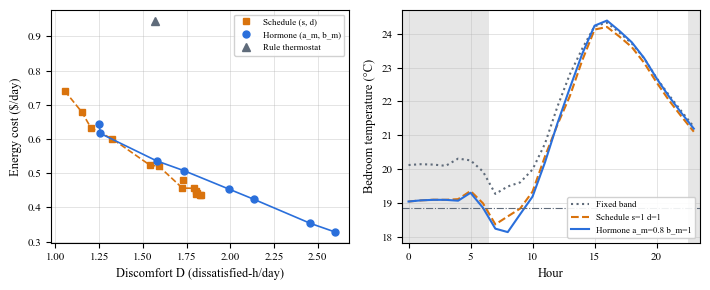


=== KFQL (fixed comfort band) vs rule thermostat with 2-h recovery start ===
Day              Rule cost  KFQL cost  dCost %  Rule D  KFQL D    dD %  PV->heat rule/KFQL  Seeds better on both
10 Feb (tuning)      0.946      0.740    -21.7   1.572   1.053   -33.0        9.1/ 15.9              10/10
09 Feb               1.518      1.180    -22.2   2.201   1.181   -46.3       10.6/ 20.7              10/10
11 Feb               0.790      0.730     -7.6   1.700   1.017   -40.1        9.8/ 15.2              10/10
12 Feb               0.615      0.400    -34.9   0.979   0.999     2.0        5.2/ 12.2               3/10
13 Feb               2.270      2.262     -0.4   1.806   1.648    -8.8        5.5/  7.0              10/10
14 Feb               2.910      2.324    -20.1   3.335   1.612   -51.7       12.6/ 26.1              10/10
15 Feb               2.324      2.100     -9.7   3.505   1.609   -54.1       15.3/ 27.3              10/10
16 Feb               1.370      1.214    -11.4   2.353   1.1

In [11]:
# =====================================================================================
# T-C  |  Thermal experiment: analysis (from the cache; no simulation)
#
#  Pre-stated test: the hormone family counts as BETTER only if the hormone configuration chosen
#  on the tuning day (lowest matched-comfort cost) also costs less than the schedule family's
#  cost-comfort frontier, at the same PMV/PPD discomfort, with a 95% CI excluding zero on at
#  least 4 of the 5 held-out days.
# =====================================================================================
import numpy as np
import matplotlib.pyplot as plt

N_BOOT_T = 2000
rng_t = np.random.default_rng(7)
SCHED = [k for k, v in T_CONFIGS.items() if v["mode"] == "schedule"]
HORM  = [k for k, v in T_CONFIGS.items() if v["mode"] == "hormone"]

def runs(day, label):
    if label == "Rule thermostat":
        return [TH[th_key(day, label, 0)]]
    return [TH[th_key(day, label, s)] for s in T_SEEDS]

def mstat(day, label, key, idx=None):
    rr = runs(day, label)
    if idx is not None and label != "Rule thermostat":
        rr = [rr[i] for i in idx]
    return float(np.mean([r[key] for r in rr]))

def frontier(day, labels, idx=None):
    """Lower-left Pareto frontier (discomfort D ascending, cost descending) of a family."""
    pts = sorted((mstat(day, l, "D", idx), mstat(day, l, "cost", idx), l) for l in labels)
    front = []
    for d, c, l in pts:
        if not front or c < front[-1][1] - 1e-12:
            front.append((d, c, l))
    return front

def matched_cost_gap(day, hlabel, idx=None):
    """Schedule-frontier cost at the hormone config's discomfort minus the hormone config's cost.
       > 0: hormone is cheaper at equal comfort. NaN when the hormone point lies outside the
       frontier's discomfort range (no like-for-like comparison possible)."""
    fr = frontier(day, SCHED, idx)
    xs = np.array([f[0] for f in fr]); ys = np.array([f[1] for f in fr])
    d_h, c_h = mstat(day, hlabel, "D", idx), mstat(day, hlabel, "cost", idx)
    inside = len(xs) > 1 and xs[0] <= d_h <= xs[-1]
    if not inside:
        return np.nan, False
    return float(np.interp(d_h, xs, ys)) - c_h, True

def gap_ci(day, hlabel):
    est, inside = matched_cost_gap(day, hlabel)
    if not inside:
        return np.nan, np.nan, np.nan, False
    n = len(T_SEEDS)
    boots = np.array([matched_cost_gap(day, hlabel, rng_t.integers(0, n, n))[0] for _ in range(N_BOOT_T)])
    boots = boots[~np.isnan(boots)]
    if len(boots) < 0.8 * N_BOOT_T:          # point leaves the frontier range too often: not reliable
        return est, np.nan, np.nan, True
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return est, lo, hi, True

# ---------------- 1) tuning-day table ----------------
def tms(day, label, key):
    v = np.array([r[key] for r in runs(day, label)])
    return f"{v.mean():6.3f} ± {v.std(ddof=1) if len(v) > 1 else 0:5.3f}"

print(f"=== Thermal experiment, {TUNE_DAY}  (last {T_CONV} episodes, {len(T_SEEDS)} seeds) ===")
hdr = f"{'Controller':<28s} {'Cost ($/day)':>16s} {'Grid imp (kWh)':>16s} {'Heating (kWh)':>16s} {'PV->heat':>9s} {'Discomfort D':>16s} {'|PMV|>0.5 h':>12s}"
print(hdr); print("-" * len(hdr))
for lab in ["Rule thermostat"] + SCHED + HORM:
    print(f"{lab:<28s} {tms(TUNE_DAY, lab, 'cost'):>16s} {tms(TUNE_DAY, lab, 'grid_import'):>16s} "
          f"{tms(TUNE_DAY, lab, 'heat_kwh'):>16s} {mstat(TUNE_DAY, lab, 'pv_heat'):9.2f} "
          f"{tms(TUNE_DAY, lab, 'D'):>16s} {mstat(TUNE_DAY, lab, 'H05'):12.1f}")
print("D = excess dissatisfied-hours: sum over occupied room-hours of (PPD - 5%)/100, ISO 7730 PMV/PPD")
print("    (awake 1.1 met / 1.0 clo; asleep 0.8 met / SLEEP_CLO). Cost includes restoring start temperatures.")

# ---------------- 2) matched-comfort test ----------------
print("\n=== Matched-comfort cost gap: schedule frontier minus hormone config ($/day; > 0 = hormone cheaper) ===")
gaps = {}
for day in T_DAYS:
    for hl in HORM:
        gaps[(day, hl)] = gap_ci(day, hl)
def _sym(g):
    e, lo, hi, ins = g
    if not ins: return "."
    if np.isfinite(lo) and lo > 0: return "+"
    if np.isfinite(hi) and hi < 0: return "-"
    return "0"
print("Symbols: + hormone significantly cheaper | - significantly dearer | 0 no significant difference | . outside range")
short = {d: d.replace(" (tuning)", "*") for d in T_DAYS}
print(f"{'Config':<26s}" + "".join(f"{short[d]:>9s}" for d in T_DAYS))
for hl in HORM:
    print(f"{hl:<26s}" + "".join(f"{_sym(gaps[(d, hl)]):>9s}" for d in T_DAYS))
print("(* = tuning day)")
print("'outside range' = the hormone point is less (or more) comfortable than any schedule setting; no matched comparison.")

# dominance check: is a hormone config beaten on BOTH cost and comfort by some schedule config?
print("\nDominated by a schedule config on BOTH cost and discomfort (tuning day):")
for hl in HORM:
    dh, ch = mstat(TUNE_DAY, hl, "D"), mstat(TUNE_DAY, hl, "cost")
    dom = [s for s in SCHED if mstat(TUNE_DAY, s, "D") <= dh and mstat(TUNE_DAY, s, "cost") <= ch]
    print(f"  {hl:<26s} {'yes, by ' + ', '.join(dom) if dom else 'no'}")

# ---------------- 3) pre-stated decision ----------------
inside_tune = [h for h in HORM if gaps[(TUNE_DAY, h)][3]]
test_days = [d for d in T_DAYS if d != TUNE_DAY]
if not inside_tune:
    best_h = HORM[0]
    verdict = "NOT COMPARABLE: no hormone setting falls inside the schedule frontier's comfort range on the tuning day."
    print("\n" + verdict)
else:
    best_h = max(inside_tune, key=lambda h: gaps[(TUNE_DAY, h)][0])
    wins = sum(1 for d in test_days if gaps[(d, best_h)][3] and np.isfinite(gaps[(d, best_h)][1]) and gaps[(d, best_h)][1] > 0)
    losses = sum(1 for d in test_days if gaps[(d, best_h)][3] and np.isfinite(gaps[(d, best_h)][2]) and gaps[(d, best_h)][2] < 0)
    n_test = len(test_days); need = int(np.ceil(0.8 * n_test))
    print(f"\nHormone config selected on the tuning day: {best_h}  (gap {gaps[(TUNE_DAY, best_h)][0]:+.3f} $/day)")
    for d in test_days:
        e, lo, hi, ins = gaps[(d, best_h)]
        print(f"   {d:<8s} " + (f"{e:+.3f} $/day  95% CI [{lo:+.3f}, {hi:+.3f}]" if ins else "outside range"))
    print(f"Held-out days where it is significantly cheaper at matched comfort: {wins}/{n_test}; "
          f"significantly dearer: {losses}/{n_test}  (positive/negative verdict needs {need}/{n_test})")
    if wins >= need:
        verdict = "POSITIVE: circadian comfort weighting beats a tuned step schedule at equal PMV comfort."
    elif losses >= need:
        verdict = "NEGATIVE: a tuned step schedule achieves the same PMV comfort at lower cost."
    else:
        verdict = "NO CLEAR DIFFERENCE: circadian weighting and a tuned step schedule are statistically indistinguishable."
    print("VERDICT:", verdict)

# ---------------- 4) figure ----------------
C_S, C_H, C_N = "#d9730d", "#2a6fdb", "#5f6b7a"
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.0))
ax = axes[0]
for labels, col, mk, name in [(SCHED, C_S, "s", "Schedule (s, d)"), (HORM, C_H, "o", "Hormone (a_m, b_m)")]:
    D_ = [mstat(TUNE_DAY, l, "D") for l in labels]; C_ = [mstat(TUNE_DAY, l, "cost") for l in labels]
    ax.plot(D_, C_, ls="none", marker=mk, ms=5, color=col, label=name)
    fr = frontier(TUNE_DAY, labels)
    ax.plot([f[0] for f in fr], [f[1] for f in fr], color=col, lw=1.2, ls="--" if labels is SCHED else "-")
ax.plot(mstat(TUNE_DAY, "Rule thermostat", "D"), mstat(TUNE_DAY, "Rule thermostat", "cost"),
        marker="^", ms=6, ls="none", color=C_N, label="Rule thermostat")
ax.set_xlabel("Discomfort D (dissatisfied-h/day)", fontsize=9); ax.set_ylabel("Energy cost ($/day)", fontsize=9)
ax.tick_params(labelsize=8); ax.grid(True, lw=0.4, alpha=0.6); ax.legend(fontsize=6.5, framealpha=0.9)

ax = axes[1]
best_s = min(SCHED, key=lambda s: abs(mstat(TUNE_DAY, s, "D") - mstat(TUNE_DAY, best_h, "D")))   # same comfort level
zi = 1   # bedroom
for lab, col, ls in [("Fixed band", C_N, ":"), (best_s, C_S, "--"), (best_h, C_H, "-")]:
    Tp = np.mean([r["T_profile"][zi] for r in runs(TUNE_DAY, lab)], axis=0)
    ax.plot(np.arange(24), Tp, color=col, ls=ls, lw=1.5, label=lab)
occ = ZONES[zi]["occ"] > 0
for h in np.arange(24)[occ]:
    ax.axvspan(h - 0.5, h + 0.5, color="#e6e6e6", lw=0, zorder=0)
ax.axhline(neutral_T("sleep"), color=C_N, lw=0.8, ls="-.")
ax.set_xlim(-0.5, 23.5); ax.set_xlabel("Hour", fontsize=9); ax.set_ylabel("Bedroom temperature (°C)", fontsize=9)
ax.tick_params(labelsize=8); ax.grid(True, lw=0.4, alpha=0.6); ax.legend(fontsize=6.5, framealpha=0.9)
fig.tight_layout()
for ext in ("png", "eps"):
    try:
        save_figure(f"alamg22.{ext}")
    except Exception:
        plt.savefig(f"alamg22.{ext}", dpi=300)
plt.show()


# ---------------- 5) KFQL (fixed comfort band) vs rule thermostat, every day ----------------
print("\n=== KFQL (fixed comfort band) vs rule thermostat with 2-h recovery start ===")
print(f"{'Day':<16s} {'Rule cost':>9s} {'KFQL cost':>10s} {'dCost %':>8s} {'Rule D':>7s} {'KFQL D':>7s} {'dD %':>7s} "
      f"{'PV->heat rule/KFQL':>19s} {'Seeds better on both':>21s}")
for d in T_DAYS:
    rc, rd = mstat(d, "Rule thermostat", "cost"), mstat(d, "Rule thermostat", "D")
    kc = np.array([r["cost"] for r in runs(d, "Fixed band")]); kd = np.array([r["D"] for r in runs(d, "Fixed band")])
    both = int(np.sum((kc < rc) & (kd < rd)))
    print(f"{d:<16s} {rc:9.3f} {kc.mean():10.3f} {100 * (kc.mean() - rc) / rc:8.1f} {rd:7.3f} {kd.mean():7.3f} "
          f"{100 * (kd.mean() - rd) / rd:7.1f} {mstat(d, 'Rule thermostat', 'pv_heat'):10.1f}/{mstat(d, 'Fixed band', 'pv_heat'):5.1f} "
          f"{both:>15d}/{len(T_SEEDS)}")


In [12]:
# =====================================================================================
# T-D  |  Thermal sensitivity checks on the tuning day (run after T-C)
#
#  Are the two thermal findings artefacts of assumed parameters?
#    (1) KFQL beats the rule thermostat on cost AND comfort
#    (2) hormone-shaped comfort weighting is no better than a tuned step schedule at matched comfort
#  Scenarios (one change at a time, everything else as in T-A):
#    sleep insulation 2.5 clo (instead of 3.0) | room thermal resistance R -30% / +30%
#    room thermal capacitance C -30% / +30%
#  About 5 x 221 runs (~20-35 min). Cached in the same file as T-B; resumable.
# =====================================================================================
import copy

SENS_DAY = TUNE_DAY
SCENARIOS = {
    "Sleep insulation 2.5 clo": dict(clo=2.5),
    "R -30% (leakier rooms)":   dict(R=0.7),
    "R +30% (better insulated)": dict(R=1.3),
    "C -30% (lighter rooms)":   dict(C=0.7),
    "C +30% (heavier rooms)":   dict(C=1.3),
}
_BASE_ZONES = copy.deepcopy(ZONES)
_BASE_CLO = SLEEP_CLO

def _set_comfort_tables(clo):
    global SLEEP_CLO
    SLEEP_CLO = clo
    COMFORT_CLASS["sleep"] = dict(met=0.8, clo=clo)
    for k_, c_ in COMFORT_CLASS.items():
        r_ = np.array([pmv_ppd(t, t, 0.1, 40.0, c_["met"], c_["clo"]) for t in _TGRID])
        PMV_TAB[k_], PPD_TAB[k_] = r_[:, 0], r_[:, 1]

def _apply(name, sc):
    global T_SCENARIO
    T_SCENARIO = "base" if name == "base" else name
    for z, zb in zip(ZONES, _BASE_ZONES):
        z["R"] = zb["R"] * sc.get("R", 1.0)
        z["C"] = zb["C"] * sc.get("C", 1.0)
    _set_comfort_tables(sc.get("clo", _BASE_CLO))

def _summary(day):
    rc, rd = mstat(day, "Rule thermostat", "cost"), mstat(day, "Rule thermostat", "D")
    kc, kd = mstat(day, "Fixed band", "cost"), mstat(day, "Fixed band", "D")
    g = gap_ci(day, best_h)
    ins = [h for h in HORM if matched_cost_gap(day, h)[1]]
    cheaper = dearer = 0
    for h in ins:
        e, lo, hi, _ = gap_ci(day, h)
        cheaper += int(np.isfinite(lo) and lo > 0); dearer += int(np.isfinite(hi) and hi < 0)
    dominated = sum(1 for h in HORM if any(mstat(day, s, "D") <= mstat(day, h, "D") and
                                            mstat(day, s, "cost") <= mstat(day, h, "cost") for s in SCHED))
    return dict(rc=rc, rd=rd, kc=kc, kd=kd, gap=g, n_in=len(ins), cheaper=cheaper, dearer=dearer, dom=dominated)

results_sens = {}
try:
    _apply("base", {})
    results_sens["Baseline (as T-A)"] = _summary(SENS_DAY)
    for name, sc in SCENARIOS.items():
        _apply(name, sc)
        t0 = time.perf_counter()
        th_run(SENS_DAY, "Rule thermostat", 0, policy="rule")
        for label in T_CONFIGS:
            for s in T_SEEDS:
                th_run(SENS_DAY, label, s)
        results_sens[name] = _summary(SENS_DAY)
        print(f"  {name:<28s} done ({time.perf_counter() - t0:6.1f} s)")
finally:
    _apply("base", {})          # always restore the T-A settings

print(f"\n=== Sensitivity on {SENS_DAY}: hormone setting tested = {best_h} (selected in T-C) ===")
print(f"{'Scenario':<28s} {'KFQL vs rule: dCost':>20s} {'dDiscomfort':>12s} {'Matched gap $/day [95% CI]':>30s} "
      f"{'In range':>9s} {'+ / -':>7s} {'Dominated':>10s}")
for name, r in results_sens.items():
    e, lo, hi, ins = r["gap"]
    gap_s = f"{e:+.3f} [{lo:+.3f},{hi:+.3f}]" if ins and np.isfinite(lo) else ("outside range" if not ins else f"{e:+.3f} [n/a]")
    print(f"{name:<28s} {100 * (r['kc'] - r['rc']) / r['rc']:19.1f}% {100 * (r['kd'] - r['rd']) / r['rd']:11.1f}% "
          f"{gap_s:>30s} {r['n_in']:>5d}/{len(HORM)} {r['cheaper']:>3d}/{r['dearer']:<3d} {r['dom']:>6d}/{len(HORM)}")
print("dCost/dDiscomfort: KFQL fixed-band vs rule thermostat (negative = KFQL better).")
print("Matched gap > 0: the selected hormone setting is cheaper than the schedule frontier at equal PMV comfort.")
print("+ / -: hormone settings (inside the frontier's range) significantly cheaper / dearer at matched comfort.")
print("Dominated: hormone settings beaten by some schedule setting on BOTH cost and discomfort.")


  Sleep insulation 2.5 clo     done (   1.9 s)
  R -30% (leakier rooms)       done (   1.9 s)
  R +30% (better insulated)    done (   1.9 s)
  C -30% (lighter rooms)       done (   2.6 s)
  C +30% (heavier rooms)       done (   1.9 s)

=== Sensitivity on 10 Feb (tuning): hormone setting tested = Hormone a_m=0.8 b_m=1 (selected in T-C) ===
Scenario                      KFQL vs rule: dCost  dDiscomfort     Matched gap $/day [95% CI]  In range   + / -  Dominated
Baseline (as T-A)                          -21.7%       -33.0%         +0.002 [-0.016,+0.027]     4/8   0/1        4/8
Sleep insulation 2.5 clo                   -21.7%       -28.0%         +0.001 [-0.016,+0.023]     4/8   0/0        3/8
R -30% (leakier rooms)                     -18.4%       -45.8%         -0.005 [-0.027,+0.017]     4/8   0/1        1/8
R +30% (better insulated)                  -28.2%       -12.0%         -0.036 [-0.051,-0.023]     4/8   0/3        3/8
C -30% (lighter rooms)                     -21.3%       -14.

In [37]:
# β check: reward-only variant with large melatonin weights (30 runs, separate cache)
import pickle, numpy as np

_saved = dict(CACHE_FILE=CACHE_FILE, RES=RES, beta=melatonin_factor)
CACHE_FILE, RES = "beta_check.pkl", {}             # keep real results separate
BETA_RESULTS = {}
try:
    for b in [5.0, 15.0, 25.0]:
        melatonin_factor = b                        # global used in every reward function
        RES = {}                                    # β is not in the cache key -> fresh dict per β
        CACHE_FILE = f"beta_check_{b:g}.pkl"
        BETA_RESULTS[b] = run_variant(f"Reward-only, beta = {b:g}",
                                      modulation_mode="hormone_fixed_setpoint",
                                      update_mode="qlearning", mel_model="cos", cor_model="car")
finally:
    melatonin_factor = _saved["beta"]               # restore 0.75
    CACHE_FILE, RES = _saved["CACHE_FILE"], _saved["RES"]
print("restored beta =", melatonin_factor)

# compare with saved KFQL-None and setback curve (converged policy)
_d = pickle.load(open("service_results.pkl", "rb"))
def _get(mode, **extra):
    return [r for k, r in _d.items() if k[0] == "Baseline" and k[1] == "Day27"
            and dict(k[4]).get("modulation_mode") == mode and not dict(k[4]).get("stochastic")
            and dict(k[4]).get("update_mode") == "qlearning"
            and all(dict(k[4]).get(a) == v for a, v in extra.items())]
none = _get("none")
curve = [none] + [_get("none_night_reduction", night_reduction=c) for c in [0.25, 0.5, 0.75, 1.0]]
cx = np.array([np.mean([r["conv"]["U"] for r in rr]) for rr in curve])
cy = np.array([np.mean([r["conv"]["appliance"] for r in rr]) for rr in curve])
o = np.argsort(cx); cx, cy = cx[o], cy[o]
E0 = np.mean([r["conv"]["appliance"] for r in none]); U0 = np.mean([r["conv"]["U"] for r in none])
print(f"KFQL-None: E={E0:.2f}, U={U0:.2f}")
for b, rr in BETA_RESULTS.items():
    E = np.mean([r["conv"]["appliance"] for r in rr]); U = np.mean([r["conv"]["U"] for r in rr])
    gap = E - np.interp(U, cx, cy) if cx.min() <= U <= cx.max() else np.nan
    print(f"beta={b:>4g}: E={E:.2f} (saves {E0-E:+.2f}), U={U:.2f} (extra {U-U0:+.2f}), "
          f"vs setback at equal U: {gap:+.2f} kWh/day (>0 = setback better)")

  Reward-only, beta = 5                  10 runs  ( 222.5 s)
  Reward-only, beta = 15                 10 runs  ( 228.3 s)
  Reward-only, beta = 25                 10 runs  ( 223.1 s)
restored beta = 0.75
KFQL-None: E=74.39, U=1.20
beta=   5: E=74.26 (saves +0.13), U=1.33 (extra +0.13), vs setback at equal U: +0.01 kWh/day (>0 = setback better)
beta=  15: E=73.78 (saves +0.61), U=1.79 (extra +0.59), vs setback at equal U: -0.01 kWh/day (>0 = setback better)
beta=  25: E=73.15 (saves +1.24), U=2.40 (extra +1.20), vs setback at equal U: -0.01 kWh/day (>0 = setback better)
